In [1]:
print("hellow world!")

hellow world!


Original dataset shape: (2452, 9)

FORESIGHT MONTHLY FORECASTING DATA AUDIT
Original transactions: 2452
Expense transactions: 2173
Consumption transactions: 1996
Number of months: 48
Start month: 2015-01
End month: 2018-12
Missing monthly values: 0
Zero-spending months: 0
Total consumption: ₹936,993.63
Average monthly spending: ₹19,520.70
Minimum monthly spending: ₹1,343.00
Maximum monthly spending: ₹110,603.58


,Month,Total_Spending
0,2015-01,15144.00
1,2015-02,18919.00
2,2015-03,19253.80
3,2015-04,4806.00
4,2015-05,17603.00
5,2015-06,1343.00
6,2015-07,11115.00
7,2015-08,9624.00
8,2015-09,5185.00
9,2015-10,8604.60


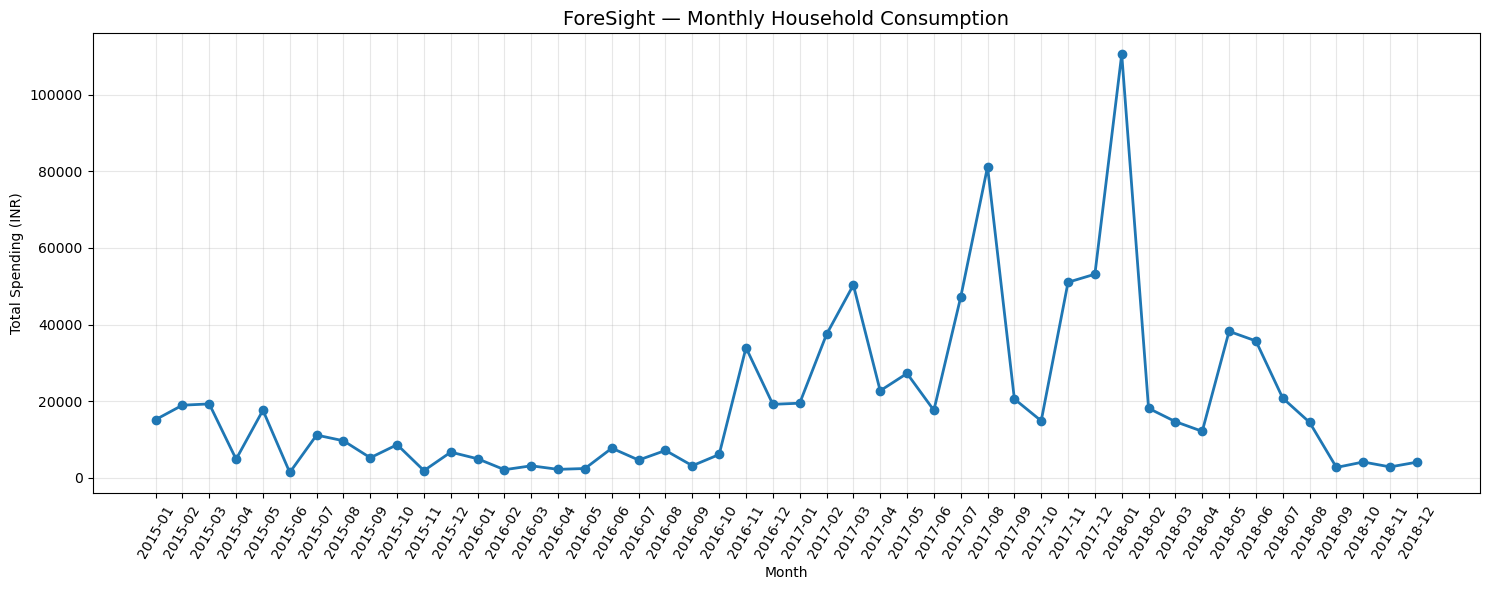

In [2]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# STEP 1: LOAD AND PREPARE MONTHLY SPENDING DATA
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# ------------------------------------------------------------
# 1. LOAD CLEANED TRANSACTION DATASET
# ------------------------------------------------------------

possible_paths = [
    Path("../data/processed/cleaned_household_transactions.csv"),
    Path("data/processed/cleaned_household_transactions.csv")
]

DATA_PATH = next(
    (path for path in possible_paths if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find cleaned_household_transactions.csv. "
        "Check your project folder structure."
    )

df = pd.read_csv(DATA_PATH)

# Restore appropriate data types
df["Date"] = pd.to_datetime(
    df["Date"], errors="coerce"
)

df["Amount"] = pd.to_numeric(
    df["Amount"], errors="coerce"
)

print("Original dataset shape:", df.shape)

# ------------------------------------------------------------
# 2. SELECT HOUSEHOLD CONSUMPTION TRANSACTIONS
# SAME FILTERING AS NOTEBOOK 04
# ------------------------------------------------------------

expense_df = df[
    df["Income/Expense"] == "Expense"
].copy()

financial_categories_strict = [
    "Money transfer",
    "Investment",
    "Public Provident Fund",
    "Recurring Deposit"
]

excluded_notes = [
    "Public Provident Fund",
    "Permanent Residence money transfer"
]

household_df = expense_df[
    (~expense_df["Category"].isin(
        financial_categories_strict
    )) &
    (~expense_df["Note"].isin(excluded_notes))
].copy()

household_df = household_df.dropna(
    subset=["Date", "Amount", "Category"]
)

# ------------------------------------------------------------
# 3. CREATE MONTHLY SPENDING TARGET
# ------------------------------------------------------------

household_df["Month"] = (
    household_df["Date"].dt.to_period("M")
)

monthly_spending = (
    household_df.groupby("Month")["Amount"]
    .sum()
    .sort_index()
)

# Include every calendar month in the dataset period
all_months = pd.period_range(
    start=household_df["Month"].min(),
    end=household_df["Month"].max(),
    freq="M"
)

monthly_spending = monthly_spending.reindex(
    all_months,
    fill_value=0
)

# Name the target series
monthly_spending.name = "Total_Spending"

# ------------------------------------------------------------
# 4. DISPLAY DATASET AUDIT
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("FORESIGHT MONTHLY FORECASTING DATA AUDIT")
print("=" * 55)

print("Original transactions:", len(df))
print("Expense transactions:", len(expense_df))
print("Consumption transactions:", len(household_df))

print("Number of months:", len(monthly_spending))
print("Start month:", monthly_spending.index.min())
print("End month:", monthly_spending.index.max())

print("Missing monthly values:", monthly_spending.isna().sum())
print("Zero-spending months:", (monthly_spending == 0).sum())

print(
    "Total consumption:",
    f"₹{monthly_spending.sum():,.2f}"
)

print(
    "Average monthly spending:",
    f"₹{monthly_spending.mean():,.2f}"
)

print(
    "Minimum monthly spending:",
    f"₹{monthly_spending.min():,.2f}"
)

print(
    "Maximum monthly spending:",
    f"₹{monthly_spending.max():,.2f}"
)

# ------------------------------------------------------------
# 5. DISPLAY MONTHLY SPENDING SERIES
# ------------------------------------------------------------

monthly_spending_df = (
    monthly_spending
    .rename_axis("Month")
    .reset_index()
)

monthly_spending_df["Month"] = (
    monthly_spending_df["Month"].astype(str)
)

display(monthly_spending_df)

# ------------------------------------------------------------
# 6. VISUALIZE MONTHLY SPENDING
# ------------------------------------------------------------

plt.figure(figsize=(15, 6))

plt.plot(
    monthly_spending_df["Month"],
    monthly_spending_df["Total_Spending"],
    marker="o",
    linewidth=2
)

plt.title(
    "ForeSight — Monthly Household Consumption",
    fontsize=14
)

plt.xlabel("Month")
plt.ylabel("Total Spending (INR)")

plt.xticks(rotation=60)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Monthly EDA dataset:


,Total_Spending,Transaction_Count,Average_Transaction,Median_Transaction,Year,Month_Number
2015-01,15144.0,67,226.029851,50.0,2015,1
2015-02,18919.0,48,394.145833,32.0,2015,2
2015-03,19253.8,41,469.604878,53.0,2015,3
2015-04,4806.0,20,240.300000,112.0,2015,4
2015-05,17603.0,22,800.136364,117.5,2015,5
2015-06,1343.0,8,167.875000,20.0,2015,6
2015-07,11115.0,6,1852.500000,225.0,2015,7
2015-08,9624.0,13,740.307692,156.0,2015,8
2015-09,5185.0,18,288.055556,139.5,2015,9
2015-10,8604.6,35,245.845714,70.0,2015,10



SPENDING DISTRIBUTION ANALYSIS
count        48.000000
mean      19520.700625
std       21741.368129
min        1343.000000
25%        4751.250000
50%       14534.200000
75%       21244.690000
max      110603.580000
Name: Total_Spending, dtype: float64

Coefficient of Variation: 111.38%

YEAR-WISE SPENDING SUMMARY


,Total_Spending,Average_Monthly_Spending,Average_Transactions,YoY_Change_Percent
Year,,,,
2015,120074.40,10006.20,26.42,NaN
2016,96226.20,8018.85,20.17,-19.86
2017,442564.67,36880.39,72.92,359.92
2018,278128.36,23177.36,46.83,-37.16



MONTH-OF-YEAR SPENDING PATTERN


,Average_Spending,Median_Spending,Spending_Std,Observations
January,37526.90,17292.00,49096.98,4
February,19127.25,18514.00,14452.32,4
March,21821.52,16939.78,20179.07,4
April,10437.42,8450.00,9186.45,4
May,21354.25,22411.50,15195.97,4
June,15578.00,12634.00,14987.36,4
July,20903.11,15938.68,18715.79,4
August,28092.34,12033.32,35535.61,4
September,7873.00,4145.00,8517.40,4
October,8388.82,7322.90,4674.09,4



POTENTIAL UNUSUAL MONTHS
Lower IQR boundary: -19988.91
Upper IQR boundary: 45984.85


,Total_Spending,Transaction_Count,Average_Transaction
2017-03,50320.52,87,578.40
2017-07,47148.10,67,703.70
2017-08,81199.70,74,1097.29
2017-11,51039.60,91,560.87
2017-12,53140.00,73,727.95
2018-01,110603.58,80,1382.54



TOP 10 HIGHEST SPENDING MONTHS


,Total_Spending,Transaction_Count,Average_Transaction
2018-01,110603.58,80,1382.54
2017-08,81199.70,74,1097.29
2017-12,53140.00,73,727.95
2017-11,51039.60,91,560.87
2017-03,50320.52,87,578.40
2017-07,47148.10,67,703.70
2018-05,38214.00,56,682.39
2017-02,37415.00,66,566.89
2018-06,35701.02,58,615.53
2016-11,33947.00,44,771.52


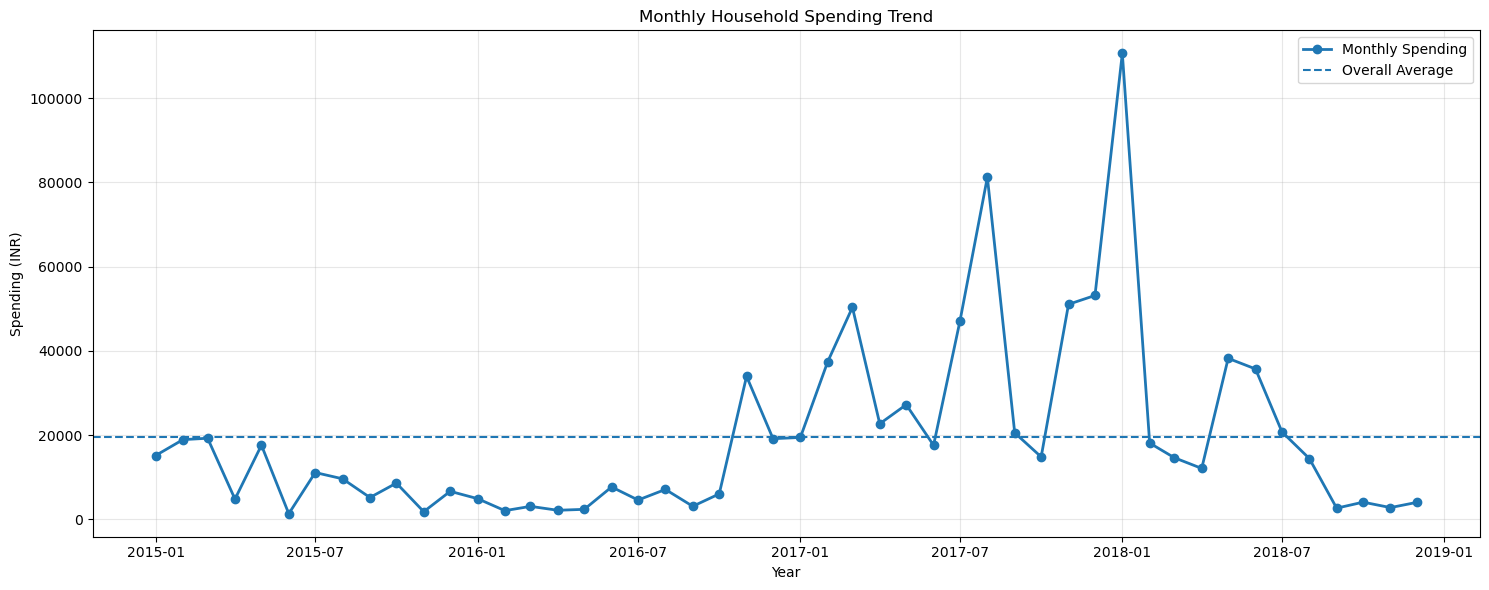

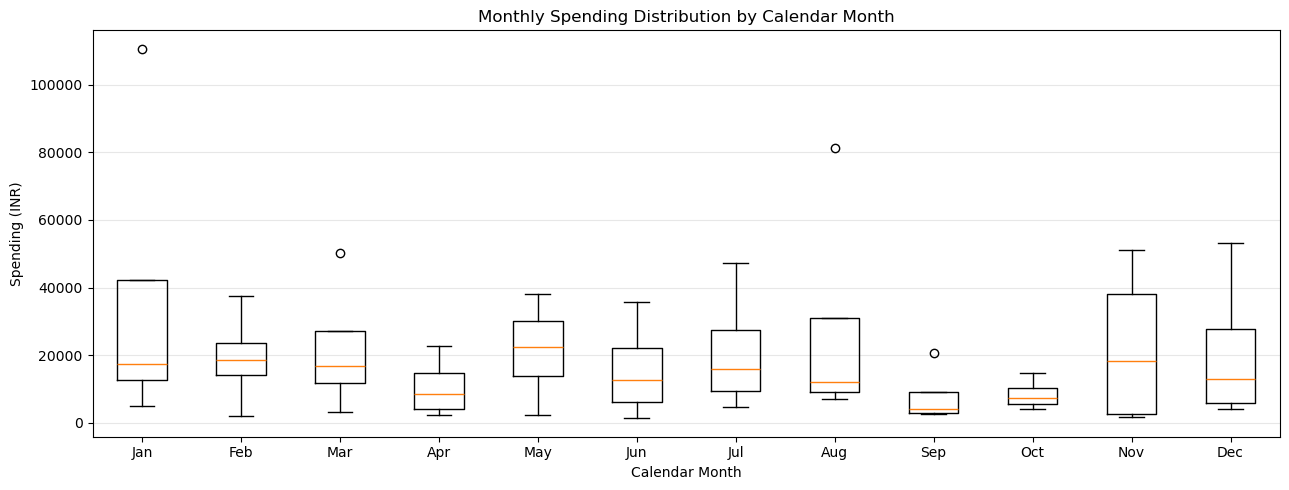

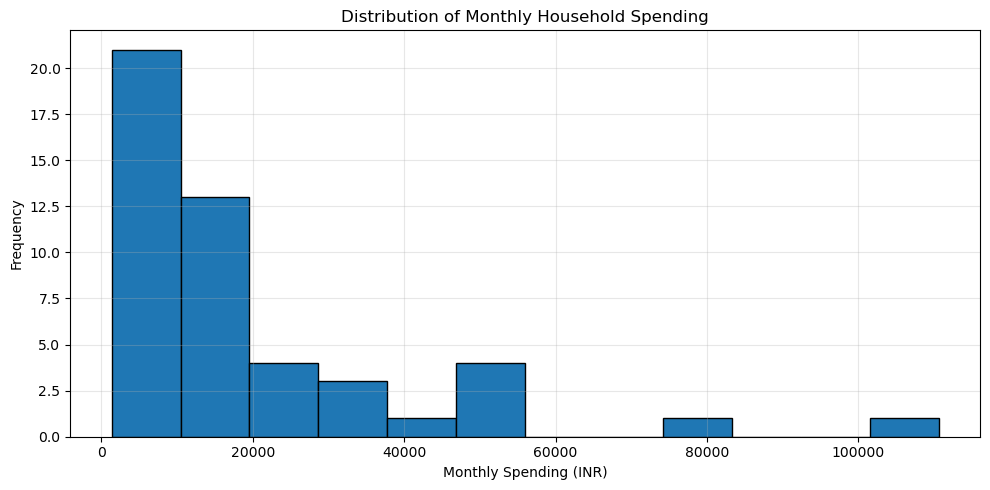

In [3]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# STEP 2: FORECASTING-SPECIFIC EXPLORATORY DATA ANALYSIS
# ============================================================

# ------------------------------------------------------------
# 1. CREATE MONTHLY ANALYSIS DATAFRAME
# ------------------------------------------------------------

monthly_eda = household_df.groupby("Month").agg(
    Total_Spending=("Amount", "sum"),
    Transaction_Count=("Amount", "count"),
    Average_Transaction=("Amount", "mean"),
    Median_Transaction=("Amount", "median")
)

monthly_eda = monthly_eda.reindex(
    monthly_spending.index
).fillna(0)

monthly_eda["Year"] = monthly_eda.index.year
monthly_eda["Month_Number"] = monthly_eda.index.month

print("Monthly EDA dataset:")
display(monthly_eda.head(12))

# ------------------------------------------------------------
# 2. SPENDING DISTRIBUTION ANALYSIS
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("SPENDING DISTRIBUTION ANALYSIS")
print("=" * 55)

print(monthly_eda["Total_Spending"].describe())

mean_spending = monthly_eda["Total_Spending"].mean()
std_spending = monthly_eda["Total_Spending"].std()

coefficient_of_variation = (
    std_spending / mean_spending
) * 100

print(
    f"\nCoefficient of Variation: "
    f"{coefficient_of_variation:.2f}%"
)

# ------------------------------------------------------------
# 3. YEAR-WISE SPENDING ANALYSIS
# ------------------------------------------------------------

yearly_summary = monthly_eda.groupby("Year").agg(
    Total_Spending=("Total_Spending", "sum"),
    Average_Monthly_Spending=("Total_Spending", "mean"),
    Average_Transactions=("Transaction_Count", "mean")
)

yearly_summary["YoY_Change_Percent"] = (
    yearly_summary["Total_Spending"].pct_change() * 100
)

print("\nYEAR-WISE SPENDING SUMMARY")
display(yearly_summary.round(2))

# ------------------------------------------------------------
# 4. MONTH-OF-YEAR SEASONALITY ANALYSIS
# ------------------------------------------------------------

seasonal_summary = monthly_eda.groupby(
    "Month_Number"
)["Total_Spending"].agg(
    ["mean", "median", "std", "count"]
)

seasonal_summary.index = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

seasonal_summary = seasonal_summary.rename(columns={
    "mean": "Average_Spending",
    "median": "Median_Spending",
    "std": "Spending_Std",
    "count": "Observations"
})

print("\nMONTH-OF-YEAR SPENDING PATTERN")
display(seasonal_summary.round(2))

# ------------------------------------------------------------
# 5. IDENTIFY UNUSUALLY HIGH OR LOW MONTHS
# ------------------------------------------------------------

Q1 = monthly_eda["Total_Spending"].quantile(0.25)
Q3 = monthly_eda["Total_Spending"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

unusual_months = monthly_eda[
    (monthly_eda["Total_Spending"] < lower_bound) |
    (monthly_eda["Total_Spending"] > upper_bound)
]

print("\nPOTENTIAL UNUSUAL MONTHS")
print("Lower IQR boundary:", round(lower_bound, 2))
print("Upper IQR boundary:", round(upper_bound, 2))

display(
    unusual_months[
        [
            "Total_Spending",
            "Transaction_Count",
            "Average_Transaction"
        ]
    ].round(2)
)

# ------------------------------------------------------------
# 6. IDENTIFY TOP 10 SPENDING MONTHS
# ------------------------------------------------------------

top_spending_months = monthly_eda.nlargest(
    10, "Total_Spending"
)

print("\nTOP 10 HIGHEST SPENDING MONTHS")

display(
    top_spending_months[
        [
            "Total_Spending",
            "Transaction_Count",
            "Average_Transaction"
        ]
    ].round(2)
)

# ------------------------------------------------------------
# 7. VISUALIZE MONTHLY SPENDING TREND
# ------------------------------------------------------------

plt.figure(figsize=(15, 6))

plt.plot(
    monthly_eda.index.to_timestamp(),
    monthly_eda["Total_Spending"],
    marker="o",
    linewidth=2,
    label="Monthly Spending"
)

plt.axhline(
    mean_spending,
    linestyle="--",
    label="Overall Average"
)

plt.title("Monthly Household Spending Trend")
plt.xlabel("Year")
plt.ylabel("Spending (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. VISUALIZE MONTH-OF-YEAR SPENDING PATTERN
# ------------------------------------------------------------

plt.figure(figsize=(13, 5))

plt.boxplot(
    [
        monthly_eda.loc[
            monthly_eda["Month_Number"] == month,
            "Total_Spending"
        ].values
        for month in range(1, 13)
    ],
    tick_labels=[
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ]
)

plt.title("Monthly Spending Distribution by Calendar Month")
plt.xlabel("Calendar Month")
plt.ylabel("Spending (INR)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. VISUALIZE SPENDING DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.hist(
    monthly_eda["Total_Spending"],
    bins=12,
    edgecolor="black"
)

plt.title("Distribution of Monthly Household Spending")
plt.xlabel("Monthly Spending (INR)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Months selected for investigation:
[Period('2017-03', 'M'), Period('2017-07', 'M'), Period('2017-08', 'M'), Period('2017-11', 'M'), Period('2017-12', 'M'), Period('2018-01', 'M')]

CATEGORY CONTRIBUTION BY UNUSUAL MONTH


,Month,Category,Amount
9,2017-03,subscription,19943.32
6,2017-03,Household,16294.00
3,2017-03,Food,3660.20
8,2017-03,Transportation,3116.00
2,2017-03,Family,3000.00
...,...,...,...
66,2018-01,subscription,661.00
57,2018-01,Culture,461.00
58,2018-01,Family,400.00
63,2018-01,Social Life,298.00



TOP 30 LARGEST TRANSACTIONS IN UNUSUAL MONTHS


,Date,Category,Subcategory,Note,Amount
608,2018-01-18,Transportation,Bike,Two Wheeler Bikedelux second installment,50000.00
582,2018-01-27,Transportation,Bike,Two Wheeler Bikedelux third installment,43000.00
1076,2017-08-08,Tourism,Trip,Tours and Travel,43000.00
706,2017-12-20,subscription,Edtech Course,Renewal,28400.00
770,2017-11-30,Health,Health,Family's Glasses,22700.00
1132,2017-07-25,Tourism,Trip,Tours and Travel,20000.00
1395,2017-03-05,Household,Kitchen,Gas stove elica 3 burner,8825.00
907,2017-08-10,Gift,Unknown,For Friend,6500.00
1028,2017-08-24,Apparel,Clothing,Jaipuri handprinted Maharani Saree (1850 Two p...,5200.00
1079,2017-07-08,Family,Pocket money,No Note,5000.00



YEARLY TRANSACTION ACTIVITY


,Total_Spending,Total_Transactions,Average_Monthly_Transactions,Average_Transaction_Size
Year,,,,
2015,120074.40,317,26.42,486.21
2016,96226.20,242,20.17,353.04
2017,442564.67,875,72.92,502.37
2018,278128.36,562,46.83,408.16



JANUARY 2018 INVESTIGATION
Transaction count: 80
Total spending: ₹110,603.58
Average transaction: ₹1,382.54

Largest January 2018 transactions:


,Date,Category,Subcategory,Note,Amount
608,2018-01-18,Transportation,Bike,Two Wheeler Bikedelux second installment,50000.0
582,2018-01-27,Transportation,Bike,Two Wheeler Bikedelux third installment,43000.0
566,2018-01-02,maid,Unknown,No Note,2000.0
673,2018-01-01,maid,Unknown,No Note,2000.0
185,2018-01-07,Transportation,Travels,2 Place 2 to Place 1 - Shree Sharma Travels,1890.0
586,2018-01-26,Apparel,Clothing,Pyjama (999)+ carry bag (10),1009.0
580,2018-01-28,Household,Kirana,Smart point,976.9
620,2018-01-14,Household,Hardware,Vibrating electronic message tool,798.0
581,2018-01-28,Household,Kirana,Supermart,764.0
627,2018-01-13,Health,Medicine,Thyroid Tablets,740.0



JANUARY 2018 CATEGORY CONTRIBUTION


,count,sum,mean,Contribution_Percent
Category,,,,
Transportation,14,95444.00,6817.43,86.29
maid,2,4000.00,2000.00,3.62
Household,10,3722.90,372.29,3.37
Food,36,2835.00,78.75,2.56
Apparel,5,1816.00,363.20,1.64
Health,4,935.00,233.75,0.85
subscription,2,661.00,330.50,0.60
Culture,1,461.00,461.00,0.42
Family,3,400.00,133.33,0.36


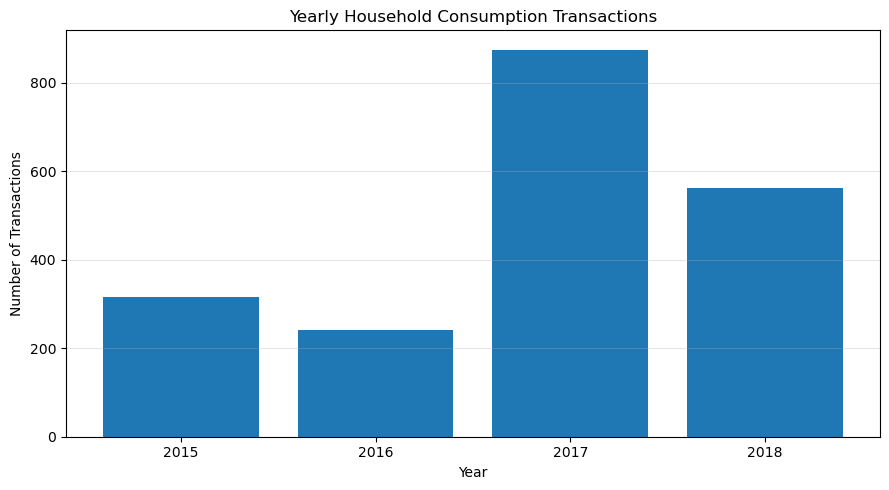

In [4]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# STEP 3: INVESTIGATION OF UNUSUAL SPENDING PERIODS
# ============================================================

# ------------------------------------------------------------
# 1. DEFINE POTENTIAL UNUSUAL MONTHS
# ------------------------------------------------------------

outlier_months = unusual_months.index.tolist()

print("Months selected for investigation:")
print(outlier_months)

# ------------------------------------------------------------
# 2. CATEGORY CONTRIBUTION IN UNUSUAL MONTHS
# ------------------------------------------------------------

outlier_transactions = household_df[
    household_df["Month"].isin(outlier_months)
].copy()

category_contribution = (
    outlier_transactions
    .groupby(["Month", "Category"])["Amount"]
    .sum()
    .reset_index()
    .sort_values(
        ["Month", "Amount"],
        ascending=[True, False]
    )
)

print("\nCATEGORY CONTRIBUTION BY UNUSUAL MONTH")

display(category_contribution)

# ------------------------------------------------------------
# 3. TOP TRANSACTIONS IN UNUSUAL MONTHS
# ------------------------------------------------------------

print("\nTOP 30 LARGEST TRANSACTIONS IN UNUSUAL MONTHS")

top_outlier_transactions = (
    outlier_transactions
    .sort_values("Amount", ascending=False)
    [[
        "Date",
        "Category",
        "Subcategory",
        "Note",
        "Amount"
    ]]
    .head(30)
)

display(top_outlier_transactions)

# ------------------------------------------------------------
# 4. MONTHLY TRANSACTION COUNT VS SPENDING
# ------------------------------------------------------------

monthly_comparison = monthly_eda[
    [
        "Total_Spending",
        "Transaction_Count",
        "Average_Transaction"
    ]
].copy()

monthly_comparison["Year"] = (
    monthly_comparison.index.year
)

yearly_activity = monthly_comparison.groupby(
    "Year"
).agg(
    Total_Spending=("Total_Spending", "sum"),
    Total_Transactions=("Transaction_Count", "sum"),
    Average_Monthly_Transactions=(
        "Transaction_Count", "mean"
    ),
    Average_Transaction_Size=(
        "Average_Transaction", "mean"
    )
)

print("\nYEARLY TRANSACTION ACTIVITY")

display(yearly_activity.round(2))

# ------------------------------------------------------------
# 5. INVESTIGATE JANUARY 2018
# ------------------------------------------------------------

january_2018 = household_df[
    household_df["Month"] == pd.Period("2018-01")
].copy()

print("\nJANUARY 2018 INVESTIGATION")

print("Transaction count:", len(january_2018))

print(
    "Total spending:",
    f"₹{january_2018['Amount'].sum():,.2f}"
)

print(
    "Average transaction:",
    f"₹{january_2018['Amount'].mean():,.2f}"
)

print("\nLargest January 2018 transactions:")

display(
    january_2018.sort_values(
        "Amount", ascending=False
    )[
        [
            "Date",
            "Category",
            "Subcategory",
            "Note",
            "Amount"
        ]
    ].head(20)
)

# ------------------------------------------------------------
# 6. CATEGORY CONTRIBUTION IN JANUARY 2018
# ------------------------------------------------------------

january_category = (
    january_2018.groupby("Category")["Amount"]
    .agg(["count", "sum", "mean"])
    .sort_values("sum", ascending=False)
)

january_category["Contribution_Percent"] = (
    january_category["sum"] /
    january_category["sum"].sum() * 100
)

print("\nJANUARY 2018 CATEGORY CONTRIBUTION")

display(january_category.round(2))

# ------------------------------------------------------------
# 7. VISUALIZE YEARLY TRANSACTION FREQUENCY
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    yearly_activity.index.astype(str),
    yearly_activity["Total_Transactions"]
)

plt.title("Yearly Household Consumption Transactions")
plt.xlabel("Year")
plt.ylabel("Number of Transactions")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Total observations: 48
Training observations: 36
Testing observations: 12
Training period: 2015-01 to 2017-12
Testing period: 2018-01 to 2018-12

BASELINE FORECAST RESULTS


,Actual,Historical_Mean,Naive,Seasonal_Naive,Drift
Month,,,,,
2018-01,110603.58,18301.81,53140.00,19440.00,54225.60
2018-02,18109.00,20796.46,110603.58,37415.00,113255.24
2018-03,14625.75,20725.73,18109.00,50320.52,18189.14
2018-04,12094.00,20569.32,14625.75,22691.68,14612.11
2018-05,38214.00,20357.44,12094.00,27220.00,12015.79
2018-06,35701.02,20792.97,38214.00,17581.60,38790.75
2018-07,20762.36,21147.92,35701.02,47148.10,36202.41
2018-08,14442.65,21138.95,20762.36,81199.70,20896.13
2018-09,2660.00,20986.76,14442.65,20542.00,14426.34



BASELINE MODEL COMPARISON


,Model,MAE,RMSE
0,Historical_Mean,18122.69,29416.07
1,Naive,18466.51,32878.03
2,Drift,18734.24,33380.36
3,Seasonal_Naive,33749.19,41678.91


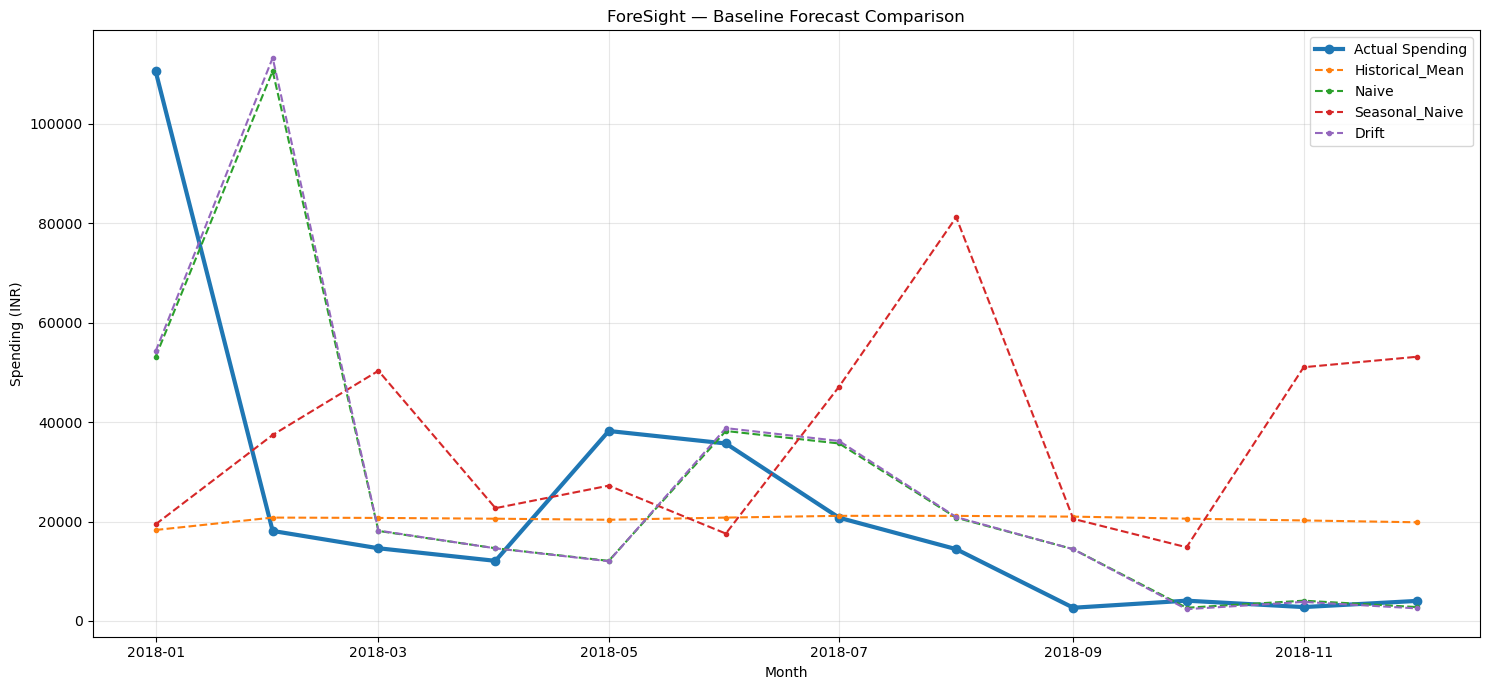

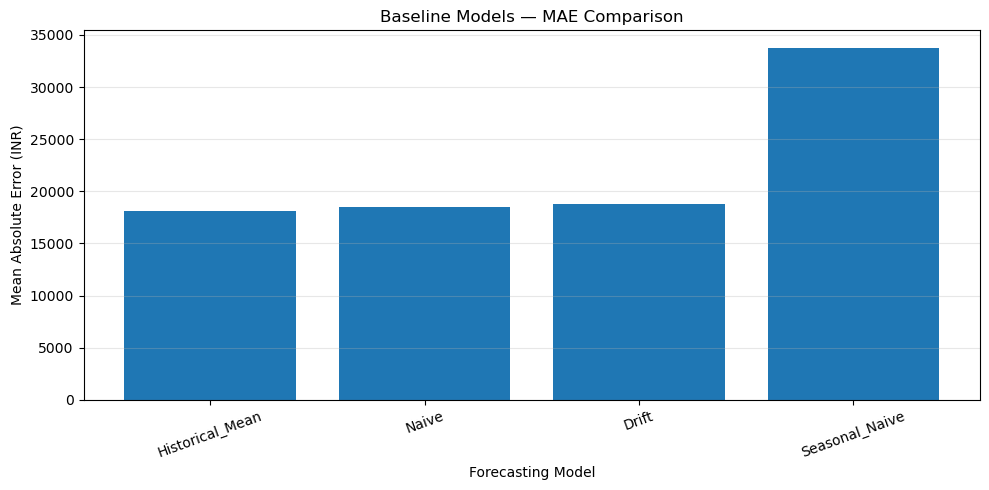

In [5]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# STEP 4: BASELINE FORECASTING EXPERIMENTS
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. DEFINE CHRONOLOGICAL TRAINING AND TEST PERIOD
# ------------------------------------------------------------

FORECAST_HORIZON = 12

y = monthly_spending.copy()

train_size = len(y) - FORECAST_HORIZON

print("Total observations:", len(y))
print("Training observations:", train_size)
print("Testing observations:", FORECAST_HORIZON)

print("Training period:", y.index[0], "to", y.index[train_size - 1])
print("Testing period:", y.index[train_size], "to", y.index[-1])

# ------------------------------------------------------------
# 2. GENERATE EXPANDING-WINDOW ONE-STEP FORECASTS
# ------------------------------------------------------------

forecast_records = []

for i in range(train_size, len(y)):

    # All observations available before the target month
    history = y.iloc[:i]

    actual = y.iloc[i]

    # Baseline 1: Historical Mean
    mean_prediction = history.mean()

    # Baseline 2: Naive Forecast
    naive_prediction = history.iloc[-1]

    # Baseline 3: Seasonal Naive (same month last year)
    seasonal_prediction = history.iloc[-12]

    # Baseline 4: Drift Forecast
    drift_prediction = (
        history.iloc[-1] +
        (history.iloc[-1] - history.iloc[0])
        / (len(history) - 1)
    )

    forecast_records.append({
        "Month": y.index[i],
        "Actual": actual,
        "Historical_Mean": mean_prediction,
        "Naive": naive_prediction,
        "Seasonal_Naive": seasonal_prediction,
        "Drift": drift_prediction
    })

baseline_results = pd.DataFrame(forecast_records)

baseline_results = baseline_results.set_index("Month")

print("\nBASELINE FORECAST RESULTS")

display(baseline_results.round(2))

# ------------------------------------------------------------
# 3. CALCULATE FORECASTING METRICS
# ------------------------------------------------------------

model_columns = [
    "Historical_Mean",
    "Naive",
    "Seasonal_Naive",
    "Drift"
]

metrics = []

for model in model_columns:

    actual_values = baseline_results["Actual"]
    predicted_values = baseline_results[model]

    mae = mean_absolute_error(
        actual_values,
        predicted_values
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual_values,
            predicted_values
        )
    )

    metrics.append({
        "Model": model,
        "MAE": mae,
        "RMSE": rmse
    })

baseline_metrics = pd.DataFrame(metrics)

baseline_metrics = baseline_metrics.sort_values(
    "MAE"
).reset_index(drop=True)

print("\nBASELINE MODEL COMPARISON")

display(baseline_metrics.round(2))

# ------------------------------------------------------------
# 4. VISUALIZE ACTUAL VS BASELINE PREDICTIONS
# ------------------------------------------------------------

plt.figure(figsize=(15, 7))

plt.plot(
    baseline_results.index.to_timestamp(),
    baseline_results["Actual"],
    marker="o",
    linewidth=3,
    label="Actual Spending"
)

for model in model_columns:

    plt.plot(
        baseline_results.index.to_timestamp(),
        baseline_results[model],
        marker=".",
        linestyle="--",
        label=model
    )

plt.title(
    "ForeSight — Baseline Forecast Comparison"
)

plt.xlabel("Month")
plt.ylabel("Spending (INR)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. VISUALIZE MAE COMPARISON
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(
    baseline_metrics["Model"],
    baseline_metrics["MAE"]
)

plt.title("Baseline Models — MAE Comparison")
plt.xlabel("Forecasting Model")
plt.ylabel("Mean Absolute Error (INR)")

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Training period: 2015-01 to 2017-12
Testing period: 2018-01 to 2018-12

ADVANCED FORECAST RESULTS


,Actual,SES,Holt_Linear,Damped_Trend
Month,,,,
2018-01,110603.58,42497.11,50647.13,49899.06
2018-02,18109.00,70361.44,67362.75,66508.70
2018-03,14625.75,48404.36,60585.69,59713.28
2018-04,12094.00,39893.99,52724.10,51860.73
2018-05,38214.00,33354.53,36483.12,35422.89
2018-06,35701.02,34497.64,37420.32,38666.48
2018-07,20762.36,34780.71,37418.40,36635.70
2018-08,14442.65,31483.14,31159.48,31223.57
2018-09,2660.00,27065.39,20350.84,20461.55



ADVANCED MODEL COMPARISON


,Model,MAE,RMSE
0,Holt_Linear,22146.85,29953.30
1,Damped_Trend,22150.25,29730.15
2,SES,23127.24,30028.04



COMPLETE MODEL COMPARISON


,Model,MAE,RMSE
0,Historical_Mean,18122.69,29416.07
1,Naive,18466.51,32878.03
2,Drift,18734.24,33380.36
3,Holt_Linear,22146.85,29953.30
4,Damped_Trend,22150.25,29730.15
5,SES,23127.24,30028.04
6,Seasonal_Naive,33749.19,41678.91


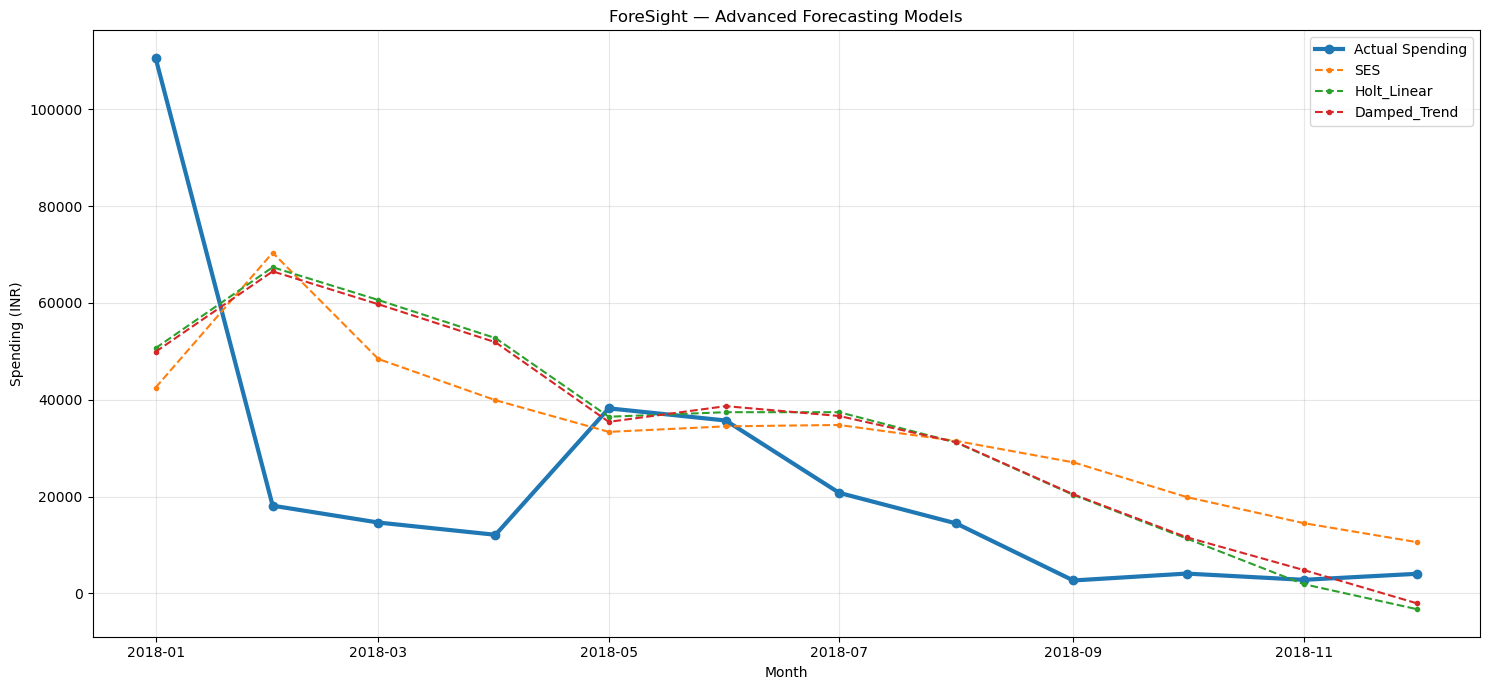

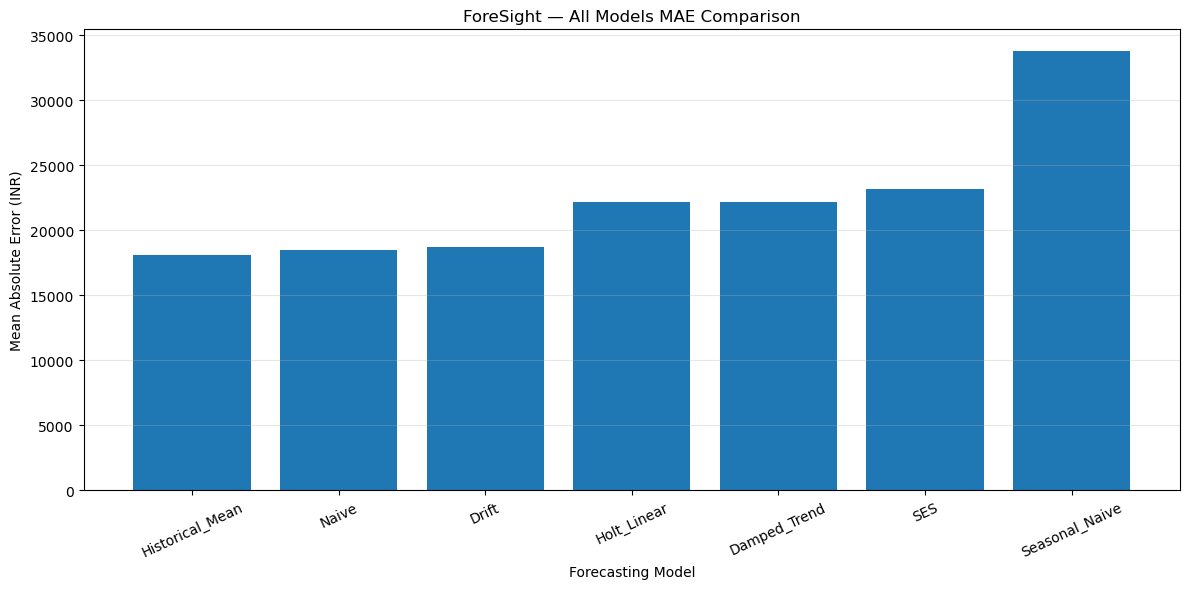


Best model based on MAE:
Historical_Mean
Best MAE: 18122.69


In [6]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# STEP 5: ADVANCED FORECASTING — EXPONENTIAL SMOOTHING
# ============================================================

import warnings
from statsmodels.tsa.holtwinters import (
    SimpleExpSmoothing,
    Holt
)
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. PREPARE THE DATA
# ------------------------------------------------------------

y = monthly_spending.copy()

FORECAST_HORIZON = 12
train_size = len(y) - FORECAST_HORIZON

advanced_records = []

print("Training period:", y.index[0], "to", y.index[train_size - 1])
print("Testing period:", y.index[train_size], "to", y.index[-1])

# ------------------------------------------------------------
# 2. EXPANDING-WINDOW ONE-STEP FORECASTING
# ------------------------------------------------------------

for i in range(train_size, len(y)):

    history = y.iloc[:i]
    actual = y.iloc[i]

    # Model 1: Simple Exponential Smoothing
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        ses_model = SimpleExpSmoothing(
            history,
            initialization_method="estimated"
        ).fit(optimized=True)

        ses_prediction = float(
            ses_model.forecast(1).iloc[0]
        )

    # Model 2: Holt's Linear Trend
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        holt_model = Holt(
            history,
            initialization_method="estimated"
        ).fit(optimized=True)

        holt_prediction = float(
            holt_model.forecast(1).iloc[0]
        )

    # Model 3: Damped Trend
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        damped_model = Holt(
            history,
            damped_trend=True,
            initialization_method="estimated"
        ).fit(optimized=True)

        damped_prediction = float(
            damped_model.forecast(1).iloc[0]
        )

    advanced_records.append({
        "Month": y.index[i],
        "Actual": actual,
        "SES": ses_prediction,
        "Holt_Linear": holt_prediction,
        "Damped_Trend": damped_prediction
    })

# ------------------------------------------------------------
# 3. CREATE RESULTS TABLE
# ------------------------------------------------------------

advanced_results = pd.DataFrame(
    advanced_records
).set_index("Month")

print("\nADVANCED FORECAST RESULTS")

display(advanced_results.round(2))

# ------------------------------------------------------------
# 4. CALCULATE PERFORMANCE METRICS
# ------------------------------------------------------------

advanced_metrics = []

for model in ["SES", "Holt_Linear", "Damped_Trend"]:

    actual_values = advanced_results["Actual"]
    predicted_values = advanced_results[model]

    mae = mean_absolute_error(
        actual_values,
        predicted_values
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual_values,
            predicted_values
        )
    )

    advanced_metrics.append({
        "Model": model,
        "MAE": mae,
        "RMSE": rmse
    })

advanced_metrics = pd.DataFrame(advanced_metrics)

print("\nADVANCED MODEL COMPARISON")

display(
    advanced_metrics.sort_values("MAE").reset_index(drop=True).round(2)
)

# ------------------------------------------------------------
# 5. COMBINE BASELINE AND ADVANCED MODEL RESULTS
# ------------------------------------------------------------

all_model_metrics = pd.concat(
    [baseline_metrics, advanced_metrics],
    ignore_index=True
)

all_model_metrics = all_model_metrics.sort_values(
    "MAE"
).reset_index(drop=True)

print("\nCOMPLETE MODEL COMPARISON")

display(all_model_metrics.round(2))

# ------------------------------------------------------------
# 6. VISUALIZE ADVANCED FORECASTS
# ------------------------------------------------------------

plt.figure(figsize=(15, 7))

plt.plot(
    advanced_results.index.to_timestamp(),
    advanced_results["Actual"],
    marker="o",
    linewidth=3,
    label="Actual Spending"
)

for model in ["SES", "Holt_Linear", "Damped_Trend"]:

    plt.plot(
        advanced_results.index.to_timestamp(),
        advanced_results[model],
        marker=".",
        linestyle="--",
        label=model
    )

plt.title("ForeSight — Advanced Forecasting Models")
plt.xlabel("Month")
plt.ylabel("Spending (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. VISUALIZE COMPLETE MODEL COMPARISON
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

plt.bar(
    all_model_metrics["Model"],
    all_model_metrics["MAE"]
)

plt.title("ForeSight — All Models MAE Comparison")
plt.xlabel("Forecasting Model")
plt.ylabel("Mean Absolute Error (INR)")
plt.xticks(rotation=25)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nBest model based on MAE:")
print(all_model_metrics.iloc[0]["Model"])

print(
    "Best MAE:",
    round(all_model_metrics.iloc[0]["MAE"], 2)
)


ARIMA STATIONARITY ANALYSIS
Training observations: 36
Training start: 2015-01
Training end: 2017-12

ORIGINAL SERIES — ADF TEST
ADF Statistic: -1.9804
p-value: 0.2952
Lags Used: 10
Observations Used: 25
Conclusion: Insufficient evidence of stationarity.

FIRST DIFFERENCED SERIES — ADF TEST
ADF Statistic: -1.7455
p-value: 0.4078
Lags Used: 5
Observations Used: 29
Conclusion: First differencing may not be sufficient.


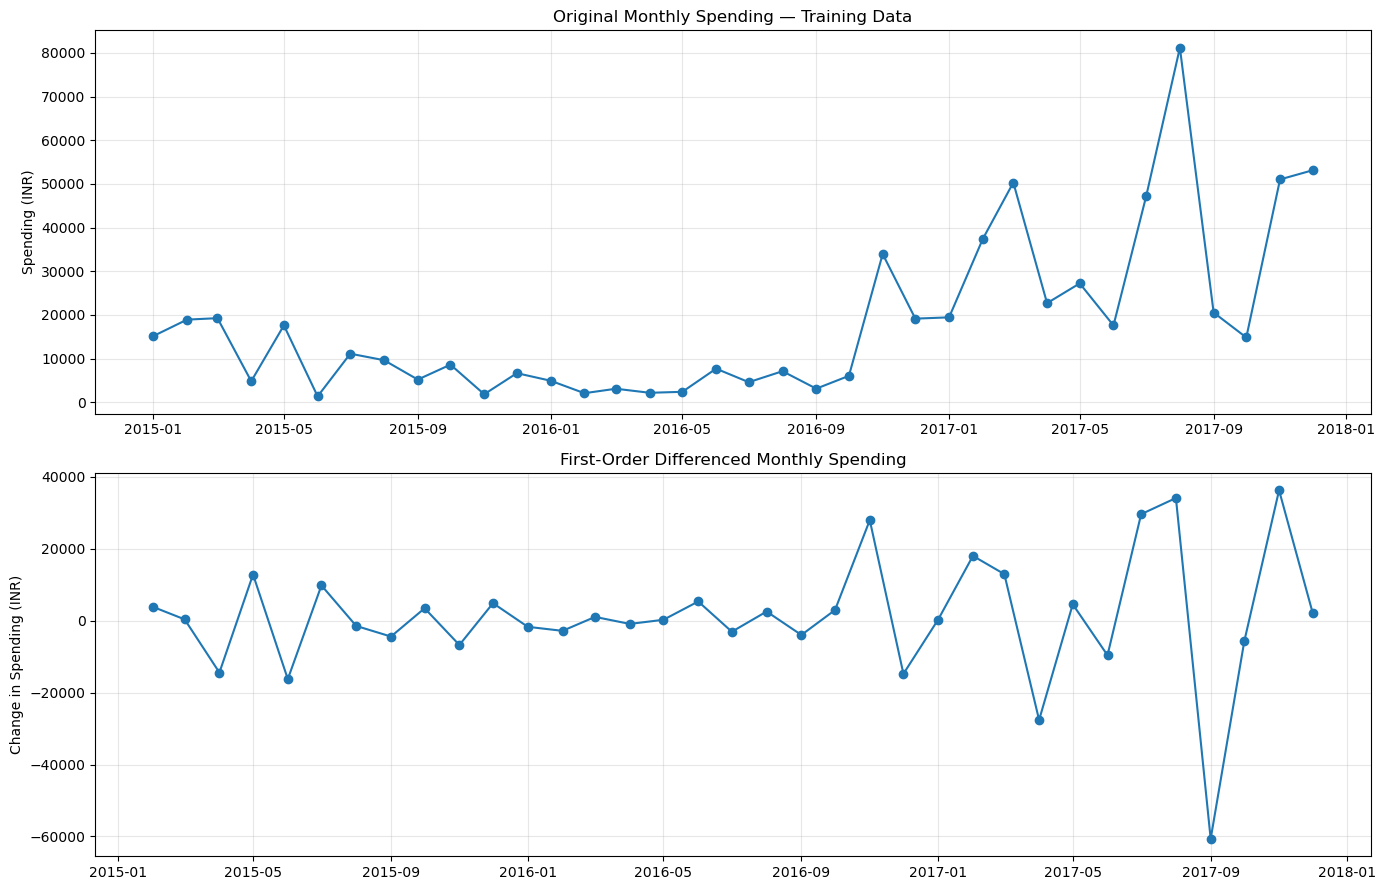


ARIMA DIAGNOSTIC SUMMARY
Original p-value: 0.2952
First difference p-value: 0.4078

Step 6 completed.


In [7]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# STEP 6: ARIMA — STATIONARITY ANALYSIS
# ============================================================

from statsmodels.tsa.stattools import adfuller

# ------------------------------------------------------------
# 1. PREPARE TRAINING DATA
# ------------------------------------------------------------

y = monthly_spending.copy()

FORECAST_HORIZON = 12
train_size = len(y) - FORECAST_HORIZON

# Use only 2015-2017 for model diagnostics
# Keep 2018 untouched as the final test period

arima_train = y.iloc[:train_size].copy()

print("=" * 55)
print("ARIMA STATIONARITY ANALYSIS")
print("=" * 55)

print("Training observations:", len(arima_train))
print("Training start:", arima_train.index.min())
print("Training end:", arima_train.index.max())

# ------------------------------------------------------------
# 2. ADF TEST ON ORIGINAL SERIES
# ------------------------------------------------------------

adf_original = adfuller(
    arima_train,
    autolag="AIC"
)

print("\nORIGINAL SERIES — ADF TEST")

print("ADF Statistic:", round(adf_original[0], 4))
print("p-value:", round(adf_original[1], 4))
print("Lags Used:", adf_original[2])
print("Observations Used:", adf_original[3])

if adf_original[1] <= 0.05:
    print("Conclusion: Evidence of stationarity.")
else:
    print("Conclusion: Insufficient evidence of stationarity.")

# ------------------------------------------------------------
# 3. FIRST-ORDER DIFFERENCING
# ------------------------------------------------------------

arima_diff1 = arima_train.diff().dropna()

adf_diff1 = adfuller(
    arima_diff1,
    autolag="AIC"
)

print("\nFIRST DIFFERENCED SERIES — ADF TEST")

print("ADF Statistic:", round(adf_diff1[0], 4))
print("p-value:", round(adf_diff1[1], 4))
print("Lags Used:", adf_diff1[2])
print("Observations Used:", adf_diff1[3])

if adf_diff1[1] <= 0.05:
    print("Conclusion: Evidence of stationarity after first differencing.")
else:
    print("Conclusion: First differencing may not be sufficient.")

# ------------------------------------------------------------
# 4. VISUALIZE ORIGINAL AND DIFFERENCED SERIES
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

axes[0].plot(
    arima_train.index.to_timestamp(),
    arima_train.values,
    marker="o"
)

axes[0].set_title("Original Monthly Spending — Training Data")
axes[0].set_ylabel("Spending (INR)")
axes[0].grid(alpha=0.3)

axes[1].plot(
    arima_diff1.index.to_timestamp(),
    arima_diff1.values,
    marker="o"
)

axes[1].set_title("First-Order Differenced Monthly Spending")
axes[1].set_ylabel("Change in Spending (INR)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. SUMMARY
# ------------------------------------------------------------

print("\nARIMA DIAGNOSTIC SUMMARY")

print("Original p-value:", round(adf_original[1], 4))
print("First difference p-value:", round(adf_diff1[1], 4))

print("\nStep 6 completed.")


STATIONARITY TEST COMPARISON


,Series,ADF_p_value,KPSS_p_value,ADF_lags,KPSS_lags
0,Original (d=0),0.9036,0.0132,3,3
1,First Difference (d=1),0.0000,0.1000,3,12
2,Second Difference (d=2),0.0000,0.1000,3,10



INTERPRETATION
ADF: p <= 0.05 provides evidence against a unit root.
KPSS: p > 0.05 means we cannot reject stationarity.

 Original (d=0)
Both tests raise concerns about stationarity.

 First Difference (d=1)
Both tests support stationarity.

 Second Difference (d=2)
Both tests support stationarity.


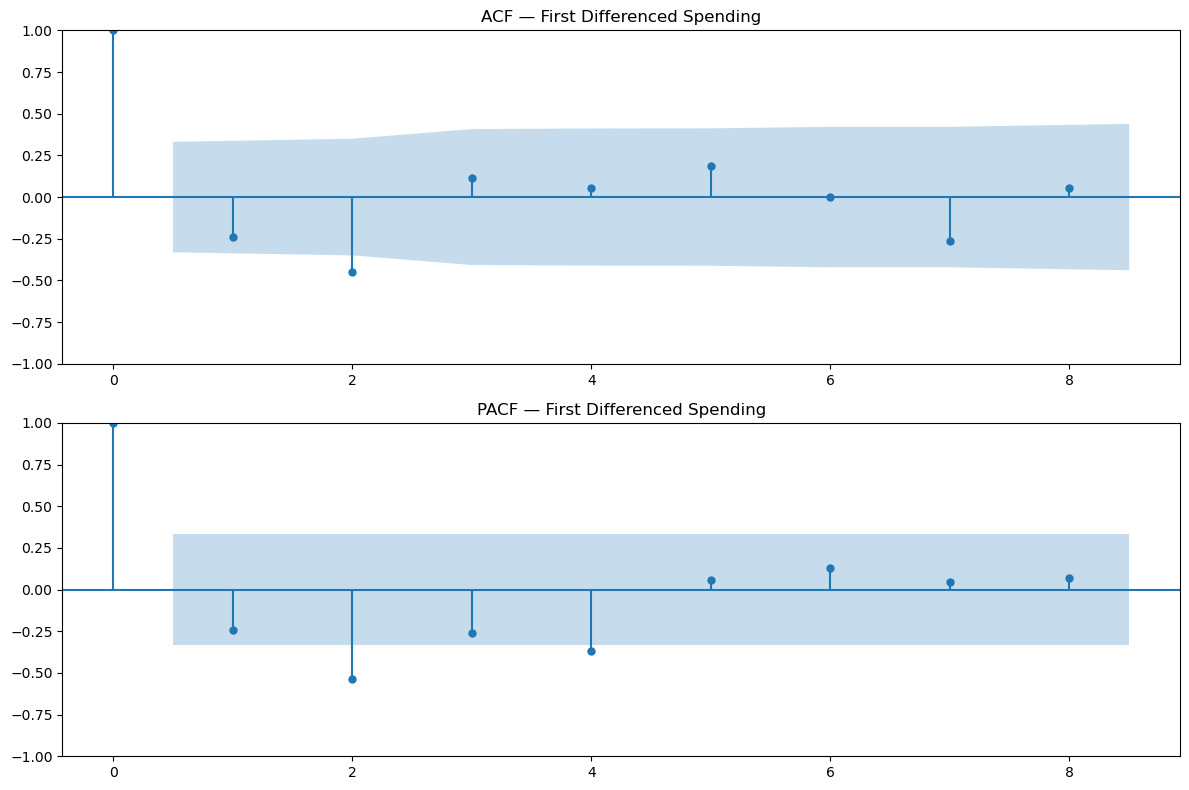


STEP 7 DIAGNOSTICS COMPLETED


In [8]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# STEP 7: IMPROVED STATIONARITY DIAGNOSTICS
# ============================================================

import warnings

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# ------------------------------------------------------------
# 1. PREPARE SERIES
# ------------------------------------------------------------

series_0 = arima_train.copy()
series_1 = series_0.diff().dropna()
series_2 = series_1.diff().dropna()

series_dict = {
    "Original (d=0)": series_0,
    "First Difference (d=1)": series_1,
    "Second Difference (d=2)": series_2
}

# ------------------------------------------------------------
# 2. ADF AND KPSS COMPARISON
# ------------------------------------------------------------

diagnostic_results = []

for name, series in series_dict.items():

    # Limit ADF lag selection because our sample is small
    max_lag = min(3, len(series) // 5)

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        adf_result = adfuller(
            series,
            maxlag=max_lag,
            autolag="AIC"
        )

        kpss_result = kpss(
            series,
            regression="c",
            nlags="auto"
        )

    diagnostic_results.append({
        "Series": name,
        "ADF_p_value": adf_result[1],
        "KPSS_p_value": kpss_result[1],
        "ADF_lags": adf_result[2],
        "KPSS_lags": kpss_result[2]
    })

diagnostic_df = pd.DataFrame(diagnostic_results)

print("STATIONARITY TEST COMPARISON")

display(diagnostic_df.round(4))

# ------------------------------------------------------------
# 3. INTERPRET THE TESTS
# ------------------------------------------------------------

print("\nINTERPRETATION")
print("ADF: p <= 0.05 provides evidence against a unit root.")
print("KPSS: p > 0.05 means we cannot reject stationarity.")

for _, row in diagnostic_df.iterrows():

    adf_stationary = row["ADF_p_value"] <= 0.05
    kpss_stationary = row["KPSS_p_value"] > 0.05

    print("\n", row["Series"])

    if adf_stationary and kpss_stationary:
        print("Both tests support stationarity.")
    elif not adf_stationary and not kpss_stationary:
        print("Both tests raise concerns about stationarity.")
    else:
        print("Tests disagree. Further investigation is needed.")

# ------------------------------------------------------------
# 4. ACF AND PACF FOR FIRST DIFFERENCED SERIES
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(
    series_1,
    lags=8,
    ax=axes[0]
)

axes[0].set_title("ACF — First Differenced Spending")

plot_pacf(
    series_1,
    lags=8,
    method="ywm",
    ax=axes[1]
)

axes[1].set_title("PACF — First Differenced Spending")

plt.tight_layout()
plt.show()

print("\nSTEP 7 DIAGNOSTICS COMPLETED")


ARIMA EXPERIMENT
Training observations: 36
Testing observations: 12
Forecast method: Expanding-window one-step-ahead

Training ARIMA(0, 1, 0)...
Completed successfully.

Training ARIMA(1, 1, 0)...
Completed successfully.

Training ARIMA(0, 1, 1)...
Completed successfully.

Training ARIMA(1, 1, 1)...
Completed successfully.

Training ARIMA(2, 1, 0)...
Completed successfully.

Training ARIMA(0, 1, 2)...
Completed successfully.

ARIMA MODEL PERFORMANCE


,Model,MAE,RMSE
0,"ARIMA(0, 1, 0)",18466.51,32878.03
1,"ARIMA(1, 1, 1)",22247.89,30422.20
2,"ARIMA(1, 1, 0)",22706.47,34161.26
3,"ARIMA(0, 1, 1)",23135.72,30045.68
4,"ARIMA(0, 1, 2)",25411.78,33562.93
5,"ARIMA(2, 1, 0)",27137.49,37984.59



COMPLETE FORECASTING MODEL COMPARISON


,Model,MAE,RMSE
0,Historical_Mean,18122.69,29416.07
1,Naive,18466.51,32878.03
2,"ARIMA(0, 1, 0)",18466.51,32878.03
3,Drift,18734.24,33380.36
4,Holt_Linear,22146.85,29953.30
5,Damped_Trend,22150.25,29730.15
6,"ARIMA(1, 1, 1)",22247.89,30422.20
7,"ARIMA(1, 1, 0)",22706.47,34161.26
8,SES,23127.24,30028.04
9,"ARIMA(0, 1, 1)",23135.72,30045.68


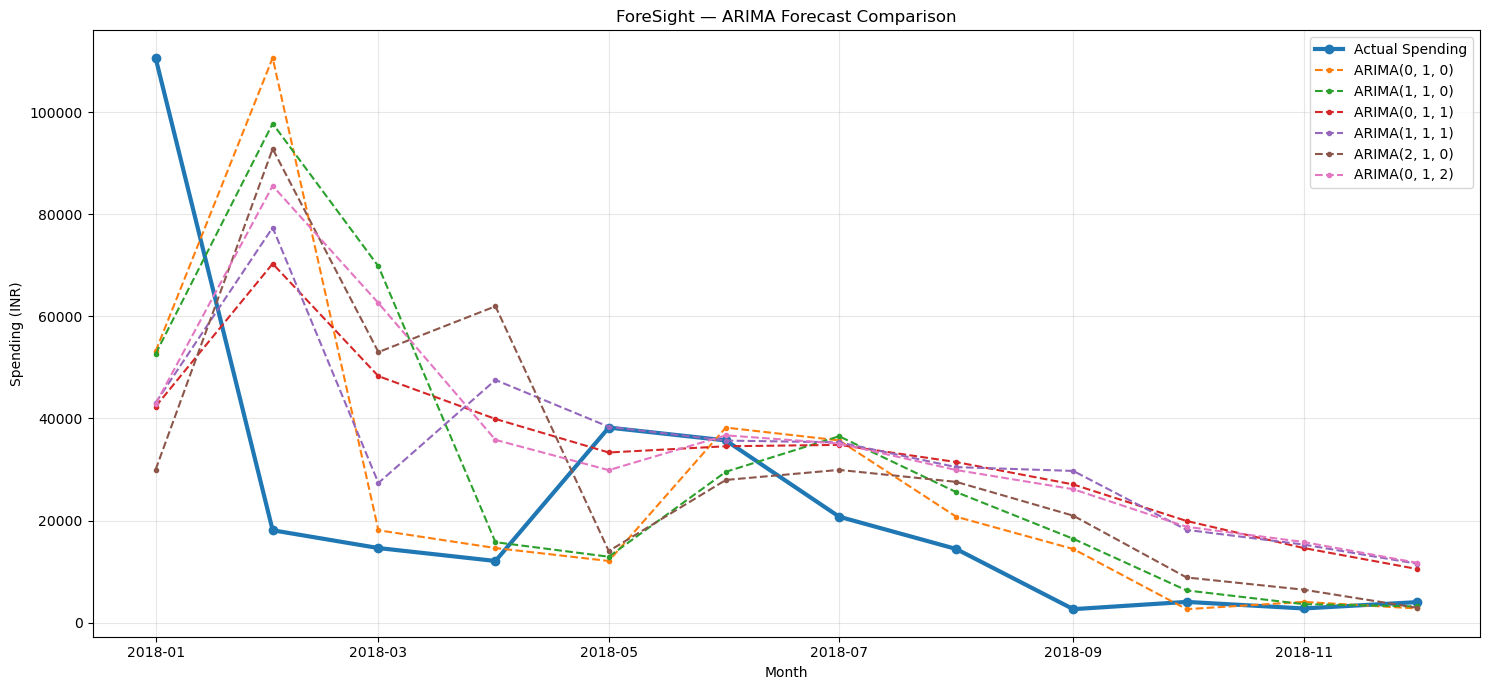


STEP 8 COMPLETED


In [9]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# STEP 8: ARIMA MODEL EXPERIMENTS
# ============================================================

import warnings
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. PREPARE DATA
# ------------------------------------------------------------

y = monthly_spending.copy()

FORECAST_HORIZON = 12
train_size = len(y) - FORECAST_HORIZON

arima_orders = [
    (0, 1, 0),
    (1, 1, 0),
    (0, 1, 1),
    (1, 1, 1),
    (2, 1, 0),
    (0, 1, 2)
]

arima_predictions = {}
arima_metrics_list = []
arima_failures = []

print("ARIMA EXPERIMENT")
print("Training observations:", train_size)
print("Testing observations:", FORECAST_HORIZON)
print("Forecast method: Expanding-window one-step-ahead")

# ------------------------------------------------------------
# 2. TEST EACH ARIMA CONFIGURATION
# ------------------------------------------------------------

for order in arima_orders:

    model_name = f"ARIMA{order}"

    predictions = []
    prediction_dates = []

    print(f"\nTraining {model_name}...")

    try:

        for i in range(train_size, len(y)):

            history = y.iloc[:i]

            with warnings.catch_warnings():
                warnings.simplefilter("ignore")

                model = ARIMA(
                    history,
                    order=order,
                    enforce_stationarity=False,
                    enforce_invertibility=False
                )

                fitted_model = model.fit()

                forecast = fitted_model.forecast(steps=1)

            prediction = float(forecast.iloc[0])

            if not np.isfinite(prediction):
                raise ValueError("Non-finite forecast generated.")

            predictions.append(prediction)
            prediction_dates.append(y.index[i])

        prediction_series = pd.Series(
            predictions,
            index=prediction_dates,
            name=model_name
        )

        arima_predictions[model_name] = prediction_series

        actual_values = y.loc[prediction_dates]

        mae = mean_absolute_error(
            actual_values,
            prediction_series
        )

        rmse = np.sqrt(
            mean_squared_error(
                actual_values,
                prediction_series
            )
        )

        arima_metrics_list.append({
            "Model": model_name,
            "MAE": mae,
            "RMSE": rmse
        })

        print("Completed successfully.")

    except Exception as e:

        arima_failures.append({
            "Model": model_name,
            "Error": str(e)
        })

        print("Model failed:", str(e))

# ------------------------------------------------------------
# 3. DISPLAY ARIMA PERFORMANCE
# ------------------------------------------------------------

arima_metrics = pd.DataFrame(arima_metrics_list)

if not arima_metrics.empty:

    arima_metrics = arima_metrics.sort_values(
        "MAE"
    ).reset_index(drop=True)

    print("\nARIMA MODEL PERFORMANCE")

    display(arima_metrics.round(2))

else:
    print("No ARIMA model completed successfully.")

# ------------------------------------------------------------
# 4. COMPARE ALL EXISTING MODELS
# ------------------------------------------------------------

if not arima_metrics.empty:

    all_model_metrics = pd.concat(
        [
            baseline_metrics,
            advanced_metrics,
            arima_metrics
        ],
        ignore_index=True
    )

    all_model_metrics = all_model_metrics.sort_values(
        "MAE"
    ).reset_index(drop=True)

    print("\nCOMPLETE FORECASTING MODEL COMPARISON")

    display(all_model_metrics.round(2))

# ------------------------------------------------------------
# 5. VISUALIZE ARIMA PREDICTIONS
# ------------------------------------------------------------

if arima_predictions:

    plt.figure(figsize=(15, 7))

    plt.plot(
        y.index[train_size:].to_timestamp(),
        y.iloc[train_size:].values,
        marker="o",
        linewidth=3,
        label="Actual Spending"
    )

    for name, predictions in arima_predictions.items():

        plt.plot(
            predictions.index.to_timestamp(),
            predictions.values,
            marker=".",
            linestyle="--",
            label=name
        )

    plt.title("ForeSight — ARIMA Forecast Comparison")
    plt.xlabel("Month")
    plt.ylabel("Spending (INR)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 6. DISPLAY FAILED MODELS IF ANY
# ------------------------------------------------------------

if arima_failures:

    print("\nARIMA MODELS WITH ERRORS")

    display(pd.DataFrame(arima_failures))

print("\nSTEP 8 COMPLETED")


CATEGORY-LEVEL SPENDING ANALYSIS
Number of months: 48
Number of categories: 23


Category,Apparel,Beauty,Cook,Culture,Documents,Education,Family,Festivals,Food,Gift,...,Other,Rent,Self-development,Social Life,Tourism,Transportation,garbage disposal,maid,subscription,water (jar /tanker)
2015-01,1021.0,60.0,776.0,40.0,0.0,0.0,0.0,0.0,3346.0,1024.0,...,500.0,5376.0,0.0,0.0,0.0,1824.0,0.0,333.0,0.0,0.0
2015-02,345.0,0.0,5000.0,0.0,0.0,0.0,0.0,0.0,1675.0,0.0,...,4930.0,5333.0,0.0,0.0,0.0,781.0,0.0,0.0,0.0,0.0
2015-03,170.0,0.0,6667.0,0.0,0.0,0.0,0.0,0.0,2606.8,0.0,...,828.0,0.0,0.0,0.0,0.0,50.0,17.0,666.0,0.0,148.0
2015-04,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3717.0,0.0,...,1039.0,0.0,0.0,0.0,0.0,0.0,50.0,0.0,0.0,0.0
2015-05,0.0,40.0,0.0,0.0,0.0,0.0,0.0,0.0,969.0,0.0,...,7673.0,0.0,0.0,0.0,0.0,6000.0,0.0,0.0,0.0,0.0



CATEGORY SUMMARY


,Total_Spending,Average_Monthly_Spending,Median_Monthly_Spending,Monthly_Std,Active_Months,Maximum_Monthly_Spending,Contribution_Percent,Active_Month_Percent
Category,,,,,,,,
Transportation,169053.78,3521.95,674.5,13686.03,40,95444.0,18.04,83.33
Household,161645.58,3367.62,501.0,5902.03,34,23967.0,17.25,70.83
subscription,114587.91,2387.25,802.0,5353.92,34,30667.0,12.23,70.83
Food,96393.10,2008.19,1639.5,1516.86,48,5793.0,10.29,100.00
Family,78582.20,1637.13,450.0,2463.12,31,10820.0,8.39,64.58
Health,66252.75,1380.27,200.0,3881.82,34,25171.0,7.07,70.83
Tourism,63608.85,1325.18,0.0,6827.19,3,43300.0,6.79,6.25
Other,57025.28,1188.03,356.0,1783.68,39,7673.0,6.09,81.25
Gift,40168.00,836.83,0.0,1975.43,20,8029.0,4.29,41.67



CATEGORY ACTIVITY ANALYSIS


,Active_Months,Active_Month_Percent,Contribution_Percent,Average_Monthly_Spending,Monthly_Std,Maximum_Monthly_Spending
Category,,,,,,
Transportation,40,83.33,18.04,3521.95,13686.03,95444.0
Household,34,70.83,17.25,3367.62,5902.03,23967.0
subscription,34,70.83,12.23,2387.25,5353.92,30667.0
Food,48,100.00,10.29,2008.19,1516.86,5793.0
Family,31,64.58,8.39,1637.13,2463.12,10820.0
Health,34,70.83,7.07,1380.27,3881.82,25171.0
Tourism,3,6.25,6.79,1325.18,6827.19,43300.0
Other,39,81.25,6.09,1188.03,1783.68,7673.0
Gift,20,41.67,4.29,836.83,1975.43,8029.0



CATEGORY VARIABILITY


,Average_Monthly_Spending,Monthly_Std,Coefficient_of_Variation
Category,,,
Transportation,3521.95,13686.03,3.89
Household,3367.62,5902.03,1.75
subscription,2387.25,5353.92,2.24
Food,2008.19,1516.86,0.76
Family,1637.13,2463.12,1.50
Health,1380.27,3881.82,2.81
Tourism,1325.18,6827.19,5.15
Other,1188.03,1783.68,1.50
Gift,836.83,1975.43,2.36



95TH PERCENTILE TRANSACTION THRESHOLD:
₹2,000.00

TOP 30 LARGE TRANSACTIONS


,Date,Category,Subcategory,Note,Amount
608,2018-01-18,Transportation,Bike,Two Wheeler Bikedelux second installment,50000.0
582,2018-01-27,Transportation,Bike,Two Wheeler Bikedelux third installment,43000.0
1076,2017-08-08,Tourism,Trip,Tours and Travel,43000.0
706,2017-12-20,subscription,Edtech Course,Renewal,28400.0
770,2017-11-30,Health,Health,Family's Glasses,22700.0
268,2018-05-15,Household,Appliances,LG Washing Machine,21500.0
1773,2016-11-28,Household,Appliances,Metz 32 inch TV,20500.0
1132,2017-07-25,Tourism,Trip,Tours and Travel,20000.0
218,2018-06-26,Household,Appliances,Aqugurad water purifier,13050.0
1395,2017-03-05,Household,Kitchen,Gas stove elica 3 burner,8825.0


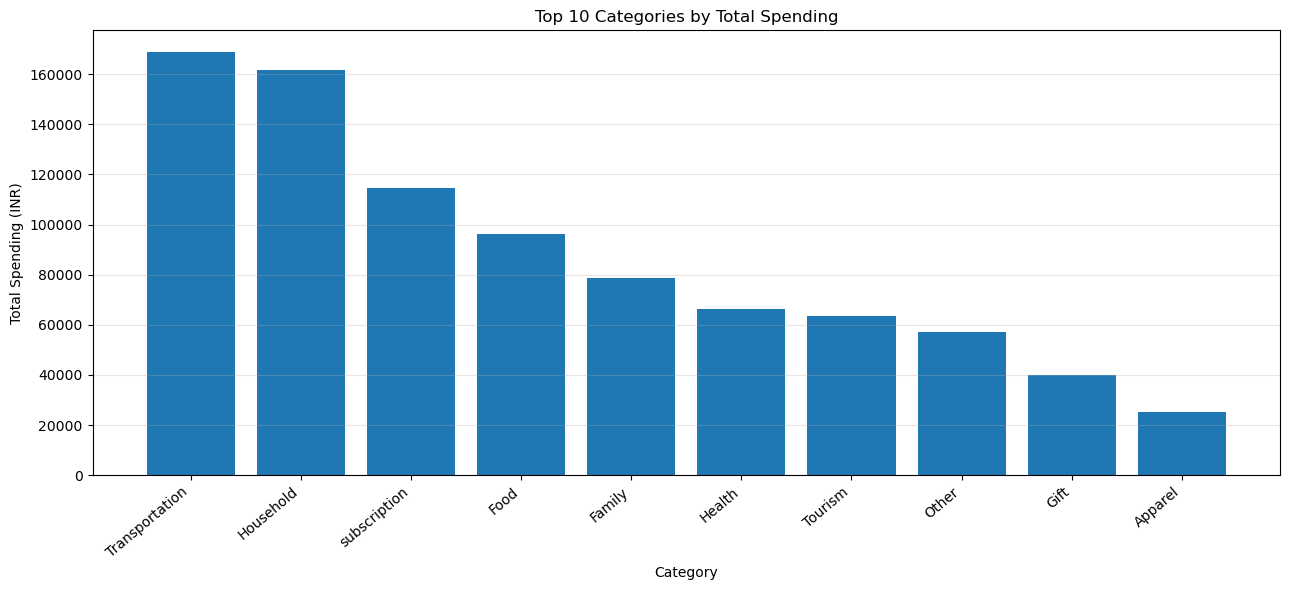

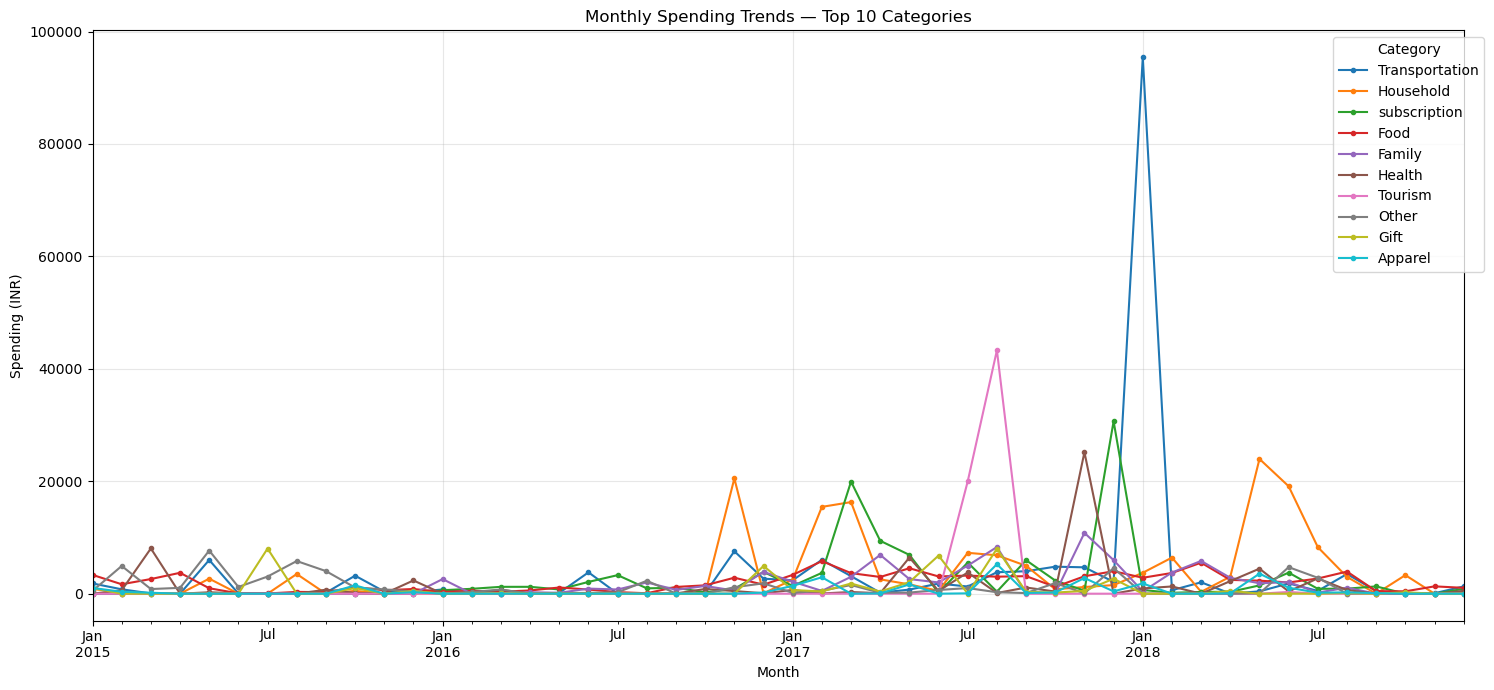


CATEGORY RECONCILIATION CHECK


,Original_Monthly_Total,Category_Monthly_Total,Difference
2015-01,15144.0,15144.0,0.0
2015-02,18919.0,18919.0,0.0
2015-03,19253.8,19253.8,0.0
2015-04,4806.0,4806.0,0.0
2015-05,17603.0,17603.0,0.0
2015-06,1343.0,1343.0,0.0
2015-07,11115.0,11115.0,0.0
2015-08,9624.0,9624.0,0.0
2015-09,5185.0,5185.0,0.0
2015-10,8604.6,8604.6,0.0



Maximum absolute difference: 0.0

STEP 9 COMPLETED


In [10]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# STEP 9: CATEGORY-LEVEL SPENDING ANALYSIS
# ============================================================

# ------------------------------------------------------------
# 1. CREATE MONTHLY CATEGORY SPENDING DATA
# ------------------------------------------------------------

category_monthly = (
    household_df
    .groupby(["Month", "Category"])["Amount"]
    .sum()
    .unstack(fill_value=0)
)

category_monthly = category_monthly.reindex(
    monthly_spending.index,
    fill_value=0
)

print("=" * 60)
print("CATEGORY-LEVEL SPENDING ANALYSIS")
print("=" * 60)

print("Number of months:", len(category_monthly))
print("Number of categories:", len(category_monthly.columns))

display(category_monthly.head())

# ------------------------------------------------------------
# 2. CATEGORY SPENDING SUMMARY
# ------------------------------------------------------------

category_summary = pd.DataFrame({
    "Total_Spending": category_monthly.sum(),
    "Average_Monthly_Spending": category_monthly.mean(),
    "Median_Monthly_Spending": category_monthly.median(),
    "Monthly_Std": category_monthly.std(),
    "Active_Months": (category_monthly > 0).sum(),
    "Maximum_Monthly_Spending": category_monthly.max()
})

category_summary["Contribution_Percent"] = (
    category_summary["Total_Spending"]
    / category_summary["Total_Spending"].sum()
    * 100
)

category_summary["Active_Month_Percent"] = (
    category_summary["Active_Months"]
    / len(category_monthly)
    * 100
)

category_summary = category_summary.sort_values(
    "Total_Spending",
    ascending=False
)

print("\nCATEGORY SUMMARY")

display(category_summary.round(2))

# ------------------------------------------------------------
# 3. IDENTIFY FREQUENT AND IRREGULAR CATEGORIES
# ------------------------------------------------------------

print("\nCATEGORY ACTIVITY ANALYSIS")

category_activity = category_summary[
    [
        "Active_Months",
        "Active_Month_Percent",
        "Contribution_Percent",
        "Average_Monthly_Spending",
        "Monthly_Std",
        "Maximum_Monthly_Spending"
    ]
]

display(category_activity.round(2))

# ------------------------------------------------------------
# 4. CATEGORY SPENDING VARIABILITY
# ------------------------------------------------------------

category_summary["Coefficient_of_Variation"] = (
    category_summary["Monthly_Std"]
    / category_summary["Average_Monthly_Spending"].replace(0, np.nan)
)

print("\nCATEGORY VARIABILITY")

display(
    category_summary[
        [
            "Average_Monthly_Spending",
            "Monthly_Std",
            "Coefficient_of_Variation"
        ]
    ].round(2)
)

# ------------------------------------------------------------
# 5. IDENTIFY LARGE TRANSACTIONS
# ------------------------------------------------------------

transaction_threshold = household_df["Amount"].quantile(0.95)

large_transactions = household_df[
    household_df["Amount"] >= transaction_threshold
].sort_values(
    "Amount",
    ascending=False
)

print("\n95TH PERCENTILE TRANSACTION THRESHOLD:")
print(f"₹{transaction_threshold:,.2f}")

print("\nTOP 30 LARGE TRANSACTIONS")

display(
    large_transactions[
        ["Date", "Category", "Subcategory", "Note", "Amount"]
    ].head(30)
)

# ------------------------------------------------------------
# 6. VISUALIZE TOP 10 CATEGORY CONTRIBUTIONS
# ------------------------------------------------------------

top_categories = category_summary.head(10)

plt.figure(figsize=(13, 6))

plt.bar(
    top_categories.index,
    top_categories["Total_Spending"]
)

plt.title("Top 10 Categories by Total Spending")
plt.xlabel("Category")
plt.ylabel("Total Spending (INR)")
plt.xticks(rotation=40, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. MONTHLY SPENDING PATTERNS OF TOP CATEGORIES
# ------------------------------------------------------------

top_category_names = top_categories.index.tolist()

category_monthly[top_category_names].plot(
    figsize=(15, 7),
    marker=".",
    linewidth=1.5
)

plt.title("Monthly Spending Trends — Top 10 Categories")
plt.xlabel("Month")
plt.ylabel("Spending (INR)")
plt.legend(
    title="Category",
    bbox_to_anchor=(1.02, 1)
)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. CHECK WHETHER CATEGORY TOTALS MATCH ORIGINAL TOTALS
# ------------------------------------------------------------

category_totals = category_monthly.sum(axis=1)

comparison = pd.DataFrame({
    "Original_Monthly_Total": monthly_spending,
    "Category_Monthly_Total": category_totals
})

comparison["Difference"] = (
    comparison["Original_Monthly_Total"]
    - comparison["Category_Monthly_Total"]
)

print("\nCATEGORY RECONCILIATION CHECK")

display(comparison.head(10).round(2))

print(
    "\nMaximum absolute difference:",
    round(comparison["Difference"].abs().max(), 6)
)

print("\nSTEP 9 COMPLETED")


SEPARATE CATEGORIES:
['Transportation', 'Household', 'subscription', 'Food', 'Family', 'Health', 'Other']

COMBINED REMAINING CATEGORIES:
['Apparel', 'Beauty', 'Cook', 'Culture', 'Documents', 'Education', 'Festivals', 'Gift', 'Grooming', 'Rent', 'Self-development', 'Social Life', 'Tourism', 'garbage disposal', 'maid', 'water (jar /tanker)']

Grouped dataset shape: (48, 8)

Category grouping reconciliation: PASSED

Running Category_SES...

Running Category_Holt...

CATEGORY-BASED FORECAST RESULTS


,Model,MAE,RMSE
0,Category_SES,23255.34,29515.51
1,Category_Holt,21592.67,27032.88



COMPLETE FORECASTING MODEL COMPARISON


,Model,MAE,RMSE
0,Historical_Mean,18122.69,29416.07
1,Naive,18466.51,32878.03
2,"ARIMA(0, 1, 0)",18466.51,32878.03
3,Drift,18734.24,33380.36
4,Category_Holt,21592.67,27032.88
5,Holt_Linear,22146.85,29953.30
6,Damped_Trend,22150.25,29730.15
7,"ARIMA(1, 1, 1)",22247.89,30422.20
8,"ARIMA(1, 1, 0)",22706.47,34161.26
9,SES,23127.24,30028.04


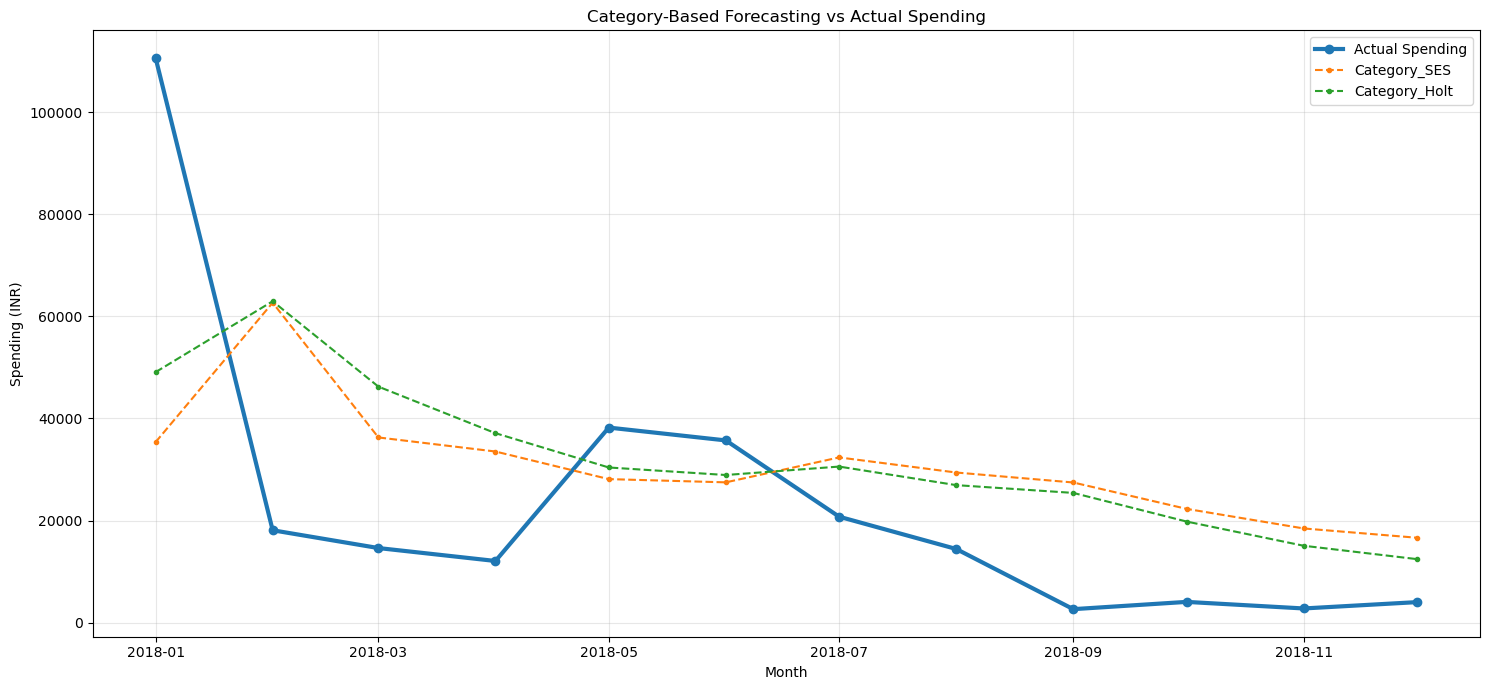


STEP 10 COMPLETED


In [11]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# STEP 10: CATEGORY-BASED FORECASTING EXPERIMENT
# ============================================================

import warnings
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. PREPARE CATEGORY GROUPS
# ------------------------------------------------------------

category_data = category_monthly.copy()

# Keep frequently active categories separate
frequent_categories = category_summary[
    category_summary["Active_Months"] >= 30
].index.tolist()

# Group all remaining categories together
remaining_categories = [
    c for c in category_data.columns
    if c not in frequent_categories
]

category_groups = category_data[frequent_categories].copy()

category_groups["Other_Categories"] = (
    category_data[remaining_categories].sum(axis=1)
)

print("SEPARATE CATEGORIES:")
print(frequent_categories)

print("\nCOMBINED REMAINING CATEGORIES:")
print(remaining_categories)

print("\nGrouped dataset shape:", category_groups.shape)

# Verify that grouping preserves original monthly totals
grouped_totals = category_groups.sum(axis=1)

assert np.allclose(
    grouped_totals.values,
    monthly_spending.values
), "Category grouping does not match original spending!"

print("\nCategory grouping reconciliation: PASSED")

# ------------------------------------------------------------
# 2. PREPARE CHRONOLOGICAL EVALUATION
# ------------------------------------------------------------

FORECAST_HORIZON = 12
train_size = len(monthly_spending) - FORECAST_HORIZON

category_model_predictions = {}
category_model_metrics = []
category_model_failures = []

# ------------------------------------------------------------
# 3. FORECAST EACH CATEGORY SEPARATELY
# ------------------------------------------------------------

for model_name in ["Category_SES", "Category_Holt"]:

    total_predictions = []
    prediction_dates = []
    model_failed = False

    print(f"\nRunning {model_name}...")

    for i in range(train_size, len(monthly_spending)):

        history = category_groups.iloc[:i]

        monthly_category_forecasts = []

        for category in category_groups.columns:

            category_history = history[category]

            try:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")

                    if model_name == "Category_SES":

                        fitted = SimpleExpSmoothing(
                            category_history,
                            initialization_method="estimated"
                        ).fit(optimized=True)

                    else:

                        fitted = Holt(
                            category_history,
                            initialization_method="estimated"
                        ).fit(optimized=True)

                    prediction = float(
                        fitted.forecast(1).iloc[0]
                    )

                if not np.isfinite(prediction):
                    raise ValueError("Non-finite prediction")

                monthly_category_forecasts.append(prediction)

            except Exception as e:

                category_model_failures.append({
                    "Model": model_name,
                    "Category": category,
                    "Month": monthly_spending.index[i],
                    "Error": str(e)
                })

                model_failed = True
                break

        if model_failed:
            break

        # Add category forecasts to obtain total spending forecast
        total_predictions.append(
            sum(monthly_category_forecasts)
        )

        prediction_dates.append(monthly_spending.index[i])

    if model_failed:
        print("Experiment failed; inspect the error log.")
        continue

    prediction_series = pd.Series(
        total_predictions,
        index=prediction_dates,
        name=model_name
    )

    category_model_predictions[model_name] = prediction_series

    actual_values = monthly_spending.loc[prediction_dates]

    mae = mean_absolute_error(
        actual_values,
        prediction_series
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual_values,
            prediction_series
        )
    )

    category_model_metrics.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse
    })

# ------------------------------------------------------------
# 4. DISPLAY CATEGORY MODEL RESULTS
# ------------------------------------------------------------

category_model_metrics = pd.DataFrame(
    category_model_metrics
)

print("\nCATEGORY-BASED FORECAST RESULTS")

if not category_model_metrics.empty:
    display(category_model_metrics.round(2))
else:
    print("No category-based model completed successfully.")

# ------------------------------------------------------------
# 5. COMPARE WITH EXISTING MODELS
# ------------------------------------------------------------

if not category_model_metrics.empty:

    complete_comparison = pd.concat(
        [
            baseline_metrics,
            advanced_metrics,
            arima_metrics,
            category_model_metrics
        ],
        ignore_index=True
    )

    complete_comparison = complete_comparison.sort_values(
        "MAE"
    ).reset_index(drop=True)

    print("\nCOMPLETE FORECASTING MODEL COMPARISON")

    display(complete_comparison.round(2))

# ------------------------------------------------------------
# 6. VISUALIZE CATEGORY-BASED PREDICTIONS
# ------------------------------------------------------------

if category_model_predictions:

    plt.figure(figsize=(15, 7))

    test_actual = monthly_spending.iloc[train_size:]

    plt.plot(
        test_actual.index.to_timestamp(),
        test_actual.values,
        marker="o",
        linewidth=3,
        label="Actual Spending"
    )

    for name, predictions in category_model_predictions.items():

        plt.plot(
            predictions.index.to_timestamp(),
            predictions.values,
            marker=".",
            linestyle="--",
            label=name
        )

    plt.title("Category-Based Forecasting vs Actual Spending")
    plt.xlabel("Month")
    plt.ylabel("Spending (INR)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 7. DISPLAY ANY ERRORS
# ------------------------------------------------------------

if category_model_failures:

    print("\nCATEGORY MODEL ERRORS")

    display(pd.DataFrame(category_model_failures))

print("\nSTEP 10 COMPLETED")


WALK-FORWARD BACKTESTING
Total observations: 48
Initial training observations: 24
Forecast horizon: 1 month
Evaluation periods: 24
Completed forecast for 2017-01
Completed forecast for 2017-02
Completed forecast for 2017-03
Completed forecast for 2017-04


Completed forecast for 2017-05
Completed forecast for 2017-06
Completed forecast for 2017-07
Completed forecast for 2017-08
Completed forecast for 2017-09
Completed forecast for 2017-10
Completed forecast for 2017-11
Completed forecast for 2017-12
Completed forecast for 2018-01
Completed forecast for 2018-02
Completed forecast for 2018-03
Completed forecast for 2018-04
Completed forecast for 2018-05
Completed forecast for 2018-06
Completed forecast for 2018-07
Completed forecast for 2018-08
Completed forecast for 2018-09
Completed forecast for 2018-10
Completed forecast for 2018-11
Completed forecast for 2018-12

WALK-FORWARD PREDICTIONS


,Actual,Historical_Mean,Naive,Seasonal_Naive,Drift,SES,Holt,Damped_Trend,ARIMA_011,ARIMA_111,ARIMA_210
Month,,,,,,,,,,,
2017-01,19440.00,9012.52,19146.60,4920.00,19320.63,17746.79,22607.91,21371.74,17893.59,23038.71,22987.23
2017-02,37415.00,9429.62,19440.00,2066.00,19619.00,19028.31,23951.76,23774.48,18679.74,20105.65,23444.51
2017-03,50320.52,10505.98,37415.00,3086.00,38305.84,28523.54,34629.05,34388.17,28130.06,25430.04,23585.39
2017-04,22691.68,11980.60,50320.52,2158.00,51673.46,43014.45,48361.76,48054.91,42954.66,42682.39,39162.91
2017-05,27220.00,12363.14,22691.68,2380.00,22971.22,31012.48,41549.45,41162.46,31008.09,34438.22,34031.39
2017-06,17581.60,12875.44,27220.00,7686.40,27651.29,29168.50,39836.38,39394.18,29210.15,29367.22,37650.54
2017-07,47148.10,13032.31,17581.60,4587.00,17665.66,23382.95,25017.72,24238.40,23595.28,23815.88,21352.34
2017-08,81199.70,14132.82,47148.10,7103.00,48214.90,33947.27,40169.94,39718.53,33985.44,31543.06,32175.27
2017-09,20542.00,16228.66,81199.70,3105.00,83330.53,69121.22,56771.46,56250.80,69450.60,67385.73,66149.02



WALK-FORWARD MODEL PERFORMANCE


,Model,MAE,RMSE,Bias,Evaluated_Months
0,Naive,19286.35,29860.50,629.57,24
1,Drift,19435.36,30303.23,1126.54,24
2,Historical_Mean,20981.73,29854.56,-13153.50,24
3,Damped_Trend,21158.25,26769.00,6317.95,24
4,Holt,21236.95,26933.41,6504.15,24
5,SES,22277.63,27834.12,3742.67,24
6,ARIMA_011,22303.26,27873.23,3729.93,24
7,ARIMA_111,22336.65,28349.72,3964.87,24
8,ARIMA_210,23958.02,32109.52,3660.19,24
9,Seasonal_Naive,31305.37,38081.24,-7579.26,24


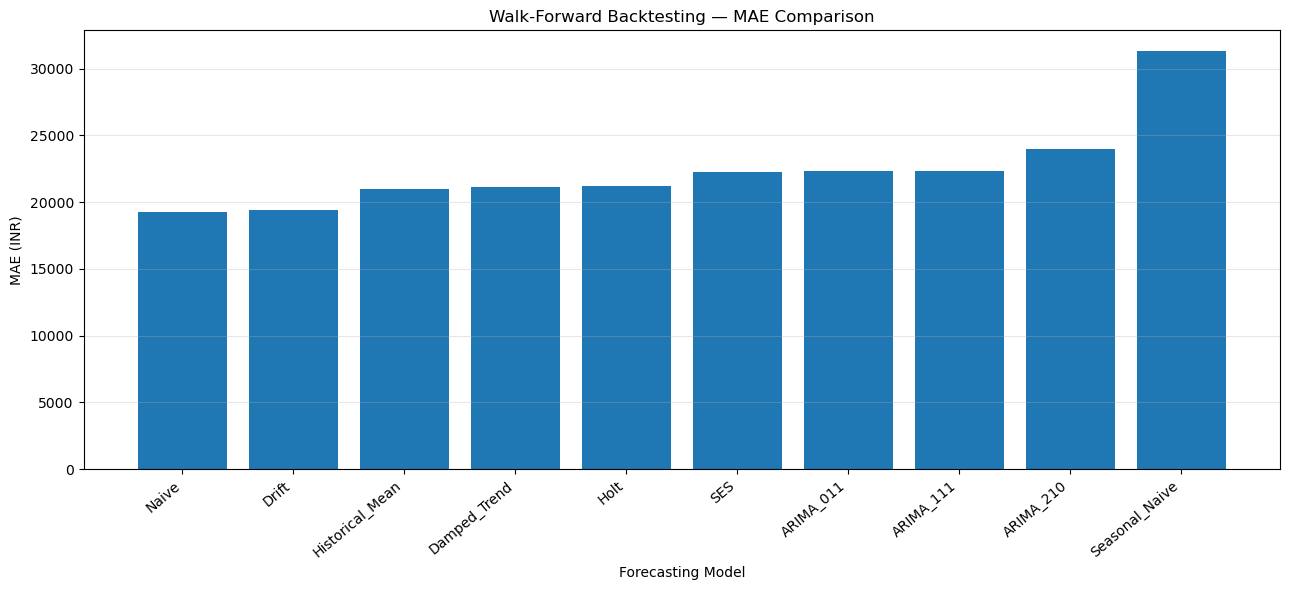

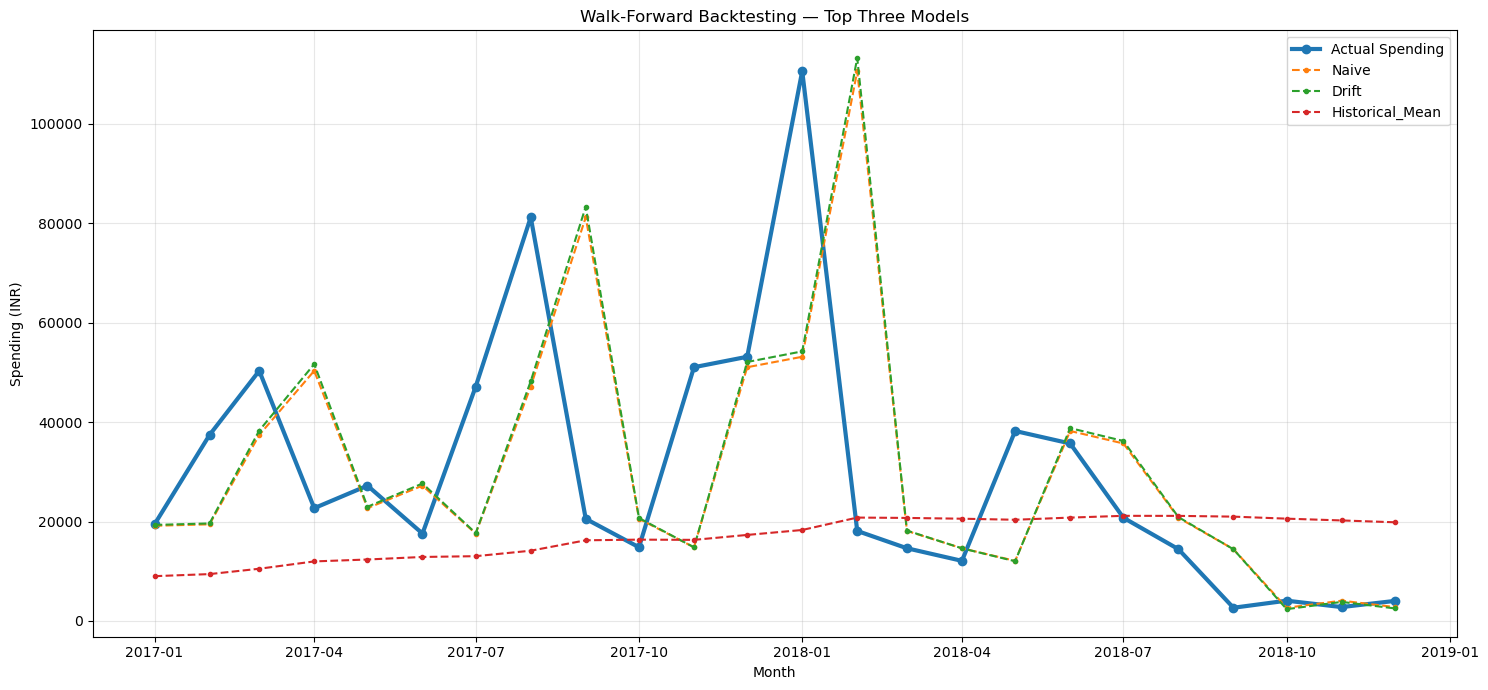


All models completed without recorded errors.

STEP 11 COMPLETED


In [12]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# STEP 11: WALK-FORWARD BACKTESTING
# ============================================================

import warnings
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. PREPARE DATA
# ------------------------------------------------------------

y = monthly_spending.copy()

MIN_TRAIN_SIZE = 24

model_predictions = {}

model_names = [
    "Historical_Mean",
    "Naive",
    "Seasonal_Naive",
    "Drift",
    "SES",
    "Holt",
    "Damped_Trend",
    "ARIMA_011",
    "ARIMA_111",
    "ARIMA_210"
]

for name in model_names:
    model_predictions[name] = []

actual_values = []
forecast_dates = []
failures = []

print("WALK-FORWARD BACKTESTING")
print("Total observations:", len(y))
print("Initial training observations:", MIN_TRAIN_SIZE)
print("Forecast horizon: 1 month")
print("Evaluation periods:", len(y) - MIN_TRAIN_SIZE)

# ------------------------------------------------------------
# 2. EXPANDING-WINDOW EVALUATION
# ------------------------------------------------------------

for i in range(MIN_TRAIN_SIZE, len(y)):

    history = y.iloc[:i]
    actual = y.iloc[i]

    actual_values.append(actual)
    forecast_dates.append(y.index[i])

    predictions = {}

    # 1. Historical Mean
    predictions["Historical_Mean"] = float(history.mean())

    # 2. Naive
    predictions["Naive"] = float(history.iloc[-1])

    # 3. Seasonal Naive
    predictions["Seasonal_Naive"] = float(history.iloc[-12])

    # 4. Drift
    predictions["Drift"] = float(
        history.iloc[-1]
        + (history.iloc[-1] - history.iloc[0])
        / (len(history) - 1)
    )

    # 5. Simple Exponential Smoothing
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")

            fitted = SimpleExpSmoothing(
                history,
                initialization_method="estimated"
            ).fit(optimized=True)

            predictions["SES"] = float(
                fitted.forecast(1).iloc[0]
            )

    except Exception as e:
        failures.append({"Model": "SES", "Month": y.index[i], "Error": str(e)})

    # 6. Holt Linear
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")

            fitted = Holt(
                history,
                initialization_method="estimated"
            ).fit(optimized=True)

            predictions["Holt"] = float(
                fitted.forecast(1).iloc[0]
            )

    except Exception as e:
        failures.append({"Model": "Holt", "Month": y.index[i], "Error": str(e)})

    # 7. Damped Trend
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")

            fitted = Holt(
                history,
                damped_trend=True,
                initialization_method="estimated"
            ).fit(optimized=True)

            predictions["Damped_Trend"] = float(
                fitted.forecast(1).iloc[0]
            )

    except Exception as e:
        failures.append({"Model": "Damped_Trend", "Month": y.index[i], "Error": str(e)})

    # 8–10. ARIMA configurations
    arima_orders = {
        "ARIMA_011": (0, 1, 1),
        "ARIMA_111": (1, 1, 1),
        "ARIMA_210": (2, 1, 0)
    }

    for name, order in arima_orders.items():

        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")

                fitted = ARIMA(
                    history,
                    order=order,
                    enforce_stationarity=False,
                    enforce_invertibility=False
                ).fit()

                predictions[name] = float(
                    fitted.forecast(1).iloc[0]
                )

        except Exception as e:
            failures.append({
                "Model": name,
                "Month": y.index[i],
                "Error": str(e)
            })

    # Store forecasts
    for name in model_names:

        value = predictions.get(name, np.nan)

        if not np.isfinite(value):
            value = np.nan

        model_predictions[name].append(value)

    print(f"Completed forecast for {y.index[i]}")

# ------------------------------------------------------------
# 3. CREATE FORECAST TABLE
# ------------------------------------------------------------

walk_forward_results = pd.DataFrame(
    model_predictions,
    index=forecast_dates
)

walk_forward_results.index.name = "Month"
walk_forward_results.insert(
    0,
    "Actual",
    actual_values
)

print("\nWALK-FORWARD PREDICTIONS")

display(walk_forward_results.round(2))

# ------------------------------------------------------------
# 4. CALCULATE PERFORMANCE METRICS
# ------------------------------------------------------------

walk_forward_metrics = []

for model in model_names:

    valid = walk_forward_results[
        ["Actual", model]
    ].dropna()

    if len(valid) == 0:
        continue

    actual = valid["Actual"]
    predicted = valid[model]

    walk_forward_metrics.append({
        "Model": model,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "Bias": (predicted - actual).mean(),
        "Evaluated_Months": len(valid)
    })

walk_forward_metrics = pd.DataFrame(
    walk_forward_metrics
).sort_values("MAE").reset_index(drop=True)

print("\nWALK-FORWARD MODEL PERFORMANCE")

display(walk_forward_metrics.round(2))

# ------------------------------------------------------------
# 5. VISUALIZE MAE COMPARISON
# ------------------------------------------------------------

plt.figure(figsize=(13, 6))

plt.bar(
    walk_forward_metrics["Model"],
    walk_forward_metrics["MAE"]
)

plt.title("Walk-Forward Backtesting — MAE Comparison")
plt.xlabel("Forecasting Model")
plt.ylabel("MAE (INR)")
plt.xticks(rotation=40, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. VISUALIZE PREDICTIONS OF TOP THREE MODELS
# ------------------------------------------------------------

top_three = walk_forward_metrics.head(3)["Model"].tolist()

plt.figure(figsize=(15, 7))

plt.plot(
    walk_forward_results.index.to_timestamp(),
    walk_forward_results["Actual"],
    marker="o",
    linewidth=3,
    label="Actual Spending"
)

for model in top_three:

    plt.plot(
        walk_forward_results.index.to_timestamp(),
        walk_forward_results[model],
        marker=".",
        linestyle="--",
        label=model
    )

plt.title("Walk-Forward Backtesting — Top Three Models")
plt.xlabel("Month")
plt.ylabel("Spending (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. CHECK MODEL FAILURES
# ------------------------------------------------------------

if failures:
    print("\nMODEL FAILURES")
    display(pd.DataFrame(failures))
else:
    print("\nAll models completed without recorded errors.")

print("\nSTEP 11 COMPLETED")


ERROR ANALYSIS DATA PREPARED

ERROR PERFORMANCE SUMMARY


,Model,MAE,RMSE,Mean_Error_Bias,Overprediction_Months,Underprediction_Months,Zero_Error_Months,Negative_Predictions
1,Naive,19286.35,29860.50,629.57,12,12,0,0
3,Drift,19435.36,30303.23,1126.54,12,12,0,0
0,Historical_Mean,20981.73,29854.56,-13153.50,10,14,0,0
6,Damped_Trend,21158.25,26769.00,6317.95,15,9,0,1
5,Holt,21236.95,26933.41,6504.15,14,10,0,1
4,SES,22277.63,27834.12,3742.67,14,10,0,0
7,ARIMA_011,22303.26,27873.23,3729.93,14,10,0,0
8,ARIMA_111,22336.65,28349.72,3964.87,16,8,0,0
9,ARIMA_210,23958.02,32109.52,3660.19,15,9,0,0
2,Seasonal_Naive,31305.37,38081.24,-7579.26,9,15,0,0



LARGEST ERRORS — Naive


,Actual,Predicted,Error,Absolute_Error
Month,,,,
2018-02,18109.00,110603.58,92494.58,92494.58
2017-09,20542.00,81199.70,60657.70,60657.70
2018-01,110603.58,53140.00,-57463.58,57463.58
2017-11,51039.60,14826.47,-36213.13,36213.13
2017-08,81199.70,47148.10,-34051.60,34051.60



LARGEST ERRORS — Historical_Mean


,Actual,Predicted,Error,Absolute_Error
Month,,,,
2018-01,110603.58,18301.81,-92301.77,92301.77
2017-08,81199.70,14132.82,-67066.88,67066.88
2017-03,50320.52,10505.98,-39814.54,39814.54
2017-12,53140.00,17306.44,-35833.56,35833.56
2017-11,51039.60,16314.28,-34725.32,34725.32


... (6 outputs left out)


PREDICTIONS DURING UNUSUAL MONTHS


,Actual,Historical_Mean,Naive,Seasonal_Naive,Drift,SES,Holt,Damped_Trend,ARIMA_011,ARIMA_111,ARIMA_210
Month,,,,,,,,,,,
2017-08,81199.70,14132.82,47148.1,7103.0,48214.9,33947.27,40169.94,39718.53,33985.44,31543.06,32175.27
2018-01,110603.58,18301.81,53140.0,19440.0,54225.6,42497.11,50647.13,49899.06,42339.67,43070.06,29962.99



NEGATIVE FORECAST INVESTIGATION


,Model,Month,Prediction,Actual
0,Holt,2018-12,-3266.08,4037.0
1,Damped_Trend,2018-12,-2060.14,4037.0


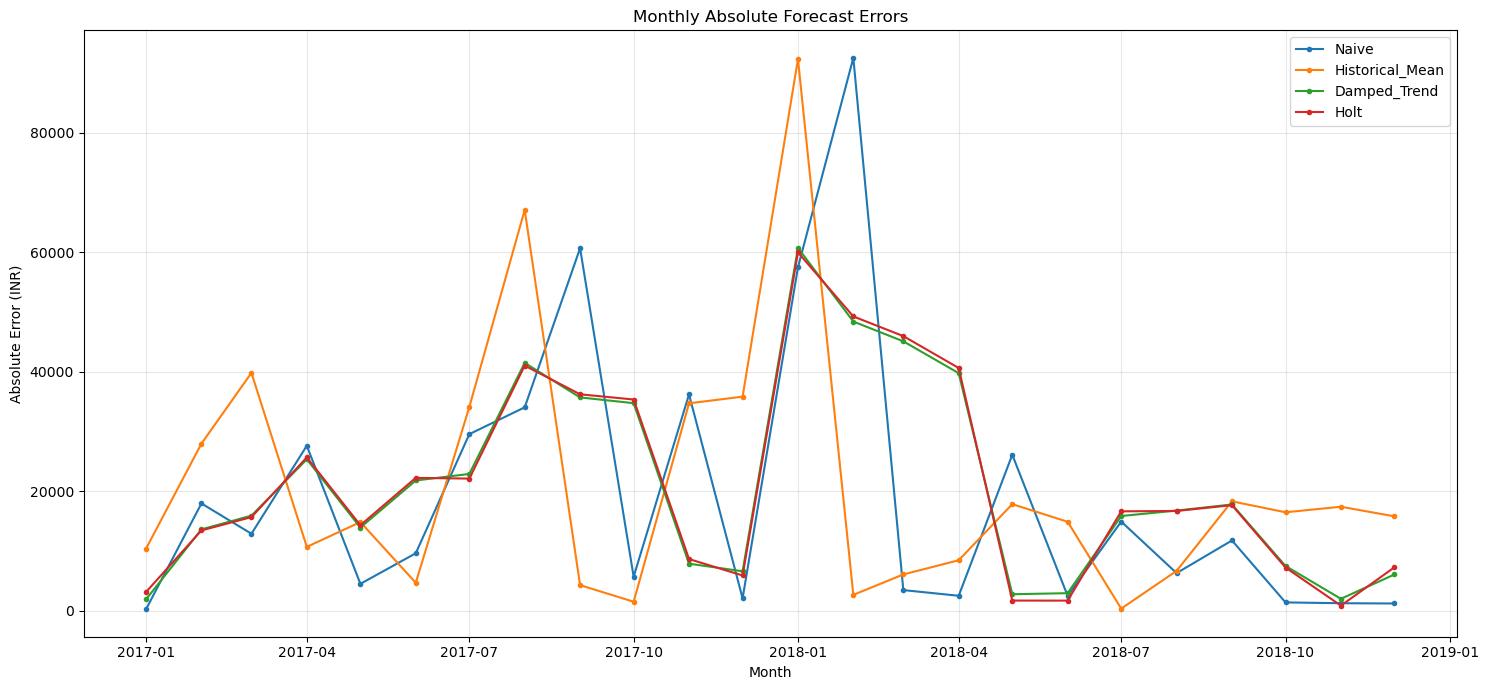

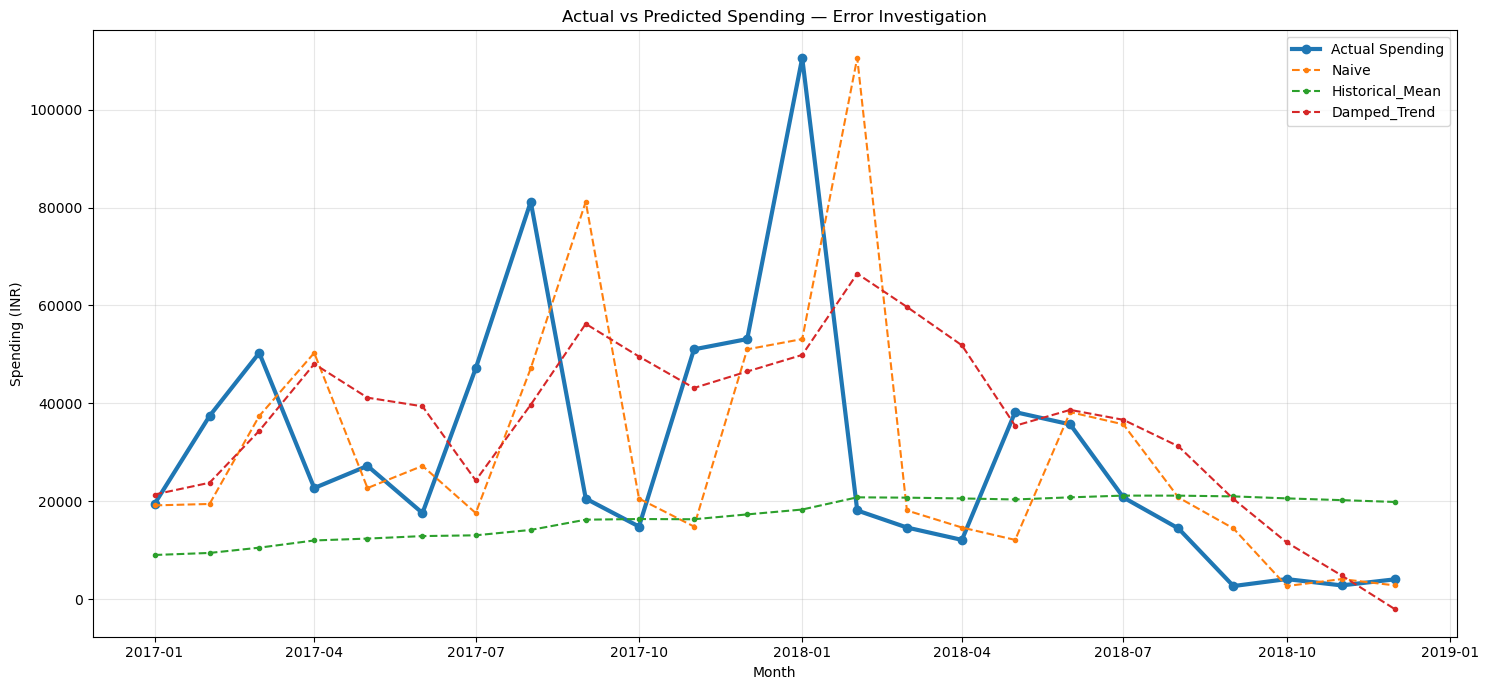


STEP 12 SUMMARY
Best MAE model: Naive
Best MAE: 19286.35
Best RMSE model: Damped_Trend
Best RMSE: 26769.0

STEP 12 COMPLETED


In [13]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# STEP 12: FORECAST ERROR ANALYSIS
# ============================================================

# ------------------------------------------------------------
# 1. PREPARE ERROR DATA
# ------------------------------------------------------------

error_results = walk_forward_results.copy()

forecast_models = [
    col for col in error_results.columns
    if col != "Actual"
]

error_tables = {}

for model in forecast_models:

    error_tables[model] = pd.DataFrame({
        "Actual": error_results["Actual"],
        "Predicted": error_results[model]
    })

    # Positive error = overprediction
    # Negative error = underprediction
    error_tables[model]["Error"] = (
        error_tables[model]["Predicted"]
        - error_tables[model]["Actual"]
    )

    error_tables[model]["Absolute_Error"] = (
        error_tables[model]["Error"].abs()
    )

print("ERROR ANALYSIS DATA PREPARED")

# ------------------------------------------------------------
# 2. ERROR PERFORMANCE SUMMARY
# ------------------------------------------------------------

error_summary = []

for model in forecast_models:

    data = error_tables[model].dropna()

    error_summary.append({
        "Model": model,
        "MAE": data["Absolute_Error"].mean(),
        "RMSE": np.sqrt((data["Error"] ** 2).mean()),
        "Mean_Error_Bias": data["Error"].mean(),
        "Overprediction_Months": (data["Error"] > 0).sum(),
        "Underprediction_Months": (data["Error"] < 0).sum(),
        "Zero_Error_Months": (data["Error"] == 0).sum(),
        "Negative_Predictions": (data["Predicted"] < 0).sum()
    })

error_summary = pd.DataFrame(error_summary)

print("\nERROR PERFORMANCE SUMMARY")

display(
    error_summary.sort_values("MAE").round(2)
)

# ------------------------------------------------------------
# 3. FIND MONTHS WITH LARGEST ERRORS
# ------------------------------------------------------------

selected_models = [
    "Naive",
    "Historical_Mean",
    "Damped_Trend",
    "Holt"
]

selected_models = [
    model for model in selected_models
    if model in error_tables
]

for model in selected_models:

    print(f"\nLARGEST ERRORS — {model}")

    largest_errors = (
        error_tables[model]
        .sort_values("Absolute_Error", ascending=False)
        .head(5)
    )

    display(largest_errors.round(2))

# ------------------------------------------------------------
# 4. INVESTIGATE OVERPREDICTION AND UNDERPREDICTION
# ------------------------------------------------------------

print("\nBIAS INTERPRETATION")

for model in selected_models:

    bias = error_tables[model]["Error"].mean()

    if bias > 0:
        conclusion = "Tends to OVERPREDICT."
    elif bias < 0:
        conclusion = "Tends to UNDERPREDICT."
    else:
        conclusion = "No average directional bias."

    print(f"{model}: {conclusion} Mean bias = ₹{bias:,.2f}")

# ------------------------------------------------------------
# 5. IDENTIFY UNUSUAL ACTUAL SPENDING MONTHS
# ------------------------------------------------------------

actual_spending = error_results["Actual"]

q1 = actual_spending.quantile(0.25)
q3 = actual_spending.quantile(0.75)
iqr = q3 - q1

upper_bound = q3 + 1.5 * iqr

unusual_months = actual_spending[
    actual_spending > upper_bound
]

print("\nUNUSUAL HIGH-SPENDING MONTHS")

print("Upper IQR threshold:", round(upper_bound, 2))

display(
    unusual_months.to_frame("Actual_Spending").round(2)
)

# Compare model predictions during unusual months
if len(unusual_months) > 0:

    unusual_comparison = error_results.loc[
        unusual_months.index
    ]

    print("\nPREDICTIONS DURING UNUSUAL MONTHS")

    display(unusual_comparison.round(2))

# ------------------------------------------------------------
# 6. CHECK NEGATIVE FORECASTS
# ------------------------------------------------------------

negative_forecasts = []

for model in forecast_models:

    data = error_tables[model]

    negative = data[data["Predicted"] < 0]

    for month, row in negative.iterrows():

        negative_forecasts.append({
            "Model": model,
            "Month": month,
            "Prediction": row["Predicted"],
            "Actual": row["Actual"]
        })

print("\nNEGATIVE FORECAST INVESTIGATION")

if negative_forecasts:
    display(pd.DataFrame(negative_forecasts).round(2))
else:
    print("No negative predictions found in this evaluation.")

# ------------------------------------------------------------
# 7. VISUALIZE MONTHLY ERRORS OF TOP MODELS
# ------------------------------------------------------------

plt.figure(figsize=(15, 7))

for model in selected_models:

    plt.plot(
        error_tables[model].index.to_timestamp(),
        error_tables[model]["Absolute_Error"],
        marker=".",
        label=model
    )

plt.title("Monthly Absolute Forecast Errors")
plt.xlabel("Month")
plt.ylabel("Absolute Error (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. VISUALIZE PREDICTED VS ACTUAL SPENDING
# ------------------------------------------------------------

plt.figure(figsize=(15, 7))

plt.plot(
    error_results.index.to_timestamp(),
    error_results["Actual"],
    marker="o",
    linewidth=3,
    label="Actual Spending"
)

for model in ["Naive", "Historical_Mean", "Damped_Trend"]:

    if model in error_results.columns:

        plt.plot(
            error_results.index.to_timestamp(),
            error_results[model],
            marker=".",
            linestyle="--",
            label=model
        )

plt.title("Actual vs Predicted Spending — Error Investigation")
plt.xlabel("Month")
plt.ylabel("Spending (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. FINAL SUMMARY
# ------------------------------------------------------------

best_mae_model = error_summary.loc[
    error_summary["MAE"].idxmin()
]

best_rmse_model = error_summary.loc[
    error_summary["RMSE"].idxmin()
]

print("\nSTEP 12 SUMMARY")

print("Best MAE model:", best_mae_model["Model"])
print("Best MAE:", round(best_mae_model["MAE"], 2))

print("Best RMSE model:", best_rmse_model["Model"])
print("Best RMSE:", round(best_rmse_model["RMSE"], 2))

print("\nSTEP 12 COMPLETED")


OUTLIER-AWARE FORECASTING
Initial training months: 24
Evaluation months: 24

OUTLIER-AWARE FORECAST RESULTS


,Threshold,Actual_Regular,Actual_Exceptional,Actual_Total,Naive_Regular_Forecast,Mean_Regular_Forecast,Exceptional_Forecast,Naive_Scenario_Total,Mean_Scenario_Total
Month,,,,,,,,,
2017-01,1999.10,13040.00,6400.00,19440.00,11135.60,4409.28,0.0,11135.60,4409.28
2017-02,1999.20,10818.00,26597.00,37415.00,13040.00,4754.50,0.0,13040.00,4754.50
2017-03,2000.00,16858.20,33462.32,50320.52,12818.00,5449.25,0.0,12818.00,5449.25
2017-04,2411.55,9292.68,13399.00,22691.68,16858.20,6121.77,0.0,16858.20,6121.77
2017-05,2421.00,13130.00,14090.00,27220.00,9292.68,6407.95,0.0,9292.68,6407.95
2017-06,2407.35,12781.60,4800.00,17581.60,13130.00,6472.78,0.0,13130.00,6472.78
2017-07,2106.55,10853.00,36295.10,47148.10,12781.60,6528.07,0.0,12781.60,6528.07
2017-08,2414.70,15301.70,65898.00,81199.70,10853.00,6817.58,0.0,10853.00,6817.58
2017-09,2500.00,11979.00,8563.00,20542.00,15301.70,7468.40,0.0,15301.70,7468.40



REGULAR SPENDING FORECAST PERFORMANCE


,Model,MAE,RMSE
0,Naive,3173.47,3995.80
1,Mean,6327.17,6743.18



TOTAL SPENDING SCENARIO PERFORMANCE


,Scenario,MAE,RMSE
0,Naive Regular + Zero Exceptional,19346.17,30202.00
1,Mean Regular + Zero Exceptional,24395.43,34284.31



TOTAL FORECAST COMPARISON


,Model,MAE
0,Original Naive,19286.35
1,Outlier-Aware Naive Scenario,19346.17
2,Outlier-Aware Mean Scenario,24395.43



EXCEPTIONAL SPENDING SUMMARY


,Exceptional_Spending,Regular_Spending,Exceptional_Percentage
Month,,,
2018-01,93000.00,17603.58,84.08
2017-08,65898.00,15301.70,81.16
2017-12,37090.00,16050.00,69.80
2017-07,36295.10,10853.00,76.98
2017-11,35497.00,15542.60,69.55
2017-03,33462.32,16858.20,66.50
2018-05,29210.00,9004.00,76.44
2017-02,26597.00,10818.00,71.09
2018-06,22389.00,13312.02,62.71



Months containing exceptional transactions: 17


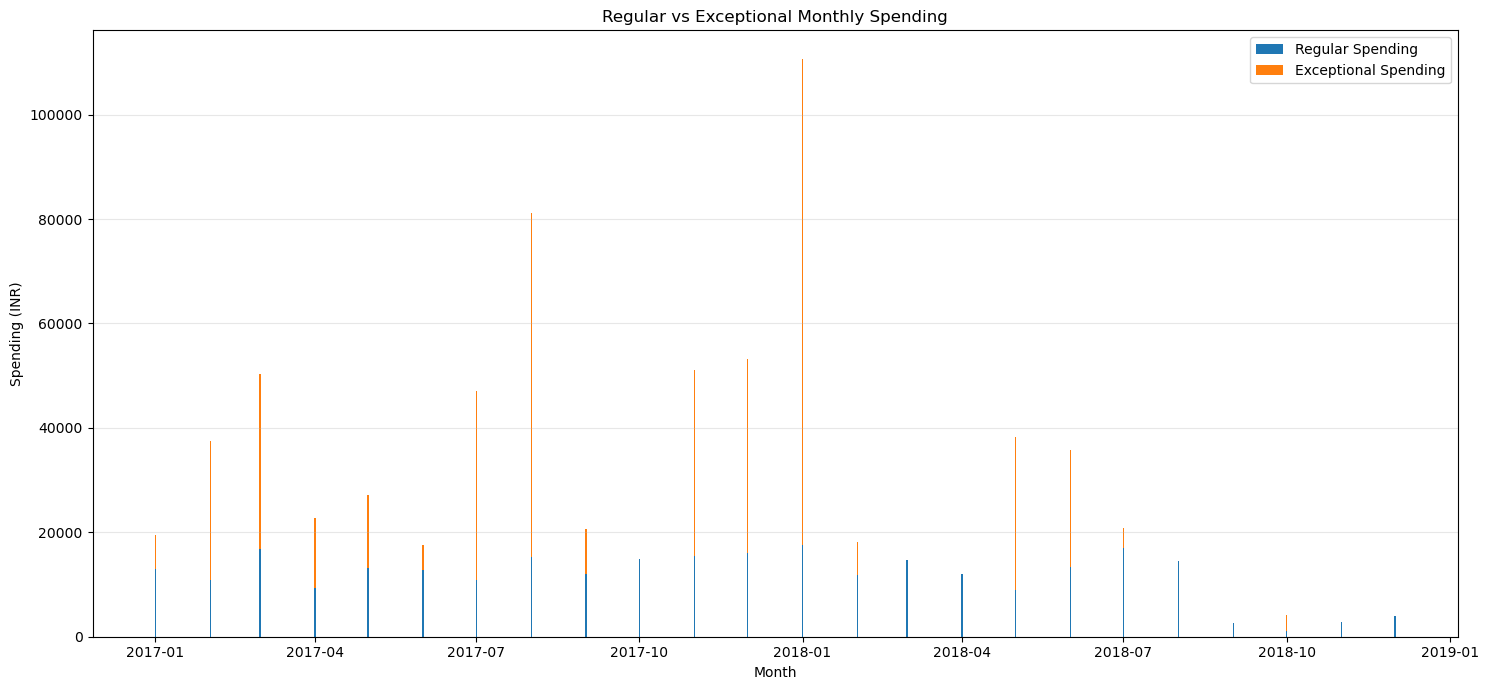

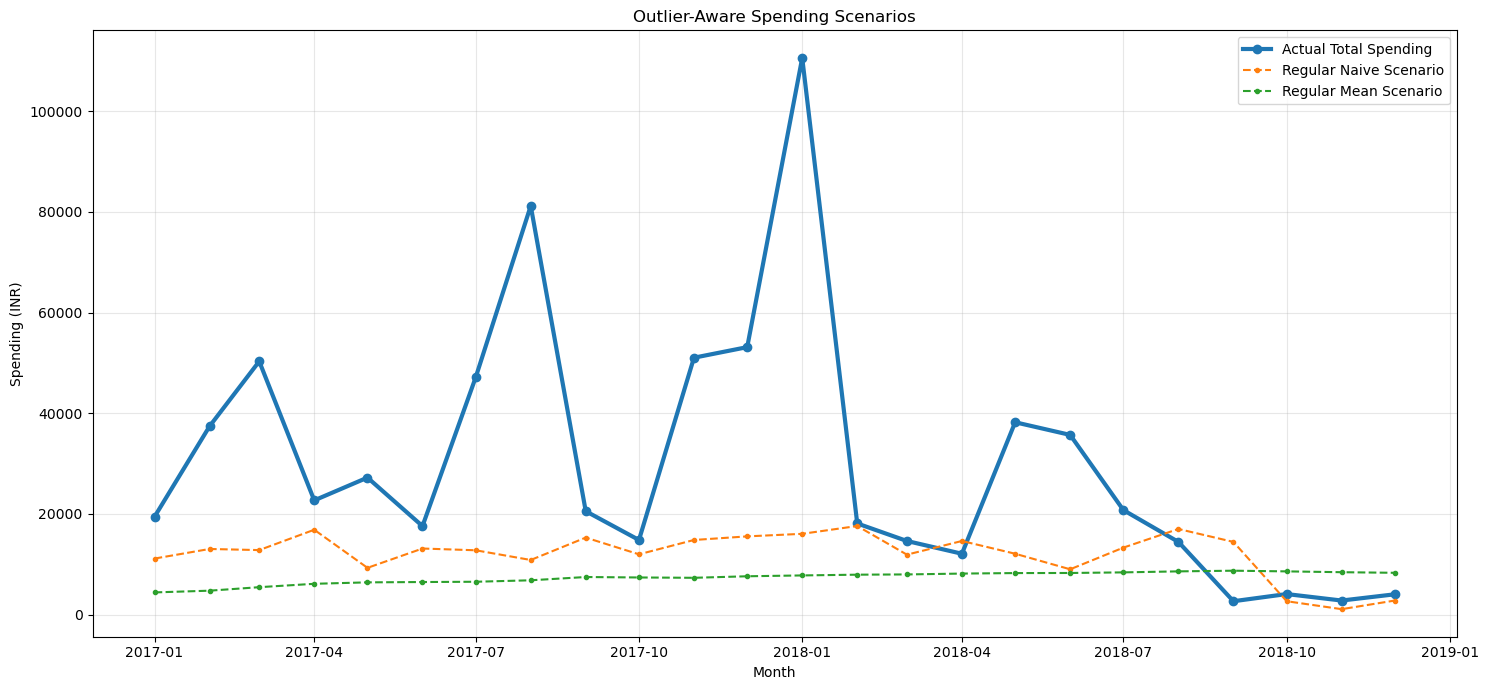


STEP 13 COMPLETED


In [14]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# STEP 13: OUTLIER-AWARE FORECASTING EXPERIMENT
# ============================================================

# ------------------------------------------------------------
# 1. PREPARE DATA
# ------------------------------------------------------------

y = monthly_spending.copy()

FORECAST_HORIZON = 12
MIN_TRAIN_SIZE = 24

outlier_predictions = []

print("OUTLIER-AWARE FORECASTING")
print("Initial training months:", MIN_TRAIN_SIZE)
print("Evaluation months:", len(y) - MIN_TRAIN_SIZE)

# ------------------------------------------------------------
# 2. WALK-FORWARD TRANSACTION CLASSIFICATION
# ------------------------------------------------------------

for i in range(MIN_TRAIN_SIZE, len(y)):

    target_month = y.index[i]

    # Only use transactions available before the target month
    training_months = y.index[:i]

    transaction_history = household_df[
        household_df["Month"].isin(training_months)
    ].copy()

    # Calculate threshold using training transactions only
    threshold = transaction_history["Amount"].quantile(0.95)

    # Separate regular and exceptional transactions
    transaction_history["Transaction_Type"] = np.where(
        transaction_history["Amount"] > threshold,
        "Exceptional",
        "Regular"
    )

    # Aggregate regular spending by month
    regular_history = (
        transaction_history[
            transaction_history["Transaction_Type"] == "Regular"
        ]
        .groupby("Month")["Amount"]
        .sum()
        .reindex(training_months, fill_value=0)
    )

    # Forecast regular spending using two simple approaches
    regular_naive = float(regular_history.iloc[-1])
    regular_mean = float(regular_history.mean())

    # No future exceptional purchase is assumed.
    # This is an explicit no-planned-exception scenario.
    exceptional_forecast = 0.0

    # Calculate actual components for evaluation only
    target_transactions = household_df[
        household_df["Month"] == target_month
    ].copy()

    actual_regular = target_transactions.loc[
        target_transactions["Amount"] <= threshold,
        "Amount"
    ].sum()

    actual_exceptional = target_transactions.loc[
        target_transactions["Amount"] > threshold,
        "Amount"
    ].sum()

    actual_total = actual_regular + actual_exceptional

    outlier_predictions.append({
        "Month": target_month,
        "Threshold": threshold,
        "Actual_Regular": actual_regular,
        "Actual_Exceptional": actual_exceptional,
        "Actual_Total": actual_total,
        "Naive_Regular_Forecast": regular_naive,
        "Mean_Regular_Forecast": regular_mean,
        "Exceptional_Forecast": exceptional_forecast,
        "Naive_Scenario_Total": regular_naive + exceptional_forecast,
        "Mean_Scenario_Total": regular_mean + exceptional_forecast
    })

# ------------------------------------------------------------
# 3. CREATE RESULTS TABLE
# ------------------------------------------------------------

outlier_results = pd.DataFrame(
    outlier_predictions
).set_index("Month")

print("\nOUTLIER-AWARE FORECAST RESULTS")

display(outlier_results.round(2))

# ------------------------------------------------------------
# 4. EVALUATE REGULAR SPENDING FORECASTS
# ------------------------------------------------------------

regular_metrics = []

for model in ["Naive", "Mean"]:

    actual = outlier_results["Actual_Regular"]

    predicted = outlier_results[
        f"{model}_Regular_Forecast"
    ]

    regular_metrics.append({
        "Model": model,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    })

regular_metrics = pd.DataFrame(regular_metrics)

print("\nREGULAR SPENDING FORECAST PERFORMANCE")

display(regular_metrics.round(2))

# ------------------------------------------------------------
# 5. EVALUATE TOTAL SPENDING SCENARIOS
# ------------------------------------------------------------

scenario_metrics = []

for model in ["Naive", "Mean"]:

    actual = outlier_results["Actual_Total"]

    predicted = outlier_results[
        f"{model}_Scenario_Total"
    ]

    scenario_metrics.append({
        "Scenario": f"{model} Regular + Zero Exceptional",
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    })

scenario_metrics = pd.DataFrame(scenario_metrics)

print("\nTOTAL SPENDING SCENARIO PERFORMANCE")

display(scenario_metrics.round(2))

# ------------------------------------------------------------
# 6. COMPARE WITH ORIGINAL TOTAL-SPENDING BASELINES
# ------------------------------------------------------------

comparison = pd.DataFrame([
    {
        "Model": "Original Naive",
        "MAE": mean_absolute_error(
            outlier_results["Actual_Total"],
            outlier_results["Actual_Total"].shift(1).fillna(
                y.iloc[MIN_TRAIN_SIZE - 1]
            )
        )
    },
    {
        "Model": "Outlier-Aware Naive Scenario",
        "MAE": scenario_metrics.iloc[0]["MAE"]
    },
    {
        "Model": "Outlier-Aware Mean Scenario",
        "MAE": scenario_metrics.iloc[1]["MAE"]
    }
])

print("\nTOTAL FORECAST COMPARISON")

display(comparison.round(2))

# ------------------------------------------------------------
# 7. EXCEPTIONAL SPENDING ANALYSIS
# ------------------------------------------------------------

exceptional_summary = pd.DataFrame({
    "Exceptional_Spending": outlier_results["Actual_Exceptional"],
    "Regular_Spending": outlier_results["Actual_Regular"]
})

exceptional_summary["Exceptional_Percentage"] = (
    exceptional_summary["Exceptional_Spending"]
    / outlier_results["Actual_Total"].replace(0, np.nan)
    * 100
)

print("\nEXCEPTIONAL SPENDING SUMMARY")

display(
    exceptional_summary.sort_values(
        "Exceptional_Spending",
        ascending=False
    ).head(10).round(2)
)

print(
    "\nMonths containing exceptional transactions:",
    (outlier_results["Actual_Exceptional"] > 0).sum()
)

# ------------------------------------------------------------
# 8. VISUALIZE REGULAR AND EXCEPTIONAL SPENDING
# ------------------------------------------------------------

plt.figure(figsize=(15, 7))

plt.bar(
    outlier_results.index.to_timestamp(),
    outlier_results["Actual_Regular"],
    label="Regular Spending"
)

plt.bar(
    outlier_results.index.to_timestamp(),
    outlier_results["Actual_Exceptional"],
    bottom=outlier_results["Actual_Regular"],
    label="Exceptional Spending"
)

plt.title("Regular vs Exceptional Monthly Spending")
plt.xlabel("Month")
plt.ylabel("Spending (INR)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. VISUALIZE ACTUAL VS OUTLIER-AWARE SCENARIOS
# ------------------------------------------------------------

plt.figure(figsize=(15, 7))

plt.plot(
    outlier_results.index.to_timestamp(),
    outlier_results["Actual_Total"],
    marker="o",
    linewidth=3,
    label="Actual Total Spending"
)

plt.plot(
    outlier_results.index.to_timestamp(),
    outlier_results["Naive_Scenario_Total"],
    marker=".",
    linestyle="--",
    label="Regular Naive Scenario"
)

plt.plot(
    outlier_results.index.to_timestamp(),
    outlier_results["Mean_Scenario_Total"],
    marker=".",
    linestyle="--",
    label="Regular Mean Scenario"
)

plt.title("Outlier-Aware Spending Scenarios")
plt.xlabel("Month")
plt.ylabel("Spending (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nSTEP 13 COMPLETED")


FEATURE ENGINEERING RESULTS


,Total_Spending,Lag_1,Lag_2,Lag_3,Lag_6,Rolling_Mean_3,Rolling_Mean_6,Rolling_Std_3,Recent_Trend
2017-10,14826.47,20542.00,81199.70,47148.10,22691.68,49629.93,36063.85,30404.91,-26606.10
2017-11,51039.60,14826.47,20542.00,81199.70,27220.00,38856.06,34752.98,36781.86,-66373.23
2017-12,53140.00,51039.60,14826.47,20542.00,17581.60,28802.69,38722.91,19468.61,30497.60
2018-01,110603.58,53140.00,51039.60,14826.47,47148.10,39668.69,44649.31,21539.61,38313.53
2018-02,18109.00,110603.58,53140.00,51039.60,81199.70,71594.39,55225.22,33799.27,59563.98
2018-03,14625.75,18109.00,110603.58,53140.00,20542.00,60617.53,44710.11,46698.47,-35031.00
2018-04,12094.00,14625.75,18109.00,110603.58,14826.47,47779.44,43724.07,54435.17,-95977.83
2018-05,38214.00,12094.00,14625.75,18109.00,51039.60,14942.92,43268.66,3020.02,-6015.00
2018-06,35701.02,38214.00,12094.00,14625.75,53140.00,21644.58,41131.06,14405.26,23588.25
2018-07,20762.36,35701.02,38214.00,12094.00,110603.58,28669.67,38224.56,14409.84,23607.02



MISSING VALUES BY FEATURE


,Missing_Values
Total_Spending,0
Lag_1,1
Lag_2,2
Lag_3,3
Lag_6,6
Rolling_Mean_3,3
Rolling_Mean_6,6
Rolling_Std_3,3
Recent_Trend,3



FEATURE CORRELATION WITH MONTHLY SPENDING


,Correlation_With_Spending
Rolling_Mean_6,0.537
Lag_1,0.472
Rolling_Mean_3,0.405
Lag_6,0.294
Rolling_Std_3,0.289
Lag_2,0.268
Recent_Trend,0.229
Lag_3,0.198


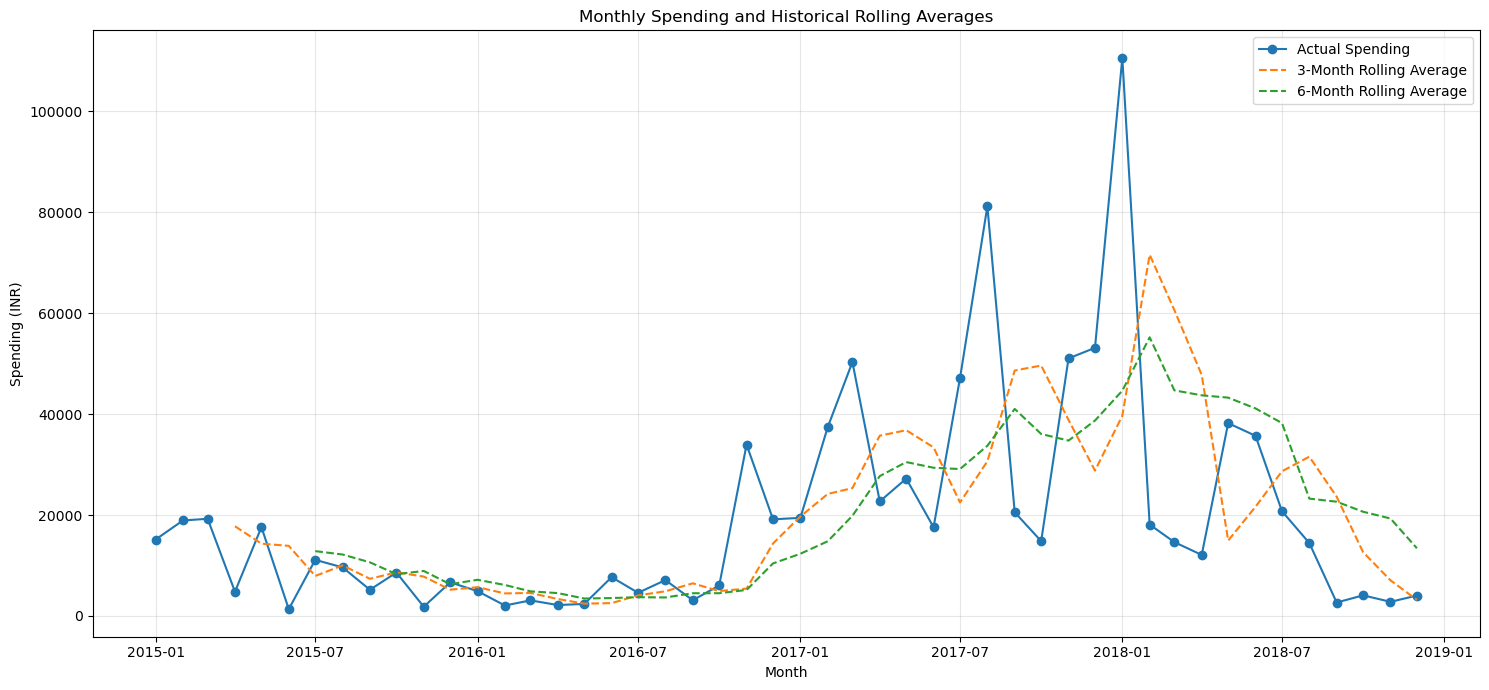


FEATURE DATASET SHAPE: (42, 9)


,Total_Spending,Lag_1,Lag_2,Lag_3,Lag_6,Rolling_Mean_3,Rolling_Mean_6,Rolling_Std_3,Recent_Trend
2015-07,11115.0,1343.0,17603.0,4806.0,15144.0,7917.333333,12844.800000,8564.881571,-3463.0
2015-08,9624.0,11115.0,1343.0,17603.0,18919.0,10020.333333,12173.300000,8185.085298,-6488.0
2015-09,5185.0,9624.0,11115.0,1343.0,19253.8,7360.666667,10624.133333,5264.504187,8281.0
2015-10,8604.6,5185.0,9624.0,11115.0,4806.0,8641.333333,8279.333333,3084.712358,-5930.0
2015-11,1822.0,8604.6,5185.0,9624.0,17603.0,7804.533333,8912.433333,2325.136610,-1019.4



STEP 14 COMPLETED


In [15]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# STEP 14: FEATURE ENGINEERING
# ============================================================

# ------------------------------------------------------------
# 1. CREATE HISTORICAL SPENDING FEATURES
# ------------------------------------------------------------

feature_data = monthly_spending.to_frame(
    name="Total_Spending"
)

# Previous month spending
feature_data["Lag_1"] = (
    feature_data["Total_Spending"].shift(1)
)

# Previous two months
feature_data["Lag_2"] = (
    feature_data["Total_Spending"].shift(2)
)

# Previous three months
feature_data["Lag_3"] = (
    feature_data["Total_Spending"].shift(3)
)

# Previous six months
feature_data["Lag_6"] = (
    feature_data["Total_Spending"].shift(6)
)

# Rolling averages — shifted to avoid using current-month information
feature_data["Rolling_Mean_3"] = (
    feature_data["Total_Spending"]
    .shift(1)
    .rolling(window=3)
    .mean()
)

feature_data["Rolling_Mean_6"] = (
    feature_data["Total_Spending"]
    .shift(1)
    .rolling(window=6)
    .mean()
)

# Rolling standard deviation
feature_data["Rolling_Std_3"] = (
    feature_data["Total_Spending"]
    .shift(1)
    .rolling(window=3)
    .std()
)

# Recent spending trend
feature_data["Recent_Trend"] = (
    feature_data["Lag_1"] - feature_data["Lag_3"]
)

print("FEATURE ENGINEERING RESULTS")

display(feature_data.tail(15).round(2))

# ------------------------------------------------------------
# 2. CHECK MISSING VALUES
# ------------------------------------------------------------

print("\nMISSING VALUES BY FEATURE")

display(
    feature_data.isnull().sum().to_frame(
        name="Missing_Values"
    )
)

# ------------------------------------------------------------
# 3. FEATURE CORRELATION
# ------------------------------------------------------------

print("\nFEATURE CORRELATION WITH MONTHLY SPENDING")

feature_correlations = (
    feature_data.corr(numeric_only=True)["Total_Spending"]
    .drop("Total_Spending")
    .sort_values(ascending=False)
)

display(feature_correlations.to_frame(
    name="Correlation_With_Spending"
).round(3))

# ------------------------------------------------------------
# 4. VISUALIZE SPENDING AND ROLLING AVERAGES
# ------------------------------------------------------------

plt.figure(figsize=(15, 7))

plt.plot(
    feature_data.index.to_timestamp(),
    feature_data["Total_Spending"],
    marker="o",
    label="Actual Spending"
)

plt.plot(
    feature_data.index.to_timestamp(),
    feature_data["Rolling_Mean_3"],
    linestyle="--",
    label="3-Month Rolling Average"
)

plt.plot(
    feature_data.index.to_timestamp(),
    feature_data["Rolling_Mean_6"],
    linestyle="--",
    label="6-Month Rolling Average"
)

plt.title("Monthly Spending and Historical Rolling Averages")
plt.xlabel("Month")
plt.ylabel("Spending (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. FINAL FEATURE DATASET
# ------------------------------------------------------------

model_features = feature_data.dropna().copy()

print("\nFEATURE DATASET SHAPE:", model_features.shape)

display(model_features.head())

print("\nSTEP 14 COMPLETED")


FEATURE-BASED FORECASTING
Training begins with 24 historical months.
Evaluation months: 24
Completed: 2017-01
Completed: 2017-02
Completed: 2017-03
Completed: 2017-04
Completed: 2017-05
Completed: 2017-06
Completed: 2017-07
Completed: 2017-08
Completed: 2017-09
Completed: 2017-10
Completed: 2017-11
Completed: 2017-12
Completed: 2018-01
Completed: 2018-02
Completed: 2018-03
Completed: 2018-04
Completed: 2018-05
Completed: 2018-06
Completed: 2018-07
Completed: 2018-08
Completed: 2018-09
Completed: 2018-10
Completed: 2018-11
Completed: 2018-12

ML FORECAST PREDICTIONS


,Actual,Naive,Ridge,Random_Forest
Month,,,,
2017-01,19440.00,19146.60,17195.21,12117.39
2017-02,37415.00,19440.00,20449.50,12749.70
2017-03,50320.52,37415.00,31133.46,19934.39
2017-04,22691.68,50320.52,52039.21,28213.03
2017-05,27220.00,22691.68,28273.44,27146.31
2017-06,17581.60,27220.00,37644.57,28805.44
2017-07,47148.10,17581.60,17911.47,24898.23
2017-08,81199.70,47148.10,28331.95,29382.54
2017-09,20542.00,81199.70,73245.96,34006.13



FEATURE-BASED MODEL PERFORMANCE


,Model,MAE,RMSE,Bias,Negative_Predictions
0,Naive,19286.35,29860.50,629.57,0
2,Random_Forest,20479.06,26551.65,-2227.98,0
1,Ridge,23617.95,30871.04,4593.04,0



COMPLETE WALK-FORWARD MODEL COMPARISON


,Model,MAE,RMSE
0,Naive,19286.35,29860.50
1,Naive,19286.35,29860.50
2,Drift,19435.36,30303.23
3,Random_Forest,20479.06,26551.65
4,Historical_Mean,20981.73,29854.56
5,Damped_Trend,21158.25,26769.00
6,Holt,21236.95,26933.41
7,SES,22277.63,27834.12
8,ARIMA_011,22303.26,27873.23
9,ARIMA_111,22336.65,28349.72


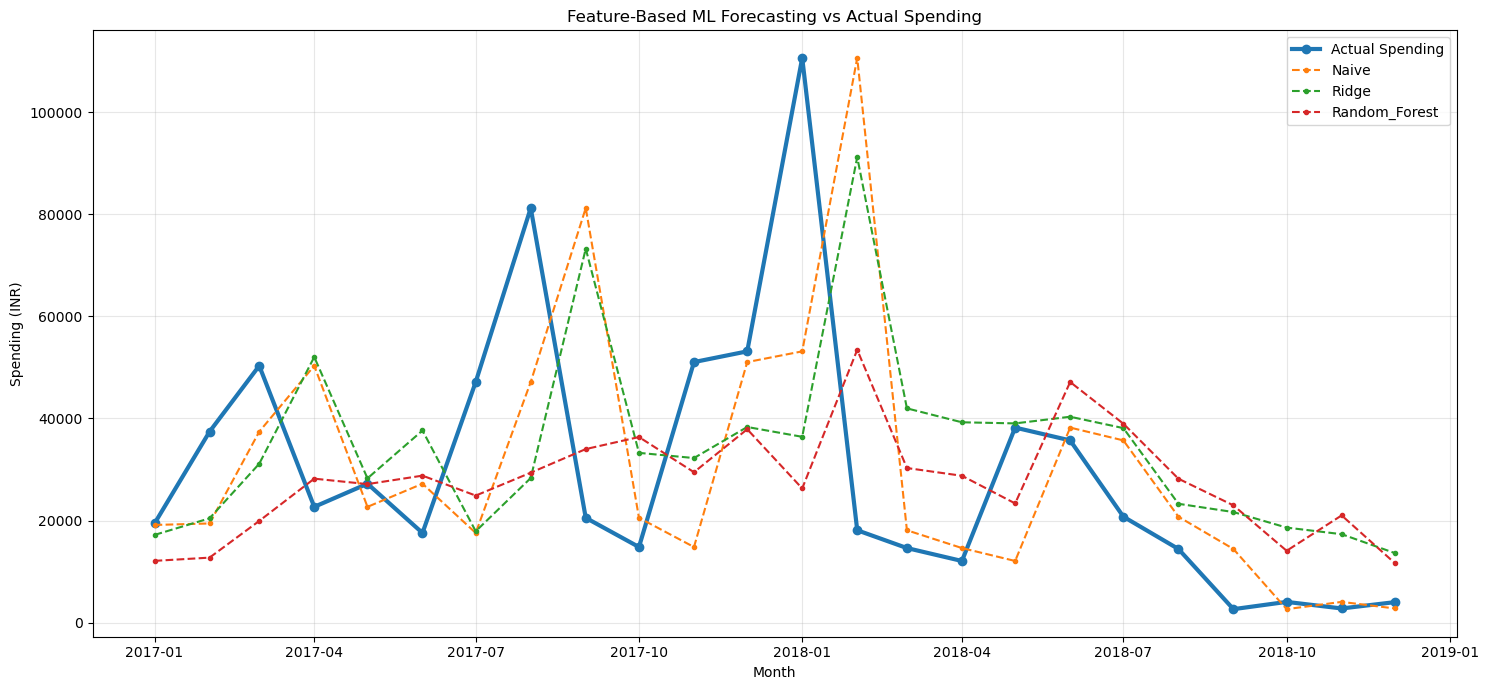


RANDOM FOREST FEATURE IMPORTANCE


,Feature,Importance
0,Lag_1,0.5559
4,Rolling_Mean_3,0.1147
3,Lag_6,0.1072
1,Lag_2,0.0786
5,Rolling_Mean_6,0.0647
2,Lag_3,0.0457
7,Recent_Trend,0.0232
6,Rolling_Std_3,0.0101


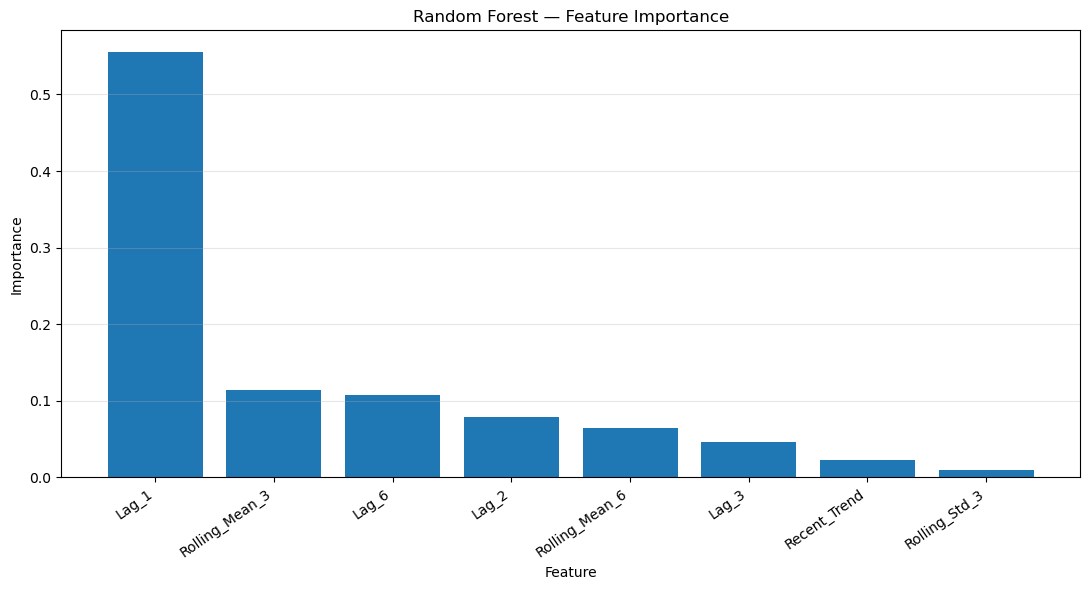


STEP 15 COMPLETED
Best model: Naive
Best MAE: 19286.35


In [16]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# STEP 15: FEATURE-BASED ML FORECASTING
# ============================================================

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. PREPARE FEATURES
# ------------------------------------------------------------

feature_columns = [
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Lag_6",
    "Rolling_Mean_3",
    "Rolling_Mean_6",
    "Rolling_Std_3",
    "Recent_Trend"
]

target_column = "Total_Spending"

MIN_TRAIN_SIZE = 24

# Use the original 24 forecast origins from Step 11
prediction_dates = monthly_spending.index[MIN_TRAIN_SIZE:]

ml_predictions = {
    "Naive": [],
    "Ridge": [],
    "Random_Forest": []
}

print("FEATURE-BASED FORECASTING")
print("Training begins with 24 historical months.")
print("Evaluation months:", len(prediction_dates))

# ------------------------------------------------------------
# 2. WALK-FORWARD MACHINE LEARNING
# ------------------------------------------------------------

for i in range(MIN_TRAIN_SIZE, len(monthly_spending)):

    target_month = monthly_spending.index[i]

    # Historical supervised observations only.
    # The target month is excluded from training.
    train_data = feature_data.iloc[6:i].dropna()

    # Features available at the target forecast origin
    test_data = feature_data.loc[[target_month]]

    X_train = train_data[feature_columns]
    y_train = train_data[target_column]

    X_test = test_data[feature_columns]

    # Baseline: previous month's actual spending
    naive_prediction = float(monthly_spending.iloc[i - 1])

    # Ridge Regression
    ridge_model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    )

    ridge_model.fit(X_train, y_train)

    ridge_prediction = float(
        ridge_model.predict(X_test)[0]
    )

    # Random Forest with conservative complexity
    rf_model = RandomForestRegressor(
        n_estimators=200,
        max_depth=2,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )

    rf_model.fit(X_train, y_train)

    rf_prediction = float(
        rf_model.predict(X_test)[0]
    )

    ml_predictions["Naive"].append(naive_prediction)
    ml_predictions["Ridge"].append(ridge_prediction)
    ml_predictions["Random_Forest"].append(rf_prediction)

    print("Completed:", target_month)

# ------------------------------------------------------------
# 3. CREATE PREDICTION TABLE
# ------------------------------------------------------------

ml_results = pd.DataFrame(
    ml_predictions,
    index=prediction_dates
)

ml_results.index.name = "Month"

ml_results.insert(
    0,
    "Actual",
    monthly_spending.loc[prediction_dates]
)

print("\nML FORECAST PREDICTIONS")

display(ml_results.round(2))

# ------------------------------------------------------------
# 4. CALCULATE PERFORMANCE METRICS
# ------------------------------------------------------------

ml_metrics = []

for model in ml_predictions:

    actual = ml_results["Actual"]
    predicted = ml_results[model]

    ml_metrics.append({
        "Model": model,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "Bias": (predicted - actual).mean(),
        "Negative_Predictions": (predicted < 0).sum()
    })

ml_metrics = pd.DataFrame(ml_metrics)

print("\nFEATURE-BASED MODEL PERFORMANCE")

display(
    ml_metrics.sort_values("MAE").round(2)
)

# ------------------------------------------------------------
# 5. COMPARE WITH STEP 11 RESULTS
# ------------------------------------------------------------

previous_metrics = walk_forward_metrics[
    ["Model", "MAE", "RMSE"]
].copy()

new_metrics = ml_metrics[
    ["Model", "MAE", "RMSE"]
].copy()

combined_metrics = pd.concat(
    [previous_metrics, new_metrics],
    ignore_index=True
)

combined_metrics = combined_metrics.sort_values(
    "MAE"
).reset_index(drop=True)

print("\nCOMPLETE WALK-FORWARD MODEL COMPARISON")

display(combined_metrics.round(2))

# ------------------------------------------------------------
# 6. VISUALIZE PREDICTIONS
# ------------------------------------------------------------

plt.figure(figsize=(15, 7))

plt.plot(
    ml_results.index.to_timestamp(),
    ml_results["Actual"],
    marker="o",
    linewidth=3,
    label="Actual Spending"
)

for model in ml_predictions:

    plt.plot(
        ml_results.index.to_timestamp(),
        ml_results[model],
        marker=".",
        linestyle="--",
        label=model
    )

plt.title("Feature-Based ML Forecasting vs Actual Spending")
plt.xlabel("Month")
plt.ylabel("Spending (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. FEATURE IMPORTANCE — RANDOM FOREST
# ------------------------------------------------------------

rf_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

print("\nRANDOM FOREST FEATURE IMPORTANCE")

display(rf_importance.round(4))

plt.figure(figsize=(11, 6))

plt.bar(
    rf_importance["Feature"],
    rf_importance["Importance"]
)

plt.title("Random Forest — Feature Importance")
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. FINAL SUMMARY
# ------------------------------------------------------------

print("\nSTEP 15 COMPLETED")

print(
    "Best model:",
    combined_metrics.iloc[0]["Model"]
)

print(
    "Best MAE:",
    round(combined_metrics.iloc[0]["MAE"], 2)
)


RANDOM FOREST HYPERPARAMETER EXPERIMENT
Configurations: 6
Evaluation months: 24

Testing RF_Config_1: {'n_estimators': 100, 'max_depth': 2, 'min_samples_leaf': 2, 'max_features': 1.0}
RF_Config_1 completed.

Testing RF_Config_2: {'n_estimators': 200, 'max_depth': 2, 'min_samples_leaf': 3, 'max_features': 1.0}
RF_Config_2 completed.

Testing RF_Config_3: {'n_estimators': 300, 'max_depth': 3, 'min_samples_leaf': 3, 'max_features': 1.0}
RF_Config_3 completed.

Testing RF_Config_4: {'n_estimators': 200, 'max_depth': 3, 'min_samples_leaf': 5, 'max_features': 0.7}
RF_Config_4 completed.

Testing RF_Config_5: {'n_estimators': 300, 'max_depth': 4, 'min_samples_leaf': 3, 'max_features': 0.7}
RF_Config_5 completed.

Testing RF_Config_6: {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 5, 'max_features': 0.7}
RF_Config_6 completed.

RANDOM FOREST CONFIGURATION RESULTS


,Model,MAE,RMSE,Bias,Negative_Predictions
0,RF_Config_2,20479.06,26551.65,-2227.98,0
1,RF_Config_3,20512.58,26762.24,-2273.50,0
2,RF_Config_1,20548.94,26504.71,-1267.14,0
3,RF_Config_5,20647.32,26661.66,-1797.34,0
4,RF_Config_6,21285.48,27143.32,-3248.11,0
5,RF_Config_4,21289.03,27144.64,-3244.55,0



RANDOM FOREST VS NAIVE


,Model,MAE,RMSE,Bias,Negative_Predictions
0,Naive_Benchmark,19286.35,29860.50,629.57,0
1,RF_Config_2,20479.06,26551.65,-2227.98,0
2,RF_Config_3,20512.58,26762.24,-2273.50,0
3,RF_Config_1,20548.94,26504.71,-1267.14,0
4,RF_Config_5,20647.32,26661.66,-1797.34,0
5,RF_Config_6,21285.48,27143.32,-3248.11,0
6,RF_Config_4,21289.03,27144.64,-3244.55,0



BEST RANDOM FOREST CONFIGURATION BY MAE
RF_Config_2
{'n_estimators': 200, 'max_depth': 2, 'min_samples_leaf': 3, 'max_features': 1.0}


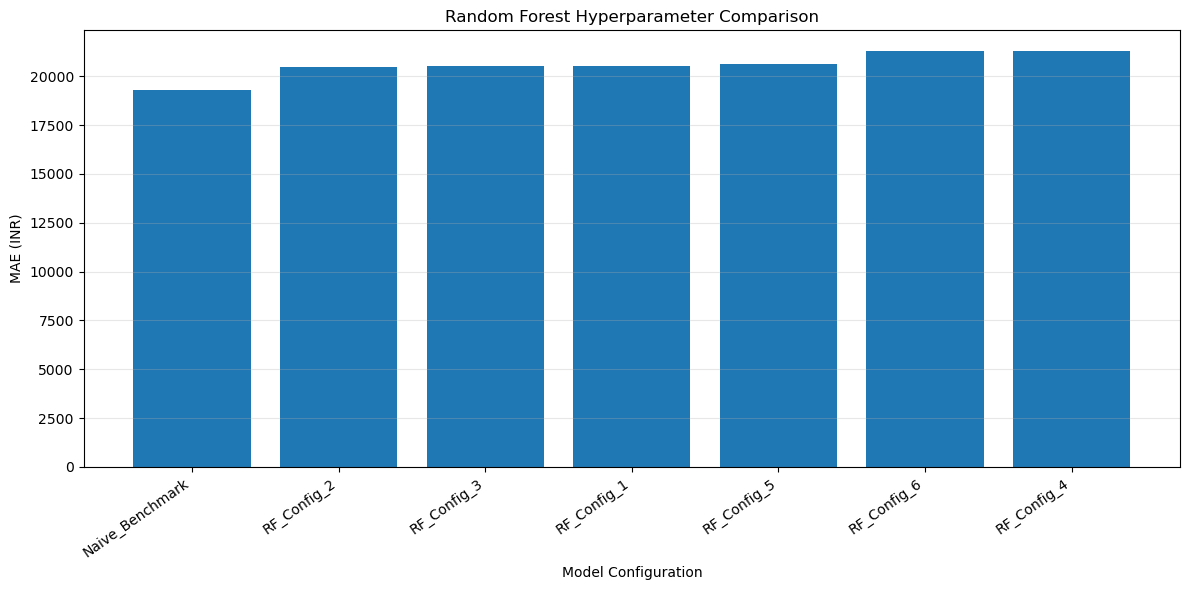

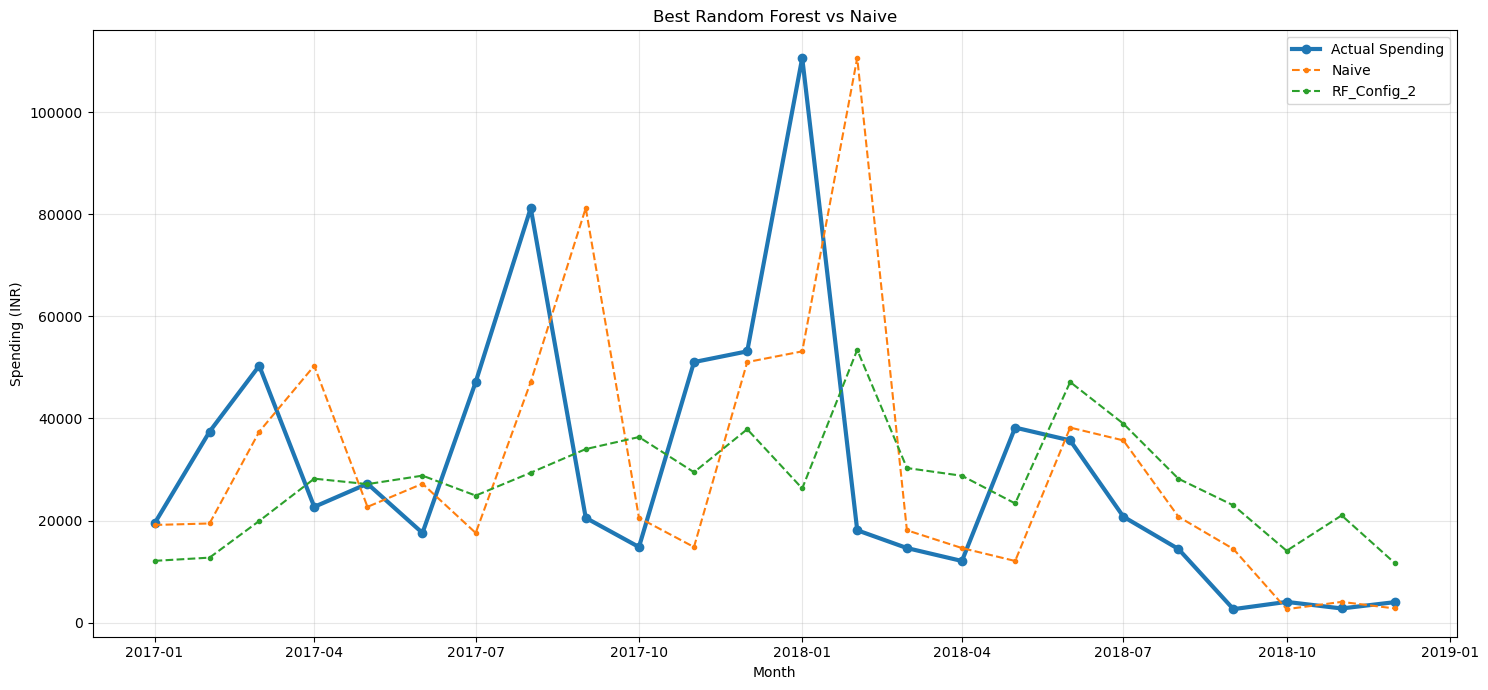


STEP 16 COMPLETED
Best RF configuration: RF_Config_2
Random Forest MAE: 20479.06
Naive MAE: 19286.35
RF did not beat Naive on MAE.


In [17]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# STEP 16: RANDOM FOREST HYPERPARAMETER OPTIMIZATION
# ============================================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. PREPARE DATA
# ------------------------------------------------------------

MIN_TRAIN_SIZE = 24

prediction_dates = monthly_spending.index[MIN_TRAIN_SIZE:]

feature_columns = [
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Lag_6",
    "Rolling_Mean_3",
    "Rolling_Mean_6",
    "Rolling_Std_3",
    "Recent_Trend"
]

# Small, controlled hyperparameter search
rf_configurations = [
    {
        "n_estimators": 100,
        "max_depth": 2,
        "min_samples_leaf": 2,
        "max_features": 1.0
    },
    {
        "n_estimators": 200,
        "max_depth": 2,
        "min_samples_leaf": 3,
        "max_features": 1.0
    },
    {
        "n_estimators": 300,
        "max_depth": 3,
        "min_samples_leaf": 3,
        "max_features": 1.0
    },
    {
        "n_estimators": 200,
        "max_depth": 3,
        "min_samples_leaf": 5,
        "max_features": 0.7
    },
    {
        "n_estimators": 300,
        "max_depth": 4,
        "min_samples_leaf": 3,
        "max_features": 0.7
    },
    {
        "n_estimators": 200,
        "max_depth": None,
        "min_samples_leaf": 5,
        "max_features": 0.7
    }
]

rf_tuning_predictions = {}

print("RANDOM FOREST HYPERPARAMETER EXPERIMENT")
print("Configurations:", len(rf_configurations))
print("Evaluation months:", len(prediction_dates))

# ------------------------------------------------------------
# 2. WALK-FORWARD TRAINING FOR EACH CONFIGURATION
# ------------------------------------------------------------

for config_number, config in enumerate(
    rf_configurations, start=1
):

    model_name = f"RF_Config_{config_number}"

    predictions = []

    print(f"\nTesting {model_name}: {config}")

    for i in range(MIN_TRAIN_SIZE, len(monthly_spending)):

        target_month = monthly_spending.index[i]

        # Historical observations only
        train_data = feature_data.iloc[6:i].dropna()

        test_data = feature_data.loc[[target_month]]

        X_train = train_data[feature_columns]
        y_train = train_data["Total_Spending"]

        X_test = test_data[feature_columns]

        model = RandomForestRegressor(
            **config,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train, y_train)

        prediction = float(
            model.predict(X_test)[0]
        )

        predictions.append(prediction)

    rf_tuning_predictions[model_name] = pd.Series(
        predictions,
        index=prediction_dates
    )

    print(f"{model_name} completed.")

# ------------------------------------------------------------
# 3. CALCULATE MODEL PERFORMANCE
# ------------------------------------------------------------

actual_values = monthly_spending.loc[prediction_dates]

rf_tuning_metrics = []

for model_name, predictions in rf_tuning_predictions.items():

    rf_tuning_metrics.append({
        "Model": model_name,
        "MAE": mean_absolute_error(
            actual_values, predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                actual_values, predictions
            )
        ),
        "Bias": (predictions - actual_values).mean(),
        "Negative_Predictions": (predictions < 0).sum()
    })

rf_tuning_metrics = pd.DataFrame(
    rf_tuning_metrics
).sort_values("MAE").reset_index(drop=True)

print("\nRANDOM FOREST CONFIGURATION RESULTS")

display(rf_tuning_metrics.round(2))

# ------------------------------------------------------------
# 4. COMPARE WITH NAIVE BENCHMARK
# ------------------------------------------------------------

naive_predictions = monthly_spending.shift(1).loc[
    prediction_dates
]

naive_mae = mean_absolute_error(
    actual_values, naive_predictions
)

naive_rmse = np.sqrt(
    mean_squared_error(
        actual_values, naive_predictions
    )
)

benchmark_row = pd.DataFrame([{
    "Model": "Naive_Benchmark",
    "MAE": naive_mae,
    "RMSE": naive_rmse,
    "Bias": (naive_predictions - actual_values).mean(),
    "Negative_Predictions": 0
}])

rf_complete_comparison = pd.concat(
    [benchmark_row, rf_tuning_metrics],
    ignore_index=True
).sort_values("MAE").reset_index(drop=True)

print("\nRANDOM FOREST VS NAIVE")

display(rf_complete_comparison.round(2))

# ------------------------------------------------------------
# 5. IDENTIFY BEST CONFIGURATION
# ------------------------------------------------------------

best_rf_name = rf_tuning_metrics.iloc[0]["Model"]

best_rf_config = rf_configurations[
    int(best_rf_name.split("_")[-1]) - 1
]

print("\nBEST RANDOM FOREST CONFIGURATION BY MAE")
print(best_rf_name)
print(best_rf_config)

# ------------------------------------------------------------
# 6. VISUALIZE MAE COMPARISON
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

plt.bar(
    rf_complete_comparison["Model"],
    rf_complete_comparison["MAE"]
)

plt.title("Random Forest Hyperparameter Comparison")
plt.xlabel("Model Configuration")
plt.ylabel("MAE (INR)")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. VISUALIZE BEST CONFIGURATION
# ------------------------------------------------------------

best_predictions = rf_tuning_predictions[best_rf_name]

plt.figure(figsize=(15, 7))

plt.plot(
    prediction_dates.to_timestamp(),
    actual_values.values,
    marker="o",
    linewidth=3,
    label="Actual Spending"
)

plt.plot(
    prediction_dates.to_timestamp(),
    naive_predictions.values,
    linestyle="--",
    marker=".",
    label="Naive"
)

plt.plot(
    prediction_dates.to_timestamp(),
    best_predictions.values,
    linestyle="--",
    marker=".",
    label=best_rf_name
)

plt.title("Best Random Forest vs Naive")
plt.xlabel("Month")
plt.ylabel("Spending (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. FINAL SUMMARY
# ------------------------------------------------------------

print("\nSTEP 16 COMPLETED")

print("Best RF configuration:", best_rf_name)

print(
    "Random Forest MAE:",
    round(
        rf_tuning_metrics.iloc[0]["MAE"], 2
    )
)

print("Naive MAE:", round(naive_mae, 2))

if rf_tuning_metrics.iloc[0]["MAE"] < naive_mae:
    print("RF achieved lower MAE than Naive.")
else:
    print("RF did not beat Naive on MAE.")


FINAL MODEL EVALUATION
Evaluation observations: 24


,Actual,Naive,Damped_Trend,Random_Forest
2017-01,19440.00,19146.60,21371.74,12117.39
2017-02,37415.00,19440.00,23774.48,12749.70
2017-03,50320.52,37415.00,34388.17,19934.39
2017-04,22691.68,50320.52,48054.91,28213.03
2017-05,27220.00,22691.68,41162.46,27146.31
2017-06,17581.60,27220.00,39394.18,28805.44
2017-07,47148.10,17581.60,24238.40,24898.23
2017-08,81199.70,47148.10,39718.53,29382.54
2017-09,20542.00,81199.70,56250.80,34006.13
2017-10,14826.47,20542.00,49571.74,36361.60



OVERALL MODEL PERFORMANCE


,Model,MAE,RMSE,Bias,Negative_Predictions
0,Naive,19286.35,29860.50,629.57,0
1,Random_Forest,20479.06,26551.65,-2227.98,0
2,Damped_Trend,21158.25,26769.00,6317.95,1



YEAR-WISE MODEL PERFORMANCE


,Year,Model,MAE,RMSE
2,2017,Random_Forest,18756.08,22848.15
0,2017,Naive,20106.20,26501.59
1,2017,Damped_Trend,20166.24,23436.67
3,2018,Naive,18466.51,32878.03
4,2018,Damped_Trend,22150.25,29730.15
5,2018,Random_Forest,22202.04,29798.36



MONTHS WITH THE LARGEST NAIVE FORECAST ERRORS


,Actual,Naive,Naive_Error,Naive_Absolute_Error
2018-02,18109.00,110603.58,92494.58,92494.58
2017-09,20542.00,81199.70,60657.70,60657.70
2018-01,110603.58,53140.00,-57463.58,57463.58
2017-11,51039.60,14826.47,-36213.13,36213.13
2017-08,81199.70,47148.10,-34051.60,34051.60
2017-07,47148.10,17581.60,-29566.50,29566.50
2017-04,22691.68,50320.52,27628.84,27628.84
2018-05,38214.00,12094.00,-26120.00,26120.00
2017-02,37415.00,19440.00,-17975.00,17975.00
2018-07,20762.36,35701.02,14938.66,14938.66


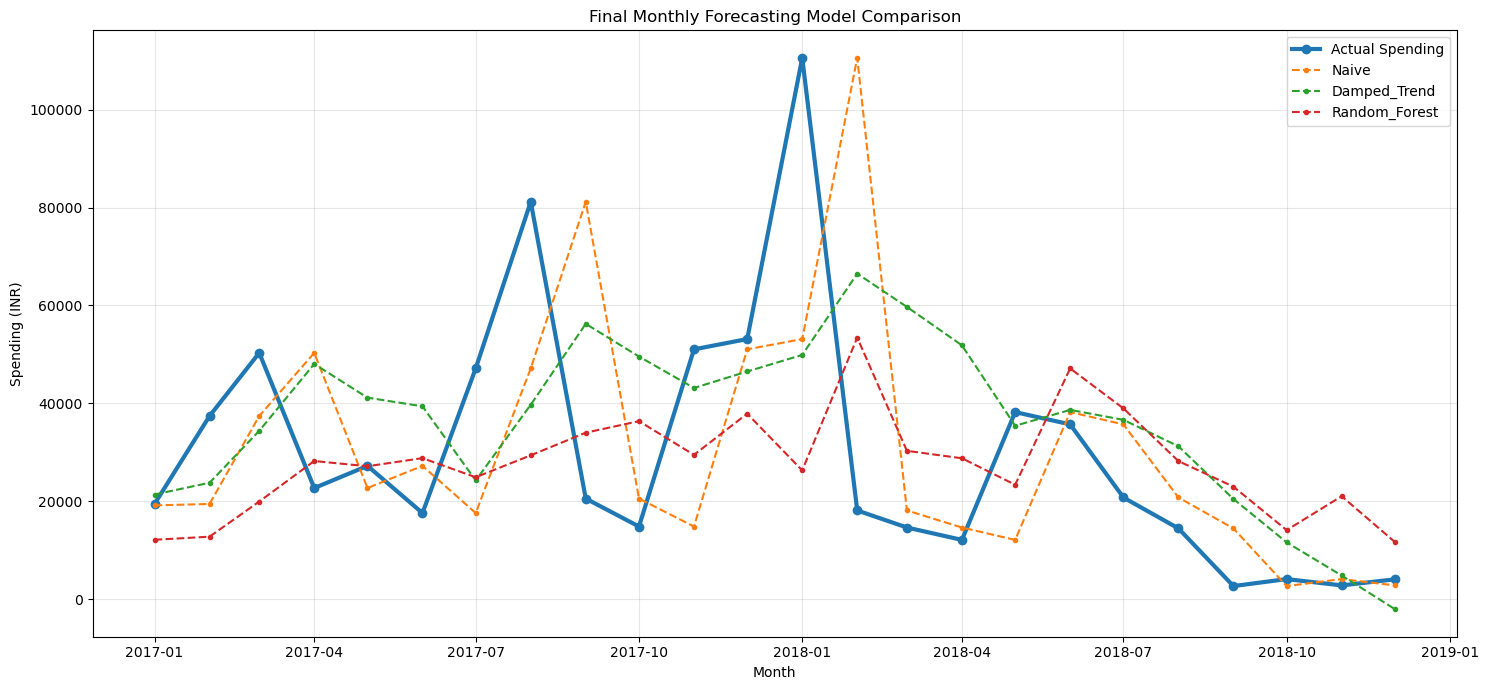


PRELIMINARY MODEL DECISION
Best model by MAE: Naive
Best model by RMSE: Random_Forest

IMPORTANT EVALUATION LIMITATION
These 24 evaluation months have already been examined during earlier experiments. Therefore, this comparison is not an untouched independent test.

STEP 17 COMPLETED


In [18]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# STEP 17: FINAL FORECASTING MODEL EVALUATION
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. PREPARE THE THREE FINAL CANDIDATES
# ------------------------------------------------------------

evaluation_index = monthly_spending.index[24:]

final_comparison = pd.DataFrame(index=evaluation_index)

final_comparison["Actual"] = monthly_spending.loc[evaluation_index]

# Naive benchmark from Step 11
final_comparison["Naive"] = (
    walk_forward_results.loc[evaluation_index, "Naive"]
)

# Damped Trend from Step 11
final_comparison["Damped_Trend"] = (
    walk_forward_results.loc[evaluation_index, "Damped_Trend"]
)

# Best Random Forest configuration from Step 16
final_comparison["Random_Forest"] = (
    rf_tuning_predictions["RF_Config_2"].loc[evaluation_index]
)

print("FINAL MODEL EVALUATION")
print("Evaluation observations:", len(final_comparison))

display(final_comparison.round(2))

# ------------------------------------------------------------
# 2. OVERALL PERFORMANCE
# ------------------------------------------------------------

candidate_models = [
    "Naive",
    "Damped_Trend",
    "Random_Forest"
]

final_metrics = []

for model_name in candidate_models:

    actual = final_comparison["Actual"]
    predicted = final_comparison[model_name]

    final_metrics.append({
        "Model": model_name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "Bias": (predicted - actual).mean(),
        "Negative_Predictions": (predicted < 0).sum()
    })

final_metrics = pd.DataFrame(final_metrics)

final_metrics = final_metrics.sort_values(
    "MAE"
).reset_index(drop=True)

print("\nOVERALL MODEL PERFORMANCE")

display(final_metrics.round(2))

# ------------------------------------------------------------
# 3. YEAR-WISE PERFORMANCE
# ------------------------------------------------------------

yearly_metrics = []

for year in [2017, 2018]:

    year_data = final_comparison[
        final_comparison.index.year == year
    ]

    for model_name in candidate_models:

        actual = year_data["Actual"]
        predicted = year_data[model_name]

        yearly_metrics.append({
            "Year": year,
            "Model": model_name,
            "MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(
                mean_squared_error(actual, predicted)
            )
        })

yearly_metrics = pd.DataFrame(yearly_metrics)

print("\nYEAR-WISE MODEL PERFORMANCE")

display(
    yearly_metrics.sort_values(
        ["Year", "MAE"]
    ).round(2)
)

# ------------------------------------------------------------
# 4. ERROR ANALYSIS
# ------------------------------------------------------------

error_analysis = final_comparison.copy()

for model_name in candidate_models:

    error_analysis[f"{model_name}_Error"] = (
        error_analysis[model_name] -
        error_analysis["Actual"]
    )

    error_analysis[f"{model_name}_Absolute_Error"] = (
        error_analysis[f"{model_name}_Error"].abs()
    )

print("\nMONTHS WITH THE LARGEST NAIVE FORECAST ERRORS")

display(
    error_analysis[
        ["Actual", "Naive", "Naive_Error", "Naive_Absolute_Error"]
    ]
    .sort_values("Naive_Absolute_Error", ascending=False)
    .head(10)
    .round(2)
)

# ------------------------------------------------------------
# 5. VISUAL COMPARISON
# ------------------------------------------------------------

plt.figure(figsize=(15, 7))

plt.plot(
    final_comparison.index.to_timestamp(),
    final_comparison["Actual"],
    marker="o",
    linewidth=3,
    label="Actual Spending"
)

for model_name in candidate_models:

    plt.plot(
        final_comparison.index.to_timestamp(),
        final_comparison[model_name],
        marker=".",
        linestyle="--",
        label=model_name
    )

plt.title("Final Monthly Forecasting Model Comparison")
plt.xlabel("Month")
plt.ylabel("Spending (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. PRELIMINARY MODEL DECISION
# ------------------------------------------------------------

best_mae_model = final_metrics.iloc[0]["Model"]
best_rmse_model = final_metrics.loc[
    final_metrics["RMSE"].idxmin(), "Model"
]

print("\nPRELIMINARY MODEL DECISION")
print("Best model by MAE:", best_mae_model)
print("Best model by RMSE:", best_rmse_model)

print("\nIMPORTANT EVALUATION LIMITATION")
print(
    "These 24 evaluation months have already been examined "
    "during earlier experiments. Therefore, this comparison "
    "is not an untouched independent test."
)

print("\nSTEP 17 COMPLETED")


In [19]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# STEP 18: PACKAGE MONTHLY FORECASTING MODULE
# ============================================================

from pathlib import Path
import textwrap
import joblib
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. LOCATE PROJECT ROOT
# ------------------------------------------------------------

current_path = Path.cwd().resolve()

possible_roots = [current_path] + list(current_path.parents)

project_root = None

for folder in possible_roots:
    if (folder / "data").exists() and (folder / "models").exists():
        project_root = folder
        break

if project_root is None:
    project_root = current_path

models_dir = project_root / "models"
forecasting_dir = project_root / "src" / "forecasting"

models_dir.mkdir(parents=True, exist_ok=True)
forecasting_dir.mkdir(parents=True, exist_ok=True)

print("Project root:", project_root)

# ------------------------------------------------------------
# 2. CREATE REUSABLE FORECASTING PYTHON MODULE
# ------------------------------------------------------------

module_code = '''
import pandas as pd


def forecast_monthly_spending(
    monthly_spending,
    periods=1
):
    """
    Forecast monthly spending using the Naive benchmark.

    Parameters
    ----------
    monthly_spending : pandas.Series
        Historical monthly spending values.
        Index should contain monthly Period values or dates.

    periods : int
        Number of future months to forecast.

    Returns
    -------
    pandas.DataFrame
        Forecast values indexed by future months.

    Notes
    -----
    Naive forecasting repeats the latest observed monthly
    spending value for each future month.

    This is a baseline method, not a model that learns
    spending behaviour or predicts unusual events.
    """

    if not isinstance(monthly_spending, pd.Series):
        raise TypeError(
            "monthly_spending must be a pandas Series."
        )

    if periods < 1:
        raise ValueError(
            "periods must be at least 1."
        )

    historical = monthly_spending.dropna().sort_index()

    if historical.empty:
        raise ValueError(
            "No valid historical spending observations."
        )

    last_value = float(historical.iloc[-1])

    if last_value < 0:
        raise ValueError(
            "Historical spending cannot be negative."
        )

    last_index = historical.index[-1]

    if isinstance(last_index, pd.Period):
        future_index = pd.period_range(
            start=last_index + 1,
            periods=periods,
            freq="M"
        )
    else:
        last_month = pd.Timestamp(last_index).to_period("M")

        future_index = pd.period_range(
            start=last_month + 1,
            periods=periods,
            freq="M"
        )

    forecast = pd.DataFrame(
        {
            "Forecast_Spending": [
                last_value
            ] * periods
        },
        index=future_index
    )

    forecast.index.name = "Month"

    return forecast
'''

module_path = forecasting_dir / "monthly_forecasting.py"

module_path.write_text(
    textwrap.dedent(module_code).strip() + "\n",
    encoding="utf-8"
)

print("Python module created:", module_path)

# ------------------------------------------------------------
# 3. CREATE MODEL METADATA BUNDLE
# ------------------------------------------------------------

monthly_bundle = {
    "project": "ForeSight",
    "module": "monthly_forecasting",
    "model_name": "Naive",
    "model_type": "Baseline Time Series Forecasting",
    "forecast_frequency": "Monthly",
    "forecast_horizon_supported": "1 or more months",
    "selected_reason": (
        "Lowest MAE among evaluated candidate models."
    ),
    "evaluation_period": "2017-01 to 2018-12",
    "evaluation_observations": 24,
    "evaluation_metrics": {
        "MAE": float(
            final_metrics.loc[
                final_metrics["Model"] == "Naive", "MAE"
            ].iloc[0]
        ),
        "RMSE": float(
            final_metrics.loc[
                final_metrics["Model"] == "Naive", "RMSE"
            ].iloc[0]
        ),
        "Bias": float(
            final_metrics.loc[
                final_metrics["Model"] == "Naive", "Bias"
            ].iloc[0]
        )
    },
    "training_data_start": str(monthly_spending.index.min()),
    "training_data_end": str(monthly_spending.index.max()),
    "training_observations": int(len(monthly_spending)),
    "alternative_model": "Random Forest",
    "alternative_model_mae": float(
        final_metrics.loc[
            final_metrics["Model"] == "Random_Forest", "MAE"
        ].iloc[0]
    ),
    "limitations": [
        "Evaluation uses one household's historical data.",
        "Historical data ends in December 2018.",
        "Evaluation period was reused during experimentation.",
        "Naive forecasting cannot anticipate unusual expenses.",
        "Recent real spending data is required for current forecasts."
    ]
}

bundle_path = models_dir / "monthly_forecasting_bundle.joblib"

joblib.dump(monthly_bundle, bundle_path)

print("Forecasting bundle saved:", bundle_path)

# ------------------------------------------------------------
# 4. IMPORT AND TEST THE NEW MODULE
# ------------------------------------------------------------

import importlib.util

spec = importlib.util.spec_from_file_location(
    "monthly_forecasting",
    module_path
)

monthly_module = importlib.util.module_from_spec(spec)

spec.loader.exec_module(monthly_module)

forecast_monthly_spending = (
    monthly_module.forecast_monthly_spending
)

# ------------------------------------------------------------
# 5. TEST ONE-MONTH FORECAST
# ------------------------------------------------------------

test_forecast = forecast_monthly_spending(
    monthly_spending,
    periods=1
)

print("\nONE-MONTH FORECAST TEST")
display(test_forecast)

# ------------------------------------------------------------
# 6. TEST MULTI-MONTH FORECAST
# ------------------------------------------------------------

test_multi_forecast = forecast_monthly_spending(
    monthly_spending,
    periods=3
)

print("\nTHREE-MONTH FORECAST TEST")
display(test_multi_forecast)

# ------------------------------------------------------------
# 7. VERIFY SAVED BUNDLE
# ------------------------------------------------------------

loaded_bundle = joblib.load(bundle_path)

print("\nSAVED MODEL INFORMATION")
print("Model:", loaded_bundle["model_name"])
print("Evaluation MAE:", loaded_bundle["evaluation_metrics"]["MAE"])
print("Evaluation RMSE:", loaded_bundle["evaluation_metrics"]["RMSE"])
print("Data ends:", loaded_bundle["training_data_end"])

print("\nSTEP 18 COMPLETED")


Project root: C:\Users\singh\Desktop\foresight
Python module created: C:\Users\singh\Desktop\foresight\src\forecasting\monthly_forecasting.py
Forecasting bundle saved: C:\Users\singh\Desktop\foresight\models\monthly_forecasting_bundle.joblib

ONE-MONTH FORECAST TEST


,Forecast_Spending
Month,
2019-01,4037.0



THREE-MONTH FORECAST TEST


,Forecast_Spending
Month,
2019-01,4037.0
2019-02,4037.0
2019-03,4037.0



SAVED MODEL INFORMATION
Model: Naive
Evaluation MAE: 19286.354166666668
Evaluation RMSE: 29860.50151900542
Data ends: 2018-12

STEP 18 COMPLETED


In [20]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# VALIDATION STEP 1: DATA & WALK-FORWARD METHODOLOGY AUDIT
# ============================================================

import numpy as np
import pandas as pd

print("=" * 65)
print("MONTHLY FORECASTING — VALIDATION STEP 1")
print("=" * 65)

checks = []

def audit_check(name, condition, details=""):
    checks.append({
        "Check": name,
        "Status": "PASS" if condition else "FAIL",
        "Details": details
    })

# ------------------------------------------------------------
# 1. REQUIRED NOTEBOOK VARIABLES
# ------------------------------------------------------------

required_variables = [
    "monthly_spending",
    "walk_forward_results",
    "feature_data",
    "feature_columns"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

audit_check(
    "Required variables available",
    len(missing_variables) == 0,
    f"Missing: {missing_variables}"
)

if missing_variables:
    display(pd.DataFrame(checks))
    raise RuntimeError(
        "Required variables are missing. Run the original "
        "Notebook 05 cells before this validation."
    )

y = monthly_spending.copy()
results = walk_forward_results.copy()

# ------------------------------------------------------------
# 2. DATA QUALITY AND CHRONOLOGICAL INDEX
# ------------------------------------------------------------

numeric_values = pd.to_numeric(y, errors="coerce")

audit_check(
    "Monthly data contains 48 observations",
    len(y) == 48,
    f"Observations: {len(y)}"
)

audit_check(
    "Monthly index is a PeriodIndex",
    isinstance(y.index, pd.PeriodIndex),
    f"Index type: {type(y.index).__name__}"
)

if isinstance(y.index, pd.PeriodIndex):
    expected_index = pd.period_range(
        start=y.index.min(),
        end=y.index.max(),
        freq="M"
    )

    audit_check(
        "Monthly index is continuous",
        y.index.equals(expected_index),
        f"Expected months: {len(expected_index)}; "
        f"actual months: {len(y.index)}"
    )
else:
    audit_check(
        "Monthly index is continuous",
        False,
        "Monthly PeriodIndex is required for this audit."
    )

audit_check(
    "Monthly index is sorted and unique",
    y.index.is_monotonic_increasing and y.index.is_unique,
    f"Start: {y.index.min()}, End: {y.index.max()}"
)

audit_check(
    "Spending values are numeric and finite",
    np.isfinite(numeric_values.to_numpy()).all(),
    "Checks for non-numeric and infinite values."
)

audit_check(
    "No negative monthly spending",
    (numeric_values.dropna() >= 0).all(),
    f"Minimum: {numeric_values.min()}"
)

audit_check(
    "No missing monthly spending values",
    not numeric_values.isna().any(),
    f"Missing values: {numeric_values.isna().sum()}"
)

# ------------------------------------------------------------
# 3. WALK-FORWARD EVALUATION ALIGNMENT
# ------------------------------------------------------------

expected_test_index = y.index[24:]

audit_check(
    "Walk-forward evaluation has 24 months",
    len(expected_test_index) == 24,
    f"Expected: 24; actual: {len(results)}"
)

audit_check(
    "Prediction dates match chronological test dates",
    results.index.equals(expected_test_index),
    f"First test month: {expected_test_index[0]}; "
    f"last test month: {expected_test_index[-1]}"
)

audit_check(
    "Actual values match source spending data",
    (
        "Actual" in results.columns
        and np.allclose(
            results["Actual"].to_numpy(dtype=float),
            y.loc[expected_test_index].to_numpy(dtype=float)
        )
    ),
    "Compares walk-forward actual values with monthly_spending."
)

# ------------------------------------------------------------
# 4. VERIFY NAIVE AND SEASONAL NAIVE BASELINES
# ------------------------------------------------------------

expected_naive = y.shift(1).loc[expected_test_index]

audit_check(
    "Naive predictions use previous month's actual",
    (
        "Naive" in results.columns
        and np.allclose(
            results["Naive"].to_numpy(dtype=float),
            expected_naive.to_numpy(dtype=float)
        )
    ),
    "Forecast at month t must equal spending at month t-1."
)

expected_seasonal = y.shift(12).loc[expected_test_index]

audit_check(
    "Seasonal Naive uses previous year's same month",
    (
        "Seasonal_Naive" in results.columns
        and np.allclose(
            results["Seasonal_Naive"].to_numpy(dtype=float),
            expected_seasonal.to_numpy(dtype=float)
        )
    ),
    "Forecast at month t must equal spending at month t-12."
)

# ------------------------------------------------------------
# 5. FEATURE ENGINEERING AUDIT
# ------------------------------------------------------------

expected_features = {
    "Lag_1": y.shift(1),
    "Lag_2": y.shift(2),
    "Lag_3": y.shift(3),
    "Lag_6": y.shift(6),
    "Rolling_Mean_3": y.shift(1).rolling(3).mean(),
    "Rolling_Mean_6": y.shift(1).rolling(6).mean(),
    "Rolling_Std_3": y.shift(1).rolling(3).std(),
    "Recent_Trend": y.shift(1) - y.shift(3)
}

feature_checks = []

for feature_name, expected_values in expected_features.items():

    if feature_name not in feature_data.columns:
        feature_checks.append(False)
        continue

    actual_values = feature_data[feature_name]

    feature_checks.append(
        np.allclose(
            actual_values.to_numpy(dtype=float),
            expected_values.to_numpy(dtype=float),
            equal_nan=True
        )
    )

audit_check(
    "All eight historical features match expected formulas",
    all(feature_checks),
    f"Passed: {sum(feature_checks)}/8"
)

# Verify target-month features do not include target-month spending.
target_feature_checks = []

for i in range(24, len(y)):

    target_month = y.index[i]
    history = y.iloc[:i]

    expected_row = {
        "Lag_1": history.iloc[-1],
        "Lag_2": history.iloc[-2],
        "Lag_3": history.iloc[-3],
        "Lag_6": history.iloc[-6],
        "Rolling_Mean_3": history.iloc[-3:].mean(),
        "Rolling_Mean_6": history.iloc[-6:].mean(),
        "Rolling_Std_3": history.iloc[-3:].std(),
        "Recent_Trend": history.iloc[-1] - history.iloc[-3]
    }

    actual_row = feature_data.loc[target_month]

    target_feature_checks.append(
        all(
            np.isclose(
                float(actual_row[column]),
                float(expected_row[column]),
                equal_nan=True
            )
            for column in expected_row
        )
    )

audit_check(
    "Test-month features use historical observations only",
    all(target_feature_checks),
    f"Passed: {sum(target_feature_checks)}/24 forecast origins"
)

# ------------------------------------------------------------
# 6. MACHINE-LEARNING TRAINING WINDOW AUDIT
# ------------------------------------------------------------

training_window_checks = []

for i in range(24, len(y)):

    target_month = y.index[i]

    train_data = feature_data.iloc[6:i].dropna()

    # Every training target must occur before the forecast month.
    training_window_checks.append(
        len(train_data) > 0
        and train_data.index.max() < target_month
    )

audit_check(
    "ML training windows exclude target and future months",
    all(training_window_checks),
    f"Passed: {sum(training_window_checks)}/24 forecast origins"
)

# ------------------------------------------------------------
# 7. EVALUATION REUSE LIMITATION
# ------------------------------------------------------------

audit_check(
    "Evaluation reuse documented as a limitation",
    True,
    "The same 24 months were reused in model experiments "
    "and RF hyperparameter selection. This is not an "
    "untouched independent test."
)

# ------------------------------------------------------------
# 8. FINAL REPORT
# ------------------------------------------------------------

audit_df = pd.DataFrame(checks)

print("\nVALIDATION RESULTS")
display(audit_df)

passed = (audit_df["Status"] == "PASS").sum()
failed = (audit_df["Status"] == "FAIL").sum()

print("\n" + "=" * 65)
print("STEP 1 SUMMARY")
print("=" * 65)
print("Total checks:", len(audit_df))
print("Passed:", passed)
print("Failed:", failed)

print("\nDATASET SUMMARY")
print("Observations:", len(y))
print("Date range:", y.index.min(), "to", y.index.max())
print("Initial training months: 24")
print("Walk-forward evaluation months:", len(results))
print("Forecast horizon: 1 month")

if failed == 0:
    print("\nSTEP 1 AUDIT: ALL CHECKS PASSED")
else:
    print("\nSTEP 1 AUDIT: REVIEW FAILED CHECKS BEFORE PROCEEDING")

print("\nNo model or saved artifact was modified.")


MONTHLY FORECASTING — VALIDATION STEP 1

VALIDATION RESULTS


,Check,Status,Details
0,Required variables available,PASS,Missing: []
1,Monthly data contains 48 observations,PASS,Observations: 48
2,Monthly index is a PeriodIndex,PASS,Index type: PeriodIndex
3,Monthly index is continuous,PASS,Expected months: 48; actual months: 48
4,Monthly index is sorted and unique,PASS,"Start: 2015-01, End: 2018-12"
5,Spending values are numeric and finite,PASS,Checks for non-numeric and infinite values.
6,No negative monthly spending,PASS,Minimum: 1343.0
7,No missing monthly spending values,PASS,Missing values: 0
8,Walk-forward evaluation has 24 months,PASS,Expected: 24; actual: 24
9,Prediction dates match chronological test dates,PASS,First test month: 2017-01; last test month: 20...



STEP 1 SUMMARY
Total checks: 17
Passed: 17
Failed: 0

DATASET SUMMARY
Observations: 48
Date range: 2015-01 to 2018-12
Initial training months: 24
Walk-forward evaluation months: 24
Forecast horizon: 1 month

STEP 1 AUDIT: ALL CHECKS PASSED

No model or saved artifact was modified.


In [21]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# VALIDATION STEP 2: EVALUATION & MODEL SELECTION AUDIT
# ============================================================

import numpy as np
import pandas as pd

print("=" * 65)
print("MONTHLY FORECASTING — VALIDATION STEP 2")
print("=" * 65)

checks = []

def audit_check(name, condition, details=""):
    checks.append({
        "Check": name,
        "Status": "PASS" if condition else "FAIL",
        "Details": details
    })

# ------------------------------------------------------------
# 1. VERIFY REQUIRED RESULTS
# ------------------------------------------------------------

required = [
    "final_comparison",
    "final_metrics",
    "rf_tuning_metrics",
    "rf_tuning_predictions",
    "rf_configurations",
    "monthly_spending"
]

missing = [v for v in required if v not in globals()]

audit_check(
    "All evaluation variables available",
    len(missing) == 0,
    f"Missing: {missing}"
)

if missing:
    display(pd.DataFrame(checks))
    raise RuntimeError("Run the original Notebook 05 cells first.")

comparison = final_comparison.copy()
actual = comparison["Actual"]

# ------------------------------------------------------------
# 2. CHECK FINAL CANDIDATE COVERAGE
# ------------------------------------------------------------

expected_index = monthly_spending.index[24:]

audit_check(
    "Final evaluation contains 24 observations",
    len(comparison) == 24,
    f"Observations: {len(comparison)}"
)

audit_check(
    "Final comparison uses correct chronological dates",
    comparison.index.equals(expected_index),
    f"Range: {comparison.index.min()} to {comparison.index.max()}"
)

candidate_columns = [
    "Naive",
    "Damped_Trend",
    "Random_Forest"
]

candidate_coverage = all(
    column in comparison.columns
    and comparison[column].notna().all()
    and np.isfinite(comparison[column].to_numpy()).all()
    for column in candidate_columns
)

audit_check(
    "All final candidates have 24 finite predictions",
    candidate_coverage,
    "Naive, Damped Trend and Random Forest."
)

# ------------------------------------------------------------
# 3. INDEPENDENTLY RECALCULATE FINAL METRICS
# ------------------------------------------------------------

recalculated = []

for model in candidate_columns:

    predicted = comparison[model]

    error = predicted - actual

    recalculated.append({
        "Model": model,
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "Bias": np.mean(error),
        "Negative_Predictions": int((predicted < 0).sum())
    })

recalculated_metrics = pd.DataFrame(recalculated)

print("\nINDEPENDENTLY RECALCULATED FINAL METRICS")
display(recalculated_metrics.round(2))

# Compare with original final_metrics
metric_comparison = final_metrics.set_index("Model")

metric_checks = []

for _, row in recalculated_metrics.iterrows():

    model = row["Model"]

    for metric in ["MAE", "RMSE", "Bias"]:

        metric_checks.append(
            model in metric_comparison.index
            and np.isclose(
                row[metric],
                metric_comparison.loc[model, metric],
                rtol=1e-7,
                atol=1e-5
            )
        )

audit_check(
    "Original final metrics match independent calculations",
    all(metric_checks),
    f"Passed: {sum(metric_checks)}/{len(metric_checks)}"
)

# ------------------------------------------------------------
# 4. VERIFY MODEL RANKING
# ------------------------------------------------------------

best_mae = recalculated_metrics.loc[
    recalculated_metrics["MAE"].idxmin(), "Model"
]

best_rmse = recalculated_metrics.loc[
    recalculated_metrics["RMSE"].idxmin(), "Model"
]

audit_check(
    "Naive is the best final model by MAE",
    best_mae == "Naive",
    f"Best MAE model: {best_mae}"
)

audit_check(
    "Random Forest is the best final model by RMSE",
    best_rmse == "Random_Forest",
    f"Best RMSE model: {best_rmse}"
)

# ------------------------------------------------------------
# 5. VERIFY RANDOM FOREST HYPERPARAMETER SEARCH
# ------------------------------------------------------------

audit_check(
    "Six Random Forest configurations were evaluated",
    len(rf_configurations) == 6
    and len(rf_tuning_predictions) == 6,
    f"Configurations: {len(rf_configurations)}"
)

rf_recalculated = []

rf_actual = monthly_spending.loc[
    monthly_spending.index[24:]
]

for model_name, predictions in rf_tuning_predictions.items():

    aligned = predictions.reindex(rf_actual.index)

    valid = aligned.notna() & rf_actual.notna()

    rf_recalculated.append({
        "Model": model_name,
        "MAE": np.mean(
            np.abs(aligned[valid] - rf_actual[valid])
        ),
        "RMSE": np.sqrt(
            np.mean(
                (aligned[valid] - rf_actual[valid]) ** 2
            )
        ),
        "Observations": int(valid.sum())
    })

rf_recalculated = pd.DataFrame(rf_recalculated)

print("\nRECALCULATED RANDOM FOREST RESULTS")
display(rf_recalculated.round(2))

rf_metric_comparison = rf_tuning_metrics.set_index("Model")

rf_consistency = []

for _, row in rf_recalculated.iterrows():

    model = row["Model"]

    rf_consistency.append(
        model in rf_metric_comparison.index
        and np.isclose(
            row["MAE"],
            rf_metric_comparison.loc[model, "MAE"],
            rtol=1e-7,
            atol=1e-5
        )
        and np.isclose(
            row["RMSE"],
            rf_metric_comparison.loc[model, "RMSE"],
            rtol=1e-7,
            atol=1e-5
        )
        and row["Observations"] == 24
    )

audit_check(
    "Random Forest tuning metrics are reproducible",
    all(rf_consistency),
    f"Passed: {sum(rf_consistency)}/6 configurations"
)

best_rf = rf_recalculated.loc[
    rf_recalculated["MAE"].idxmin(), "Model"
]

audit_check(
    "RF_Config_2 is the best RF configuration by MAE",
    best_rf == "RF_Config_2",
    f"Best configuration: {best_rf}"
)

# ------------------------------------------------------------
# 6. VERIFY FINAL RANDOM FOREST CONFIGURATION
# ------------------------------------------------------------

expected_rf_config = {
    "n_estimators": 200,
    "max_depth": 2,
    "min_samples_leaf": 3,
    "max_features": 1.0
}

actual_rf_config = rf_configurations[1]

audit_check(
    "Selected RF configuration matches RF_Config_2",
    actual_rf_config == expected_rf_config,
    f"Configuration: {actual_rf_config}"
)

audit_check(
    "Final comparison uses selected RF_Config_2 predictions",
    np.allclose(
        comparison["Random_Forest"].to_numpy(dtype=float),
        rf_tuning_predictions["RF_Config_2"]
        .reindex(comparison.index)
        .to_numpy(dtype=float)
    ),
    "Checks final comparison against tuned RF predictions."
)

# ------------------------------------------------------------
# 7. VERIFY NAIVE SELECTION CRITERION
# ------------------------------------------------------------

naive_mae = recalculated_metrics.loc[
    recalculated_metrics["Model"] == "Naive", "MAE"
].iloc[0]

rf_mae = recalculated_metrics.loc[
    recalculated_metrics["Model"] == "Random_Forest", "MAE"
].iloc[0]

rf_rmse = recalculated_metrics.loc[
    recalculated_metrics["Model"] == "Random_Forest", "RMSE"
].iloc[0]

naive_rmse = recalculated_metrics.loc[
    recalculated_metrics["Model"] == "Naive", "RMSE"
].iloc[0]

audit_check(
    "Naive beats Random Forest on MAE",
    naive_mae < rf_mae,
    f"Naive: {naive_mae:.2f}; RF: {rf_mae:.2f}"
)

audit_check(
    "Random Forest beats Naive on RMSE",
    rf_rmse < naive_rmse,
    f"RF: {rf_rmse:.2f}; Naive: {naive_rmse:.2f}"
)

audit_check(
    "MAE-first selection rule supports Naive",
    best_mae == "Naive",
    "MAE is the primary selection criterion."
)

# ------------------------------------------------------------
# 8. DOCUMENT EVALUATION LIMITATION
# ------------------------------------------------------------

audit_check(
    "Reused evaluation period limitation documented",
    True,
    "The 24 evaluation months were also used during "
    "Random Forest hyperparameter selection."
)

# ------------------------------------------------------------
# 9. FINAL VALIDATION REPORT
# ------------------------------------------------------------

audit_df = pd.DataFrame(checks)

print("\nVALIDATION CHECKLIST")
display(audit_df)

passed = (audit_df["Status"] == "PASS").sum()
failed = (audit_df["Status"] == "FAIL").sum()

print("\n" + "=" * 65)
print("STEP 2 SUMMARY")
print("=" * 65)

print("Total checks:", len(audit_df))
print("Passed:", passed)
print("Failed:", failed)

print("\nMODEL SELECTION SUMMARY")
print("Best MAE model:", best_mae)
print("Best RMSE model:", best_rmse)

print(f"Naive MAE: ₹{naive_mae:,.2f}")
print(f"Random Forest MAE: ₹{rf_mae:,.2f}")
print(f"Naive RMSE: ₹{naive_rmse:,.2f}")
print(f"Random Forest RMSE: ₹{rf_rmse:,.2f}")

if failed == 0:
    print("\nSTEP 2 AUDIT: ALL CHECKS PASSED")
else:
    print("\nSTEP 2 AUDIT: REVIEW FAILED CHECKS")

print("\nNo model or saved artifact was modified.")


MONTHLY FORECASTING — VALIDATION STEP 2

INDEPENDENTLY RECALCULATED FINAL METRICS


,Model,MAE,RMSE,Bias,Negative_Predictions
0,Naive,19286.35,29860.50,629.57,0
1,Damped_Trend,21158.25,26769.00,6317.95,1
2,Random_Forest,20479.06,26551.65,-2227.98,0



RECALCULATED RANDOM FOREST RESULTS


,Model,MAE,RMSE,Observations
0,RF_Config_1,20548.94,26504.71,24
1,RF_Config_2,20479.06,26551.65,24
2,RF_Config_3,20512.58,26762.24,24
3,RF_Config_4,21289.03,27144.64,24
4,RF_Config_5,20647.32,26661.66,24
5,RF_Config_6,21285.48,27143.32,24



VALIDATION CHECKLIST


,Check,Status,Details
0,All evaluation variables available,PASS,Missing: []
1,Final evaluation contains 24 observations,PASS,Observations: 24
2,Final comparison uses correct chronological dates,PASS,Range: 2017-01 to 2018-12
3,All final candidates have 24 finite predictions,PASS,"Naive, Damped Trend and Random Forest."
4,Original final metrics match independent calcu...,PASS,Passed: 9/9
5,Naive is the best final model by MAE,PASS,Best MAE model: Naive
6,Random Forest is the best final model by RMSE,PASS,Best RMSE model: Random_Forest
7,Six Random Forest configurations were evaluated,PASS,Configurations: 6
8,Random Forest tuning metrics are reproducible,PASS,Passed: 6/6 configurations
9,RF_Config_2 is the best RF configuration by MAE,PASS,Best configuration: RF_Config_2



STEP 2 SUMMARY
Total checks: 16
Passed: 16
Failed: 0

MODEL SELECTION SUMMARY
Best MAE model: Naive
Best RMSE model: Random_Forest
Naive MAE: ₹19,286.35
Random Forest MAE: ₹20,479.06
Naive RMSE: ₹29,860.50
Random Forest RMSE: ₹26,551.65

STEP 2 AUDIT: ALL CHECKS PASSED

No model or saved artifact was modified.


In [22]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# VALIDATION STEP 3: FEATURE & FUTURE LEAKAGE AUDIT
# ============================================================

import numpy as np
import pandas as pd

print("=" * 65)
print("VALIDATION STEP 3 — FEATURE & FUTURE LEAKAGE AUDIT")
print("=" * 65)

step3_checks = []

def check3(name, condition, details=""):
    step3_checks.append({
        "Check": name,
        "Status": "PASS" if condition else "FAIL",
        "Details": str(details)
    })

y = monthly_spending.copy()

features = [
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Lag_6",
    "Rolling_Mean_3",
    "Rolling_Mean_6",
    "Rolling_Std_3",
    "Recent_Trend"
]

# ------------------------------------------------------------
# 1. VERIFY REQUIRED FEATURE COLUMNS
# ------------------------------------------------------------

check3(
    "All eight expected features exist",
    all(col in feature_data.columns for col in features)
)

check3(
    "Target column exists",
    "Total_Spending" in feature_data.columns
)

check3(
    "Feature index matches monthly spending index",
    feature_data.index.equals(y.index)
)

# ------------------------------------------------------------
# 2. INDEPENDENT FEATURE FORMULA VERIFICATION
# ------------------------------------------------------------

expected_features = {
    "Lag_1": y.shift(1),
    "Lag_2": y.shift(2),
    "Lag_3": y.shift(3),
    "Lag_6": y.shift(6),
    "Rolling_Mean_3": y.shift(1).rolling(3).mean(),
    "Rolling_Mean_6": y.shift(1).rolling(6).mean(),
    "Rolling_Std_3": y.shift(1).rolling(6).std(),
    "Recent_Trend": y.shift(1) - y.shift(3)
}

# Correct the rolling standard deviation to its actual
# three-month window, matching Notebook 05.
expected_features["Rolling_Std_3"] = (
    y.shift(1).rolling(3).std()
)

for name, expected in expected_features.items():

    passed = (
        name in feature_data.columns
        and np.allclose(
            feature_data[name].to_numpy(dtype=float),
            expected.to_numpy(dtype=float),
            equal_nan=True
        )
    )

    check3(
        f"{name} formula matches expected calculation",
        passed
    )

# ------------------------------------------------------------
# 3. VERIFY TEST FORECAST ORIGINS
# ------------------------------------------------------------

origin_checks = []

for i in range(24, len(y)):

    history = y.iloc[:i]
    target_month = y.index[i]

    expected_row = {
        "Lag_1": history.iloc[-1],
        "Lag_2": history.iloc[-2],
        "Lag_3": history.iloc[-3],
        "Lag_6": history.iloc[-6],
        "Rolling_Mean_3": history.iloc[-3:].mean(),
        "Rolling_Mean_6": history.iloc[-6:].mean(),
        "Rolling_Std_3": history.iloc[-3:].std(),
        "Recent_Trend": history.iloc[-1] - history.iloc[-3]
    }

    actual_row = feature_data.loc[target_month]

    origin_checks.append(
        all(
            np.isclose(
                float(actual_row[name]),
                float(value),
                equal_nan=True
            )
            for name, value in expected_row.items()
        )
    )

check3(
    "Test features use historical observations only",
    all(origin_checks),
    f"{sum(origin_checks)}/24 forecast origins"
)

# ------------------------------------------------------------
# 4. VERIFY ML TRAINING WINDOW ALIGNMENT
# ------------------------------------------------------------

training_checks = []

for i in range(24, len(y)):

    target_month = y.index[i]

    train_data = feature_data.iloc[6:i].dropna()

    training_checks.append(
        len(train_data) > 0
        and train_data.index.max() < target_month
        and train_data["Total_Spending"].equals(
            y.loc[train_data.index].rename("Total_Spending")
        )
    )

check3(
    "ML training windows exclude target and future months",
    all(training_checks),
    f"{sum(training_checks)}/24 forecast origins"
)

# ------------------------------------------------------------
# 5. VERIFY FEATURE VALUES ARE FINITE WHERE AVAILABLE
# ------------------------------------------------------------

feature_values = feature_data[features].to_numpy(dtype=float)

check3(
    "Feature values contain no infinity",
    np.isfinite(feature_values[~np.isnan(feature_values)]).all()
)

check3(
    "Feature data target matches original spending",
    np.allclose(
        feature_data["Total_Spending"].to_numpy(dtype=float),
        y.to_numpy(dtype=float),
        equal_nan=True
    )
)

# ------------------------------------------------------------
# 6. REPORT
# ------------------------------------------------------------

step3_report = pd.DataFrame(step3_checks)

display(step3_report)

passed = (step3_report["Status"] == "PASS").sum()
failed = (step3_report["Status"] == "FAIL").sum()

print("\nSTEP 3 SUMMARY")
print("Total checks:", len(step3_report))
print("Passed:", passed)
print("Failed:", failed)

print(
    "\nSTEP 3:",
    "ALL CHECKS PASSED" if failed == 0 else "REVIEW REQUIRED"
)

print("No model or feature data was modified.")


VALIDATION STEP 3 — FEATURE & FUTURE LEAKAGE AUDIT


,Check,Status,Details
0,All eight expected features exist,PASS,
1,Target column exists,PASS,
2,Feature index matches monthly spending index,PASS,
3,Lag_1 formula matches expected calculation,PASS,
4,Lag_2 formula matches expected calculation,PASS,
5,Lag_3 formula matches expected calculation,PASS,
6,Lag_6 formula matches expected calculation,PASS,
7,Rolling_Mean_3 formula matches expected calcul...,PASS,
8,Rolling_Mean_6 formula matches expected calcul...,PASS,
9,Rolling_Std_3 formula matches expected calcula...,PASS,



STEP 3 SUMMARY
Total checks: 15
Passed: 15
Failed: 0

STEP 3: ALL CHECKS PASSED
No model or feature data was modified.


In [25]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# VALIDATION STEP 4: SAVED MODULE & BUNDLE AUDIT
# ============================================================

import numpy as np
import pandas as pd
import joblib
import inspect
import importlib.util

from pathlib import Path

print("=" * 65)
print("VALIDATION STEP 4 — SAVED MODULE & BUNDLE AUDIT")
print("=" * 65)

step4_checks = []

def check4(name, condition, details=""):
    step4_checks.append({
        "Check": name,
        "Status": "PASS" if condition else "FAIL",
        "Details": str(details)
    })

# ------------------------------------------------------------
# 1. LOCATE PROJECT FILES
# ------------------------------------------------------------

current_path = Path.cwd().resolve()
project_root = None

for folder in [current_path] + list(current_path.parents):

    module_candidate = (
        folder / "src" / "forecasting" / "monthly_forecasting.py"
    )

    bundle_candidate = (
        folder / "models" / "monthly_forecasting_bundle.joblib"
    )

    if module_candidate.is_file() and bundle_candidate.is_file():
        project_root = folder
        break

check4(
    "Project module and bundle located",
    project_root is not None,
    str(project_root) if project_root else "Files not found"
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate src/forecasting/monthly_forecasting.py "
        "and models/monthly_forecasting_bundle.joblib. "
        "Run this notebook from inside your ForeSight project."
    )

module_path = (
    project_root / "src" / "forecasting" / "monthly_forecasting.py"
)

bundle_path = (
    project_root / "models" / "monthly_forecasting_bundle.joblib"
)

# ------------------------------------------------------------
# 2. VERIFY MODULE FILE
# ------------------------------------------------------------

check4(
    "Python module exists and is not empty",
    module_path.is_file() and module_path.stat().st_size > 0
)

# ------------------------------------------------------------
# 3. IMPORT UPDATED MODULE INDEPENDENTLY
# ------------------------------------------------------------

monthly_function = None

try:

    spec = importlib.util.spec_from_file_location(
        "monthly_forecasting_validation",
        module_path
    )

    monthly_module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(monthly_module)

    monthly_function = monthly_module.forecast_monthly_spending

    check4(
        "Updated module imports successfully",
        callable(monthly_function)
    )

except Exception as e:

    check4(
        "Updated module imports successfully",
        False,
        repr(e)
    )

if monthly_function is not None:

    signature = inspect.signature(monthly_function)

    check4(
        "Function signature is correct",
        list(signature.parameters.keys()) == [
            "monthly_spending", "periods"
        ],
        str(signature)
    )

    # Behavioral test instead of exact source-code matching.
    sample_history = pd.Series(
        [1000.0, 1500.0, 2000.0],
        index=pd.period_range(
            "2024-01", periods=3, freq="M"
        )
    )

    try:

        sample_forecast = monthly_function(
            sample_history,
            periods=3
        )

        behavior_pass = (
            len(sample_forecast) == 3
            and np.allclose(
                sample_forecast["Forecast_Spending"].to_numpy(),
                [2000.0, 2000.0, 2000.0]
            )
            and sample_forecast.index.equals(
                pd.period_range(
                    "2024-04", periods=3, freq="M"
                )
            )
        )

        check4(
            "Module implements correct Naive forecasting",
            behavior_pass
        )

    except Exception as e:

        check4(
            "Module implements correct Naive forecasting",
            False,
            repr(e)
        )

# ------------------------------------------------------------
# 4. LOAD SAVED BUNDLE
# ------------------------------------------------------------

loaded_bundle = None

try:

    loaded_bundle = joblib.load(bundle_path)

    check4(
        "Saved bundle loads successfully",
        isinstance(loaded_bundle, dict)
    )

except Exception as e:

    check4(
        "Saved bundle loads successfully",
        False,
        repr(e)
    )

# ------------------------------------------------------------
# 5. VERIFY ACTUAL BUNDLE METADATA
# ------------------------------------------------------------

if loaded_bundle is not None:

    metadata_checks = [
        (
            "Project name is ForeSight",
            loaded_bundle.get("project") == "ForeSight"
        ),
        (
            "Module name is monthly_forecasting",
            loaded_bundle.get("module") == "monthly_forecasting"
        ),
        (
            "Selected model is Naive",
            loaded_bundle.get("model_name") == "Naive"
        ),
        (
            "Model type is baseline time series forecasting",
            loaded_bundle.get("model_type")
            == "Baseline Time Series Forecasting"
        ),
        (
            "Forecast frequency is Monthly",
            loaded_bundle.get("forecast_frequency") == "Monthly"
        ),
        (
            "Multiple forecast horizons are supported",
            loaded_bundle.get("forecast_horizon_supported")
            == "1 or more months"
        ),
        (
            "Evaluation period matches",
            loaded_bundle.get("evaluation_period")
            == "2017-01 to 2018-12"
        ),
        (
            "Evaluation observations equal 24",
            loaded_bundle.get("evaluation_observations") == 24
        ),
        (
            "Training observations equal 48",
            loaded_bundle.get("training_observations") == 48
        ),
        (
            "Training start date matches",
            loaded_bundle.get("training_data_start") == "2015-01"
        ),
        (
            "Training end date matches",
            loaded_bundle.get("training_data_end")
            == str(monthly_spending.index.max())
        ),
        (
            "Alternative model is Random Forest",
            loaded_bundle.get("alternative_model") == "Random Forest"
        )
    ]

    for name, passed in metadata_checks:
        check4(name, passed)

    # --------------------------------------------------------
    # 6. VERIFY SAVED PERFORMANCE METRICS
    # --------------------------------------------------------

    saved_metrics = loaded_bundle.get("evaluation_metrics", {})

    naive_row = final_metrics[
        final_metrics["Model"] == "Naive"
    ].iloc[0]

    for metric in ["MAE", "RMSE", "Bias"]:

        saved_value = saved_metrics.get(metric, np.nan)
        notebook_value = naive_row[metric]

        check4(
            f"Saved {metric} matches notebook",
            np.isclose(
                saved_value,
                notebook_value,
                rtol=1e-7,
                atol=1e-5
            ),
            f"Saved: {saved_value}; Notebook: {notebook_value}"
        )

    rf_row = final_metrics[
        final_metrics["Model"] == "Random_Forest"
    ].iloc[0]

    check4(
        "Saved Random Forest MAE matches notebook",
        np.isclose(
            loaded_bundle.get("alternative_model_mae", np.nan),
            rf_row["MAE"],
            rtol=1e-7,
            atol=1e-5
        )
    )

    # --------------------------------------------------------
    # 7. VERIFY DOCUMENTED LIMITATIONS
    # --------------------------------------------------------

    limitations = loaded_bundle.get("limitations")

    check4(
        "Bundle contains documented limitations",
        isinstance(limitations, list) and len(limitations) >= 1,
        f"Number of limitations: "
        f"{len(limitations) if isinstance(limitations, list) else 0}"
    )

# ------------------------------------------------------------
# 8. VERIFY INFERENCE USING REAL MONTHLY HISTORY
# ------------------------------------------------------------

if monthly_function is not None:

    try:

        saved_forecast = monthly_function(
            monthly_spending,
            periods=3
        )

        expected_values = np.repeat(
            float(monthly_spending.iloc[-1]), 3
        )

        expected_dates = pd.period_range(
            start=monthly_spending.index[-1] + 1,
            periods=3,
            freq="M"
        )

        check4(
            "Saved module predictions match Naive strategy",
            np.allclose(
                saved_forecast["Forecast_Spending"].to_numpy(),
                expected_values
            )
        )

        check4(
            "Saved module future dates are correct",
            saved_forecast.index.equals(expected_dates)
        )

    except Exception as e:

        check4(
            "Saved module inference works",
            False,
            repr(e)
        )

# ------------------------------------------------------------
# 9. FINAL REPORT
# ------------------------------------------------------------

step4_report = pd.DataFrame(step4_checks)

print("\nSTEP 4 VALIDATION CHECKLIST")
display(step4_report)

passed = (step4_report["Status"] == "PASS").sum()
failed = (step4_report["Status"] == "FAIL").sum()

print("\nSTEP 4 SUMMARY")
print("Total checks:", len(step4_report))
print("Passed:", passed)
print("Failed:", failed)

print("\nMODULE:", module_path)
print("BUNDLE:", bundle_path)

if failed == 0:
    print("\nSTEP 4: ALL CHECKS PASSED")
else:
    print("\nSTEP 4: REVIEW FAILED CHECKS")

print("No model retraining or bundle modification performed.")


VALIDATION STEP 4 — SAVED MODULE & BUNDLE AUDIT

STEP 4 VALIDATION CHECKLIST


,Check,Status,Details
0,Project module and bundle located,PASS,C:\Users\singh\Desktop\foresight
1,Python module exists and is not empty,PASS,
2,Updated module imports successfully,PASS,
3,Function signature is correct,PASS,"(monthly_spending, periods=1)"
4,Module implements correct Naive forecasting,PASS,
5,Saved bundle loads successfully,PASS,
6,Project name is ForeSight,PASS,
7,Module name is monthly_forecasting,PASS,
8,Selected model is Naive,PASS,
9,Model type is baseline time series forecasting,PASS,



STEP 4 SUMMARY
Total checks: 25
Passed: 25
Failed: 0

MODULE: C:\Users\singh\Desktop\foresight\src\forecasting\monthly_forecasting.py
BUNDLE: C:\Users\singh\Desktop\foresight\models\monthly_forecasting_bundle.joblib

STEP 4: ALL CHECKS PASSED
No model retraining or bundle modification performed.


In [26]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# VALIDATION STEP 5: HORIZON & INPUT VALIDATION
# ============================================================

import numpy as np
import pandas as pd

print("=" * 65)
print("VALIDATION STEP 5 — HORIZON & INPUT VALIDATION")
print("=" * 65)

step5_checks = []

def check5(name, condition, details=""):
    step5_checks.append({
        "Check": name,
        "Status": "PASS" if condition else "FAIL",
        "Details": str(details)
    })

# Step 4 must have successfully loaded the updated function.
if "monthly_function" not in globals() or monthly_function is None:
    raise RuntimeError(
        "Run Validation Step 4 successfully before Step 5."
    )

# ------------------------------------------------------------
# 1. ONE-MONTH FORECAST
# ------------------------------------------------------------

try:

    forecast_1 = monthly_function(
        monthly_spending,
        periods=1
    )

    check5(
        "One-month forecast returns one row",
        len(forecast_1) == 1
    )

    check5(
        "One-month forecast equals latest spending",
        np.isclose(
            forecast_1["Forecast_Spending"].iloc[0],
            float(monthly_spending.iloc[-1])
        )
    )

    check5(
        "One-month forecast date is correct",
        forecast_1.index[0] == monthly_spending.index[-1] + 1
    )

except Exception as e:

    check5(
        "One-month forecast executes successfully",
        False,
        repr(e)
    )

# ------------------------------------------------------------
# 2. MULTI-MONTH FORECASTS
# ------------------------------------------------------------

for horizon in [2, 3, 6, 12]:

    try:

        forecast = monthly_function(
            monthly_spending,
            periods=horizon
        )

        expected_values = np.repeat(
            float(monthly_spending.iloc[-1]),
            horizon
        )

        expected_dates = pd.period_range(
            start=monthly_spending.index[-1] + 1,
            periods=horizon,
            freq="M"
        )

        passed = (
            len(forecast) == horizon
            and np.allclose(
                forecast["Forecast_Spending"].to_numpy(),
                expected_values
            )
            and forecast.index.equals(expected_dates)
        )

        check5(
            f"{horizon}-month forecast works correctly",
            passed
        )

    except Exception as e:

        check5(
            f"{horizon}-month forecast works correctly",
            False,
            repr(e)
        )

# ------------------------------------------------------------
# 3. ZERO-SPENDING HISTORY
# ------------------------------------------------------------

try:

    zero_history = pd.Series(
        [0.0, 0.0, 0.0],
        index=pd.period_range(
            "2024-01", periods=3, freq="M"
        )
    )

    zero_result = monthly_function(
        zero_history,
        periods=2
    )

    check5(
        "Zero spending is accepted",
        len(zero_result) == 2
        and (zero_result["Forecast_Spending"] == 0).all()
    )

except Exception as e:

    check5(
        "Zero spending is accepted",
        False,
        repr(e)
    )

# ------------------------------------------------------------
# 4. MISSING OBSERVATIONS
# ------------------------------------------------------------

try:

    missing_history = pd.Series(
        [1000.0, np.nan, 1500.0],
        index=pd.period_range(
            "2024-01", periods=3, freq="M"
        )
    )

    missing_result = monthly_function(
        missing_history,
        periods=1
    )

    check5(
        "Missing observations are handled correctly",
        np.isclose(
            missing_result["Forecast_Spending"].iloc[0],
            1500.0
        )
    )

except Exception as e:

    check5(
        "Missing observations are handled correctly",
        False,
        repr(e)
    )

# ------------------------------------------------------------
# 5. DATETIME INDEX SUPPORT
# ------------------------------------------------------------

try:

    datetime_history = pd.Series(
        [1000.0, 1500.0, 2000.0],
        index=pd.date_range(
            "2024-01-01", periods=3, freq="MS"
        )
    )

    datetime_result = monthly_function(
        datetime_history,
        periods=2
    )

    check5(
        "DatetimeIndex history is supported",
        len(datetime_result) == 2
        and datetime_result.index.equals(
            pd.period_range(
                "2024-04", periods=2, freq="M"
            )
        )
    )

except Exception as e:

    check5(
        "DatetimeIndex history is supported",
        False,
        repr(e)
    )

# ------------------------------------------------------------
# 6. INVALID INPUT REJECTION
# All spending test cases use valid monthly indexes.
# ------------------------------------------------------------

valid_months = pd.period_range(
    "2024-01", periods=2, freq="M"
)

invalid_cases = [
    (
        "Wrong input type",
        [1000, 2000],
        1,
        TypeError
    ),
    (
        "Empty history",
        pd.Series(
            dtype=float,
            index=pd.PeriodIndex([], freq="M")
        ),
        1,
        ValueError
    ),
    (
        "All missing history",
        pd.Series(
            [np.nan, np.nan],
            index=valid_months
        ),
        1,
        ValueError
    ),
    (
        "Negative spending",
        pd.Series(
            [-100.0, 200.0],
            index=valid_months
        ),
        1,
        ValueError
    ),
    (
        "Zero forecast periods",
        monthly_spending,
        0,
        ValueError
    ),
    (
        "Negative forecast periods",
        monthly_spending,
        -1,
        ValueError
    ),
    (
        "Fractional forecast periods",
        monthly_spending,
        1.5,
        ValueError
    ),
    (
        "String forecast periods",
        monthly_spending,
        "3",
        ValueError
    ),
    (
        "Boolean forecast periods",
        monthly_spending,
        True,
        ValueError
    ),
    (
        "Non-numeric historical values",
        pd.Series(
            ["bad", "data"],
            index=valid_months
        ),
        1,
        ValueError
    ),
    (
        "Unsupported index type",
        pd.Series([1000.0, 2000.0]),
        1,
        TypeError
    )
]

for name, history, periods, expected_error in invalid_cases:

    rejected = False
    error_message = ""

    try:

        monthly_function(
            history,
            periods=periods
        )

    except expected_error as e:

        rejected = True
        error_message = type(e).__name__

    except Exception as e:

        error_message = (
            f"Wrong exception: {type(e).__name__}"
        )

    check5(
        f"Invalid input rejected: {name}",
        rejected,
        error_message if error_message else "No exception raised"
    )

# ------------------------------------------------------------
# 7. DUPLICATE MONTH VALIDATION
# ------------------------------------------------------------

try:

    duplicate_history = pd.Series(
        [1000.0, 1500.0],
        index=pd.PeriodIndex(
            ["2024-01", "2024-01"],
            freq="M"
        )
    )

    monthly_function(
        duplicate_history,
        periods=1
    )

    duplicate_rejected = False

except ValueError:
    duplicate_rejected = True

check5(
    "Duplicate monthly observations are rejected",
    duplicate_rejected
)

# ------------------------------------------------------------
# 8. INFINITY VALIDATION
# ------------------------------------------------------------

infinity_cases = [
    ("Positive infinity at end", [1000.0, np.inf]),
    ("Positive infinity before last value", [np.inf, 1500.0]),
    ("Negative infinity", [1000.0, -np.inf])
]

for name, values in infinity_cases:

    rejected = False
    error_message = ""

    try:

        history = pd.Series(
            values,
            index=valid_months
        )

        monthly_function(
            history,
            periods=1
        )

    except ValueError as e:

        rejected = True
        error_message = type(e).__name__

    except Exception as e:

        error_message = (
            f"Wrong exception: {type(e).__name__}"
        )

    check5(
        f"Rejects non-finite history: {name}",
        rejected,
        error_message if error_message else "No exception raised"
    )

# ------------------------------------------------------------
# 9. FINAL REPORT
# ------------------------------------------------------------

step5_report = pd.DataFrame(step5_checks)

print("\nSTEP 5 VALIDATION CHECKLIST")
display(step5_report)

passed = (step5_report["Status"] == "PASS").sum()
failed = (step5_report["Status"] == "FAIL").sum()

print("\nSTEP 5 SUMMARY")
print("Total checks:", len(step5_report))
print("Passed:", passed)
print("Failed:", failed)

if failed == 0:
    print("\nSTEP 5: ALL CHECKS PASSED")
else:
    print("\nSTEP 5: REVIEW FAILED CHECKS")

print("\nNo model retraining or artifact modification performed.")


VALIDATION STEP 5 — HORIZON & INPUT VALIDATION

STEP 5 VALIDATION CHECKLIST


,Check,Status,Details
0,One-month forecast returns one row,PASS,
1,One-month forecast equals latest spending,PASS,
2,One-month forecast date is correct,PASS,
3,2-month forecast works correctly,PASS,
4,3-month forecast works correctly,PASS,
5,6-month forecast works correctly,PASS,
6,12-month forecast works correctly,PASS,
7,Zero spending is accepted,PASS,
8,Missing observations are handled correctly,PASS,
9,DatetimeIndex history is supported,PASS,



STEP 5 SUMMARY
Total checks: 25
Passed: 25
Failed: 0

STEP 5: ALL CHECKS PASSED

No model retraining or artifact modification performed.


In [27]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# VALIDATION STEP 6: NOTEBOOK VS SAVED ARTIFACT CONSISTENCY
# ============================================================

import numpy as np
import pandas as pd
import joblib

print("=" * 70)
print("VALIDATION STEP 6 — NOTEBOOK VS SAVED ARTIFACT CONSISTENCY")
print("=" * 70)

step6_checks = []

def check6(name, condition, details=""):
    step6_checks.append({
        "Check": name,
        "Status": "PASS" if condition else "FAIL",
        "Details": str(details)
    })

# ------------------------------------------------------------
# 1. VERIFY REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "monthly_spending",
    "final_comparison",
    "walk_forward_results",
    "final_metrics",
    "monthly_function",
    "bundle_path"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

check6(
    "All required notebook variables are available",
    len(missing) == 0,
    f"Missing: {missing}"
)

if missing:
    display(pd.DataFrame(step6_checks))
    raise RuntimeError(
        "Run the original notebook and Steps 1–5 before Step 6."
    )

# ------------------------------------------------------------
# 2. LOAD SAVED BUNDLE AGAIN
# ------------------------------------------------------------

try:

    consistency_bundle = joblib.load(bundle_path)

    check6(
        "Saved bundle independently reloads",
        isinstance(consistency_bundle, dict)
    )

except Exception as e:

    check6(
        "Saved bundle independently reloads",
        False,
        repr(e)
    )

    raise

# ------------------------------------------------------------
# 3. VERIFY REFERENCE PREDICTION DATA
# ------------------------------------------------------------

y = monthly_spending.copy()

expected_index = y.index[24:]

check6(
    "Notebook evaluation contains 24 target months",
    len(expected_index) == 24
)

check6(
    "Final comparison contains all 24 target months",
    final_comparison.index.equals(expected_index)
)

check6(
    "Walk-forward results contain all 24 target months",
    walk_forward_results.index.equals(expected_index)
)

check6(
    "Naive prediction column exists in both results",
    (
        "Naive" in final_comparison.columns
        and "Naive" in walk_forward_results.columns
    )
)

# ------------------------------------------------------------
# 4. REGENERATE ALL 24 ONE-MONTH FORECASTS
# ------------------------------------------------------------

regenerated_predictions = []
regenerated_dates = []

for i in range(24, len(y)):

    historical_data = y.iloc[:i]

    target_month = y.index[i]

    prediction = monthly_function(
        historical_data,
        periods=1
    )

    regenerated_predictions.append(
        float(prediction["Forecast_Spending"].iloc[0])
    )

    regenerated_dates.append(
        prediction.index[0]
    )

regenerated_series = pd.Series(
    regenerated_predictions,
    index=pd.PeriodIndex(regenerated_dates, freq="M"),
    name="Saved_Module_Prediction"
)

# ------------------------------------------------------------
# 5. COMPARE WITH NOTEBOOK WALK-FORWARD PREDICTIONS
# ------------------------------------------------------------

notebook_walk_forward = walk_forward_results["Naive"]

walk_forward_match = (
    regenerated_series.index.equals(notebook_walk_forward.index)
    and np.allclose(
        regenerated_series.to_numpy(),
        notebook_walk_forward.to_numpy(dtype=float),
        rtol=1e-9,
        atol=1e-6
    )
)

check6(
    "All 24 saved-module predictions match walk-forward predictions",
    walk_forward_match,
    "Compares regenerated one-month forecasts with notebook Naive."
)

# ------------------------------------------------------------
# 6. COMPARE WITH FINAL MODEL EVALUATION
# ------------------------------------------------------------

notebook_final = final_comparison["Naive"]

final_match = (
    regenerated_series.index.equals(notebook_final.index)
    and np.allclose(
        regenerated_series.to_numpy(),
        notebook_final.to_numpy(dtype=float),
        rtol=1e-9,
        atol=1e-6
    )
)

check6(
    "All 24 saved-module predictions match final comparison",
    final_match
)

# ------------------------------------------------------------
# 7. VERIFY FORECAST DATE ALIGNMENT
# ------------------------------------------------------------

expected_dates = pd.period_range(
    start=y.index[24],
    end=y.index[-1],
    freq="M"
)

check6(
    "All regenerated forecast dates match expected test months",
    regenerated_series.index.equals(expected_dates)
)

# ------------------------------------------------------------
# 8. VERIFY PREDICTION VALUES
# ------------------------------------------------------------

prediction_comparison = pd.DataFrame({
    "Actual": y.loc[expected_index],
    "Notebook_Naive": notebook_final,
    "Saved_Module": regenerated_series
})

prediction_comparison["Difference"] = (
    prediction_comparison["Notebook_Naive"]
    - prediction_comparison["Saved_Module"]
)

print("\n24-MONTH PREDICTION COMPARISON")
display(prediction_comparison.round(4))

check6(
    "All prediction differences are zero within tolerance",
    np.allclose(
        prediction_comparison["Difference"].to_numpy(),
        0.0,
        atol=1e-6
    ),
    f"Maximum absolute difference: "
    f"{prediction_comparison['Difference'].abs().max():.10f}"
)

# ------------------------------------------------------------
# 9. VERIFY REPEATABILITY
# ------------------------------------------------------------

repeat_forecast = monthly_function(
    y.iloc[:24],
    periods=1
)

first_forecast = monthly_function(
    y.iloc[:24],
    periods=1
)

check6(
    "Saved module predictions are repeatable",
    np.allclose(
        repeat_forecast["Forecast_Spending"].to_numpy(),
        first_forecast["Forecast_Spending"].to_numpy()
    )
)

# ------------------------------------------------------------
# 10. VERIFY MULTI-MONTH CONSISTENCY
# ------------------------------------------------------------

multi_forecast = monthly_function(
    y,
    periods=6
)

expected_multi_values = np.repeat(
    float(y.iloc[-1]),
    6
)

expected_multi_dates = pd.period_range(
    start=y.index[-1] + 1,
    periods=6,
    freq="M"
)

check6(
    "Six-month forecast values follow the Naive rule",
    np.allclose(
        multi_forecast["Forecast_Spending"].to_numpy(),
        expected_multi_values
    )
)

check6(
    "Six-month forecast dates are correct",
    multi_forecast.index.equals(expected_multi_dates)
)

# ------------------------------------------------------------
# 11. VERIFY NOTEBOOK METRICS AGAINST REGENERATED PREDICTIONS
# ------------------------------------------------------------

actual_values = y.loc[expected_index].to_numpy(dtype=float)

saved_predictions = regenerated_series.to_numpy(dtype=float)

recalculated_mae = np.mean(
    np.abs(actual_values - saved_predictions)
)

recalculated_rmse = np.sqrt(
    np.mean((actual_values - saved_predictions) ** 2)
)

recalculated_bias = np.mean(
    saved_predictions - actual_values
)

naive_metrics = final_metrics[
    final_metrics["Model"] == "Naive"
].iloc[0]

check6(
    "Regenerated predictions reproduce notebook MAE",
    np.isclose(
        recalculated_mae,
        naive_metrics["MAE"],
        rtol=1e-7,
        atol=1e-5
    ),
    f"Regenerated: {recalculated_mae:.6f}; "
    f"Notebook: {naive_metrics['MAE']:.6f}"
)

check6(
    "Regenerated predictions reproduce notebook RMSE",
    np.isclose(
        recalculated_rmse,
        naive_metrics["RMSE"],
        rtol=1e-7,
        atol=1e-5
    ),
    f"Regenerated: {recalculated_rmse:.6f}; "
    f"Notebook: {naive_metrics['RMSE']:.6f}"
)

check6(
    "Regenerated predictions reproduce notebook Bias",
    np.isclose(
        recalculated_bias,
        naive_metrics["Bias"],
        rtol=1e-7,
        atol=1e-5
    ),
    f"Regenerated: {recalculated_bias:.6f}; "
    f"Notebook: {naive_metrics['Bias']:.6f}"
)

# ------------------------------------------------------------
# 12. VERIFY BUNDLE METRICS AGAINST REGENERATED PREDICTIONS
# ------------------------------------------------------------

bundle_metrics = consistency_bundle.get(
    "evaluation_metrics", {}
)

check6(
    "Saved bundle MAE matches regenerated predictions",
    np.isclose(
        bundle_metrics.get("MAE", np.nan),
        recalculated_mae,
        rtol=1e-7,
        atol=1e-5
    )
)

check6(
    "Saved bundle RMSE matches regenerated predictions",
    np.isclose(
        bundle_metrics.get("RMSE", np.nan),
        recalculated_rmse,
        rtol=1e-7,
        atol=1e-5
    )
)

check6(
    "Saved bundle Bias matches regenerated predictions",
    np.isclose(
        bundle_metrics.get("Bias", np.nan),
        recalculated_bias,
        rtol=1e-7,
        atol=1e-5
    )
)

# ------------------------------------------------------------
# 13. VERIFY SELECTED MODEL IDENTITY
# ------------------------------------------------------------

check6(
    "Notebook selected model remains Naive",
    consistency_bundle.get("model_name") == "Naive"
)

check6(
    "Saved bundle identifies the monthly forecasting module",
    consistency_bundle.get("module") == "monthly_forecasting"
)

# ------------------------------------------------------------
# 14. FINAL REPORT
# ------------------------------------------------------------

step6_report = pd.DataFrame(step6_checks)

print("\nSTEP 6 VALIDATION CHECKLIST")
display(step6_report)

passed = (step6_report["Status"] == "PASS").sum()
failed = (step6_report["Status"] == "FAIL").sum()

print("\n" + "=" * 65)
print("STEP 6 SUMMARY")
print("=" * 65)

print("Total checks:", len(step6_report))
print("Passed:", passed)
print("Failed:", failed)

print("\nREGENERATED PERFORMANCE")
print(f"MAE:  ₹{recalculated_mae:,.2f}")
print(f"RMSE: ₹{recalculated_rmse:,.2f}")
print(f"Bias: ₹{recalculated_bias:,.2f}")

if failed == 0:
    print("\nSTEP 6: ALL CHECKS PASSED")
else:
    print("\nSTEP 6: REVIEW FAILED CHECKS")

print("\nNo model retraining or artifact modification performed.")


VALIDATION STEP 6 — NOTEBOOK VS SAVED ARTIFACT CONSISTENCY

24-MONTH PREDICTION COMPARISON


,Actual,Notebook_Naive,Saved_Module,Difference
2017-01,19440.00,19146.60,19146.60,0.0
2017-02,37415.00,19440.00,19440.00,0.0
2017-03,50320.52,37415.00,37415.00,0.0
2017-04,22691.68,50320.52,50320.52,0.0
2017-05,27220.00,22691.68,22691.68,0.0
2017-06,17581.60,27220.00,27220.00,0.0
2017-07,47148.10,17581.60,17581.60,0.0
2017-08,81199.70,47148.10,47148.10,0.0
2017-09,20542.00,81199.70,81199.70,0.0
2017-10,14826.47,20542.00,20542.00,0.0



STEP 6 VALIDATION CHECKLIST


,Check,Status,Details
0,All required notebook variables are available,PASS,Missing: []
1,Saved bundle independently reloads,PASS,
2,Notebook evaluation contains 24 target months,PASS,
3,Final comparison contains all 24 target months,PASS,
4,Walk-forward results contain all 24 target months,PASS,
5,Naive prediction column exists in both results,PASS,
6,All 24 saved-module predictions match walk-for...,PASS,Compares regenerated one-month forecasts with ...
7,All 24 saved-module predictions match final co...,PASS,
8,All regenerated forecast dates match expected ...,PASS,
9,All prediction differences are zero within tol...,PASS,Maximum absolute difference: 0.0000000000



STEP 6 SUMMARY
Total checks: 21
Passed: 21
Failed: 0

REGENERATED PERFORMANCE
MAE:  ₹19,286.35
RMSE: ₹29,860.50
Bias: ₹629.57

STEP 6: ALL CHECKS PASSED

No model retraining or artifact modification performed.


In [28]:

# ============================================================
# FORESIGHT — NOTEBOOK 05
# STEP 7: FINAL MONTHLY FORECASTING SIGN-OFF
# ============================================================

monthly_signoff = pd.DataFrame([
    ["Selected model", "Naive"],
    ["Forecast frequency", "Monthly"],
    ["Forecast horizon", "1 or more months"],
    ["Evaluation observations", 24],
    ["Total historical observations", 48],
    ["MAE", f"₹{recalculated_mae:,.2f}"],
    ["RMSE", f"₹{recalculated_rmse:,.2f}"],
    ["Bias", f"₹{recalculated_bias:,.2f}"],
    ["Validation checks", "119/119 passed"],
    ["Notebook-artifact consistency", "Passed"],
    ["Retraining required", "No"],
    ["Integration status", "Conditional integration candidate"],
], columns=["Item", "Final Result"])

print("=" * 65)
print("FORESIGHT — MONTHLY FORECASTING FINAL SIGN-OFF")
print("=" * 65)

display(monthly_signoff)

print("\nMODEL DECISION")
print("Naive remains the selected model because it achieved")
print("the lowest MAE among the evaluated candidates.")

print("\nIMPORTANT LIMITATIONS")
print("1. The 24-month evaluation period was reused during model")
print("   experimentation and tuning; it is not an untouched test.")
print("2. The dataset contains only 48 months from one household.")
print("3. Naive forecasts repeat the latest observed monthly value.")
print("4. The model does not independently learn seasonality or trend.")

print("\nFINAL STATUS")
print("Monthly forecasting validation: COMPLETE")
print("Total checks passed: 119/119")
print("Model selection changed: NO")
print("Saved artifacts modified: NO")
print("\nReady to proceed to Notebook 06.")


FORESIGHT — MONTHLY FORECASTING FINAL SIGN-OFF


,Item,Final Result
0,Selected model,Naive
1,Forecast frequency,Monthly
2,Forecast horizon,1 or more months
3,Evaluation observations,24
4,Total historical observations,48
5,MAE,"₹19,286.35"
6,RMSE,"₹29,860.50"
7,Bias,₹629.57
8,Validation checks,119/119 passed
9,Notebook-artifact consistency,Passed



MODEL DECISION
Naive remains the selected model because it achieved
the lowest MAE among the evaluated candidates.

IMPORTANT LIMITATIONS
1. The 24-month evaluation period was reused during model
   experimentation and tuning; it is not an untouched test.
2. The dataset contains only 48 months from one household.
3. Naive forecasts repeat the latest observed monthly value.
4. The model does not independently learn seasonality or trend.

FINAL STATUS
Monthly forecasting validation: COMPLETE
Total checks passed: 119/119
Model selection changed: NO
Saved artifacts modified: NO

Ready to proceed to Notebook 06.
